# **Modèles Génératifs avec PyTorch**
**Pr. Mohamed YOUSSFI, ENSET Université Hassan II de Casablanca**
## Objectifs du notebook

Ce notebook accompagne un cours d'introduction aux modèles génératifs.

Nous allons suivre le fil pédagogique suivant :

1. **Modèle discriminatif** : classification MNIST
2. **Autoencodeur (AE)** : reconstruction et représentation latente
3. **Autoencodeur variationnel (VAE)** : espace latent probabiliste et génération
4. **GAN** : principe du jeu générateur/discriminateur
5. **Modèles de diffusion** : ajout de bruit et débruitage
6. **Modèles autorégressifs** : prédiction du prochain élément
7. **Comparaison synthétique des grandes familles**

L'objectif principal est de comprendre comment on passe :

\[
\text{Reconnaître} \rightarrow \text{Représenter} \rightarrow \text{Reconstruire} \rightarrow \text{Générer}
\]

## 0. Préparation de l'environnement

Le notebook utilise principalement :

- `torch`
- `torchvision`
- `matplotlib`
- `numpy`

Si nécessaire :

```bash
pip install torch torchvision matplotlib numpy
```

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch :", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

PyTorch : 2.10.0
Device : cpu


# **1. Jeu de données MNIST**

MNIST contient des images de chiffres manuscrits de taille :

28 x 28 = 784

Chaque image possède un label entre 0 et 9.

Nous utiliserons le **même dataset** pour comparer plusieurs paradigmes d'apprentissage.

- https://ossci-datasets.s3.amazonaws.com/mnist/train-images-idx3-ubyte.gz
- https://ossci-datasets.s3.amazonaws.com/mnist/train-labels-idx1-ubyte.gz
- https://ossci-datasets.s3.amazonaws.com/mnist/t10k-images-idx3-ubyte.gz
- https://ossci-datasets.s3.amazonaws.com/mnist/t10k-labels-idx1-ubyte.gz

In [2]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print("Train :", len(train_dataset))
print("Test  :", len(test_dataset))

Train : 60000
Test  : 10000


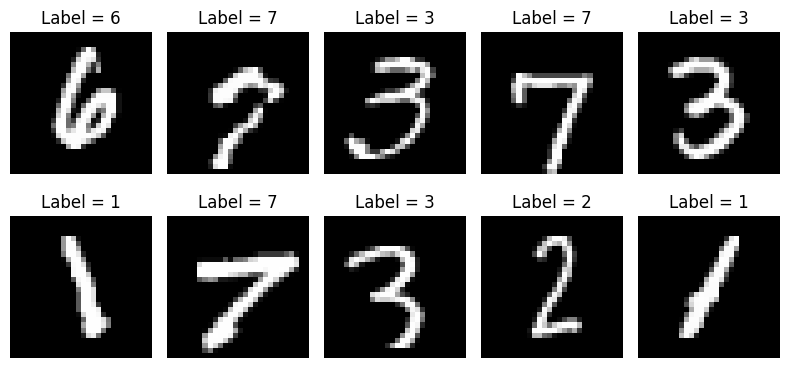

In [3]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label = {labels[i].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

# **Partie I — Modèle discriminatif**

# **2. Classification : apprendre \(P(y|x)\)**

Un classifieur reçoit une entrée \(x\) et prédit une classe \(y\).
$$
\
x \longrightarrow \text{Réseau de neurones} \longrightarrow \hat y
\
$$
L'objectif est d'apprendre approximativement :
$$
\
P(y|x)
\
$$
Nous allons utiliser un réseau entièrement connecté simple.

In [8]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)

classifier = Classifier().to(device)
classifier

Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

## Pourquoi commencer par `nn.Flatten()` ?

Parce que les images MNIST sont des **matrices de pixels**, alors que la première couche `nn.Linear(784, 128)` attend **784 valeurs par image dans la dernière dimension**.

### 1. La forme initiale des données

Un lot de `B` images MNIST possède généralement la forme :

```text
[B, 1, 28, 28]
 ↑  ↑   ↑   ↑
Lot Canal Hauteur Largeur
```

Chaque image contient :

$$
1 \times 28 \times 28 = 784 \text{ valeurs}
$$

### 2. Le rôle de `Flatten`

```python
nn.Flatten()
```

Cette couche transforme chaque image en un vecteur de 784 valeurs, tout en conservant la dimension du lot :

```text
[B, 1, 28, 28] → [B, 784]
```

Exemple simplifié avec une image de `2 × 2` pixels :

```text
Avant :                 Après :

[[0.1, 0.8],     →      [0.1, 0.8, 0.3, 0.9]
 [0.3, 0.9]]
```

> `Flatten` ne modifie pas les valeurs, ne compresse pas l’image et ne possède aucun paramètre à apprendre. Il change uniquement la forme des données.

### 3. Pourquoi est-ce nécessaire avant `Linear` ?

```python
nn.Linear(784, 128)
```

Cette couche combine les 784 pixels pour produire 128 caractéristiques apprises.

Sans `Flatten`, elle recevrait un tenseur dont la dernière dimension vaut `28`, et non `784` : cela provoquerait une erreur de dimensions.

Le parcours complet devient :

```text
Images                [B, 1, 28, 28]
   ↓ Flatten
Pixels aplatis        [B, 784]
   ↓ Linear(784, 128)
Caractéristiques      [B, 128]
   ↓ ReLU
Caractéristiques      [B, 128]
   ↓ Linear(128, 10)
Scores des classes    [B, 10]
```

Les dix scores finaux correspondent aux chiffres de `0` à `9`.

### 4. Commence-t-on toujours par `Flatten` ?

**Non, cela dépend de l’architecture.**

- **Réseau entièrement connecté, comme ici** : on aplatit l’image avant la première couche `Linear`.
- **Réseau convolutif (CNN)** : on conserve d’abord la forme `[B, canaux, hauteur, largeur]`, car les convolutions exploitent le voisinage entre les pixels.
- **Images déjà aplaties en `[B, 784]`** : `Flatten` n’est pas nécessaire.

L’aplatissement conserve toutes les valeurs, mais la couche entièrement connectée ne dispose pas du mécanisme des convolutions pour exploiter explicitement la structure spatiale de l’image.

**À retenir : ici, `Flatten` adapte la forme des images à l’entrée attendue par `Linear(784, 128)`.**

### Fonction de perte

Pour une classification multi-classe, nous utilisons :
$$
\
\mathcal{L}_{class} = CrossEntropy(\hat y, y)
\
$$

Le label est donc indispensable.

In [9]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)

In [10]:
def train_classifier(model, loader, epochs=3):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{epochs} - "
            f"Loss = {total_loss/len(loader):.4f}"
        )

train_classifier(classifier, train_loader, epochs=3)

Epoch 1/3 - Loss = 0.4156
Epoch 2/3 - Loss = 0.1952
Epoch 3/3 - Loss = 0.1428


In [11]:
def evaluate_classifier(model, loader):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            pred = logits.argmax(dim=1)

            correct += (pred == y).sum().item()
            total += y.size(0)

    return correct / total

accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy = {100*accuracy:.2f}%")

Accuracy = 96.02%


Une autre façon pour évaluer le modèle

In [12]:
from torcheval.metrics import MulticlassAccuracy

@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    device = next(model.parameters()).device

    metric = MulticlassAccuracy(device=device)

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        logits = model(x)
        metric.update(logits, y)

    return metric.compute().item()


accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy = {100 * accuracy:.2f}%")

Accuracy = 96.02%


Le réseau apprend ici :

x => y

Il **discrimine** les classes.

Il ne sait pas générer une nouvelle image de chiffre.

# **Partie II — Autoencodeur**

# **3. Idée générale**

Un autoencodeur apprend à reconstruire son entrée :

x \rightarrow Encoder \rightarrow z \rightarrow Decoder \rightarrow \hat x
 x -> Encoder -> z -> Decoder -> xhat

avec : xhat approxime x


Le vecteur z est une **représentation latente** de l'entrée.

L'apprentissage devient : x -> x

Les labels ne sont plus nécessaires.

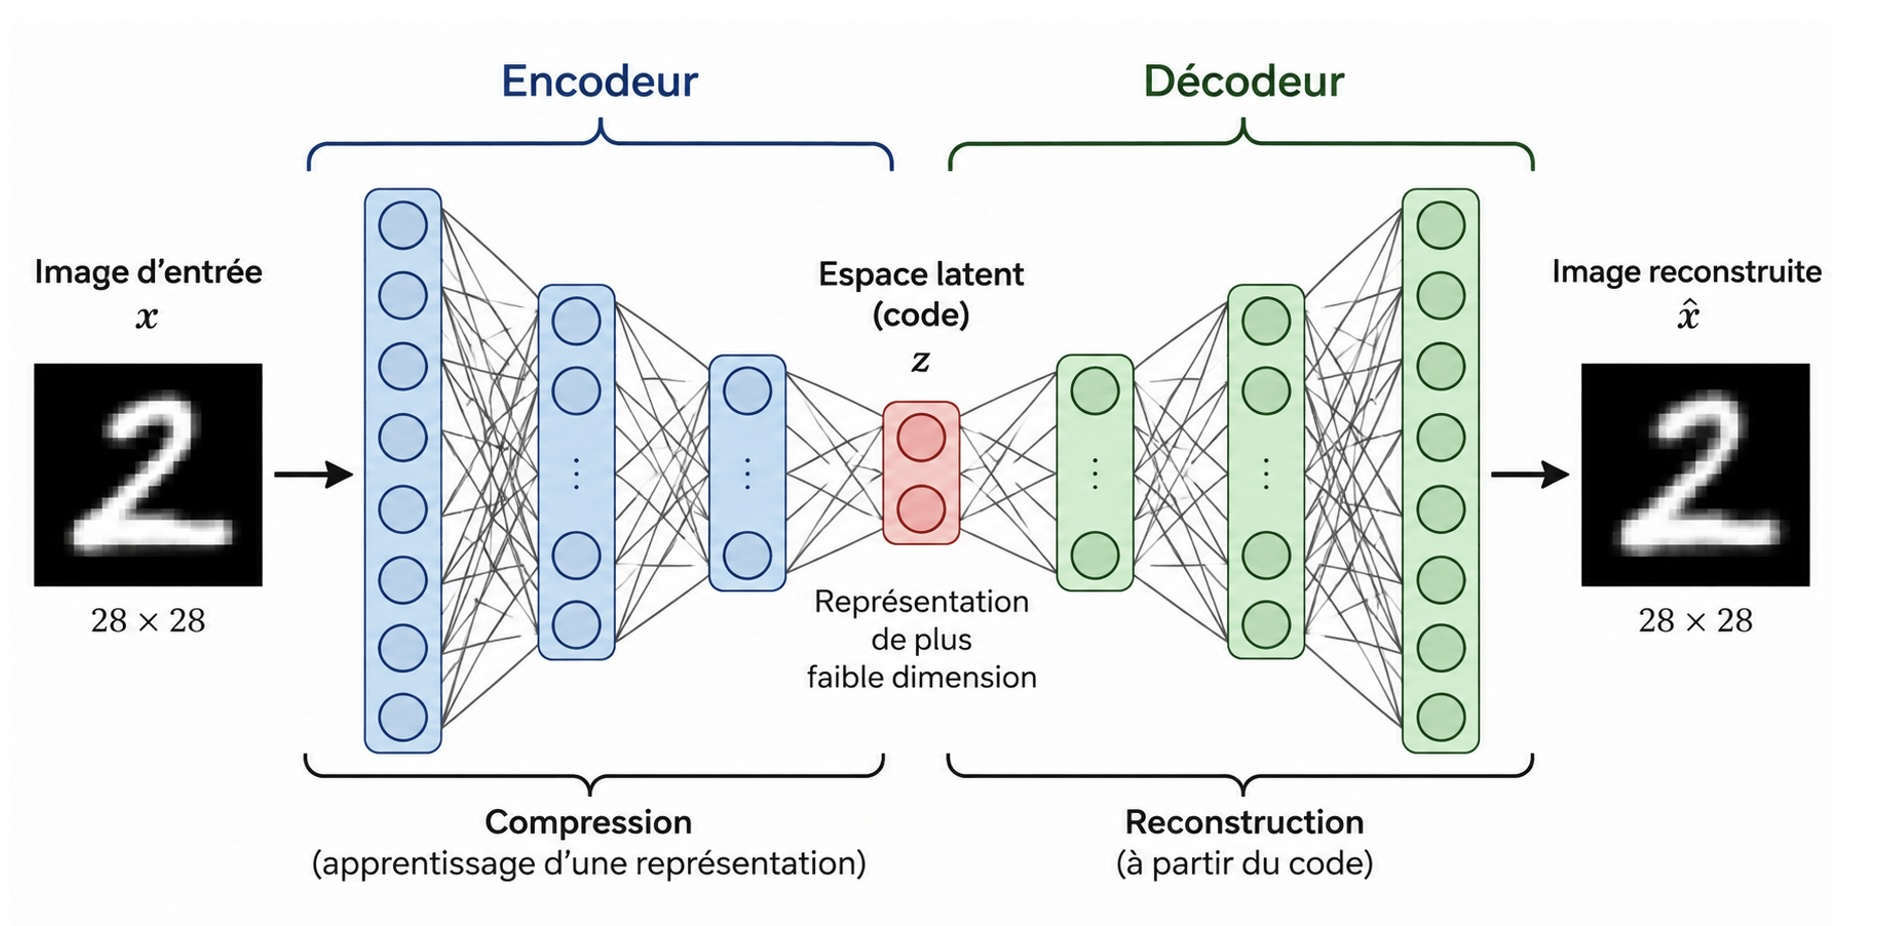

In [13]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        x_hat = self.decode(z)
        return x_hat

ae = Autoencoder(latent_dim=2).to(device)
ae

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

# **Comprendre ce code : un autoencodeur avec PyTorch**

Ce code définit un **autoencodeur** (*autoencoder*), un réseau de neurones qui apprend à **reconstruire ses données d’entrée après les avoir compressées**.

Ici, il est conçu pour des images en niveaux de gris de **28 × 28 pixels**, soit **784 valeurs par image**. C’est notamment le format des images du jeu de données MNIST.

Son fonctionnement se résume ainsi :

```text
Image d’origine        Représentation compacte        Image reconstruite
  28 × 28 pixels   →         2 nombres           →       28 × 28 pixels
                    Encodeur                    Décodeur
```

> **Idée importante :** le code construit le modèle, mais ne l’entraîne pas. Avant l’entraînement, ses reconstructions ne sont généralement pas pertinentes.

---

## 1. Définir la classe du modèle

```python
class Autoencoder(nn.Module):
```

Cette instruction crée une classe appelée `Autoencoder`, qui hérite de `nn.Module`.

Dans PyTorch, `nn.Module` est la classe de base des réseaux de neurones et de leurs composants. Elle fournit notamment les mécanismes permettant de :

- gérer les paramètres entraînables ;
- déplacer le modèle sur un CPU ou un GPU ;
- sauvegarder et charger ses paramètres ;
- utiliser le modèle avec la syntaxe `modele(x)`.

Le code suppose que `nn` a été importé :

```python
import torch
import torch.nn as nn
```

### Le constructeur

```python
def __init__(self, latent_dim=2):
    super().__init__()
```

La méthode `__init__` s’exécute à la création du modèle.

- **`self`** représente l’instance du modèle.
- **`latent_dim`** indique le nombre de valeurs utilisées pour représenter chaque image après compression.
- **`latent_dim=2`** fixe cette dimension à `2` par défaut.
- **`super().__init__()`** initialise la partie héritée de `nn.Module`, nécessaire au bon fonctionnement du modèle dans PyTorch.

Avec une dimension latente de `2`, l’encodeur doit apprendre à représenter chaque image par seulement **deux nombres**.

---

## 2. L’encodeur : compresser l’image

```python
self.encoder = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128),
    nn.ReLU(),
    nn.Linear(128, 32),
    nn.ReLU(),
    nn.Linear(32, latent_dim)
)
```

L’encodeur transforme l’image en une représentation compacte, appelée **vecteur latent**, généralement notée `z`.

### À quoi sert `nn.Sequential` ?

`nn.Sequential` regroupe des couches et les applique **dans l’ordre où elles sont déclarées**.

```text
Entrée → Couche 1 → Couche 2 → ... → Sortie
```

La sortie de chaque couche devient l’entrée de la suivante.

### Étape 1 — Aplatir l’image

```python
nn.Flatten()
```

Une image de `28 × 28` pixels contient :

```text
28 × 28 = 784 valeurs
```

`Flatten` transforme cette image en un vecteur de `784` valeurs.

En pratique, PyTorch traite souvent plusieurs images à la fois, regroupées dans un **lot**, ou *batch*. Si `B` désigne le nombre d’images du lot :

```text
Avant : [B, 1, 28, 28]
Après : [B, 784]
```

Les dimensions initiales représentent :

| Dimension | Signification |
|---|---|
| `B` | Nombre d’images |
| `1` | Nombre de canaux : un seul pour le niveau de gris |
| `28` | Hauteur |
| `28` | Largeur |

Par défaut, `nn.Flatten()` conserve la première dimension — celle du lot — et aplatit les suivantes.

> Cette opération ne réalise pas encore de compression : elle change uniquement la forme des données.

### Étape 2 — Passer de 784 à 128 valeurs

```python
nn.Linear(784, 128)
```

Cette couche est une **couche entièrement connectée** : chacune de ses `128` valeurs de sortie dépend des `784` valeurs d’entrée.

Elle applique une transformation de la forme :

$$
y = Wx + b
$$

où :

- $x$ est le vecteur d’entrée ;
- $W$ contient les poids appris ;
- $b$ contient les biais appris ;
- $y$ est le vecteur de sortie.

La forme des données devient :

```text
[B, 784] → [B, 128]
```

Les valeurs produites ne sont plus directement des pixels : ce sont des **caractéristiques apprises**.

### Étape 3 — Appliquer ReLU

```python
nn.ReLU()
```

ReLU est une fonction d’activation définie par :

$$
\operatorname{ReLU}(x) = \max(0, x)
$$

Elle remplace les valeurs négatives par zéro et conserve les autres :

```text
Entrée : [-3, -1, 0, 2, 5]
Sortie : [ 0,  0, 0, 2, 5]
```

Elle introduit une **non-linéarité**, qui permet au réseau d’apprendre des transformations plus complexes.

Sans fonction d’activation entre les couches `Linear`, leur succession serait équivalente à une seule transformation affine.

ReLU ne change pas la forme des données :

```text
[B, 128] → [B, 128]
```

### Étape 4 — Réduire à 32 valeurs

```python
nn.Linear(128, 32),
nn.ReLU(),
```

Le même principe est répété :

1. une couche apprend à transformer `128` valeurs en `32` valeurs ;
2. ReLU introduit une non-linéarité.

```text
[B, 128] → [B, 32]
```

### Étape 5 — Produire le vecteur latent

```python
nn.Linear(32, latent_dim)
```

Cette dernière couche produit la représentation compacte.

Avec `latent_dim=2` :

```text
[B, 32] → [B, 2]
```

Chaque image est donc représentée par un vecteur tel que :

```python
z = [0.7, -1.2]
```

Ces deux valeurs sont **apprises par le modèle**. Elles ne correspondent pas nécessairement à des propriétés faciles à nommer.

Il n’y a pas de fonction d’activation après cette couche : les coordonnées latentes ne sont donc pas contraintes à être positives ou comprises entre `0` et `1`.

### Bilan de l’encodeur

```text
[B, 1, 28, 28]
       ↓ Flatten
   [B, 784]
       ↓ Linear + ReLU
   [B, 128]
       ↓ Linear + ReLU
    [B, 32]
       ↓ Linear
     [B, 2]  ← vecteur latent z
```

---

## 3. Le décodeur : reconstruire l’image

```python
self.decoder = nn.Sequential(
    nn.Linear(latent_dim, 32),
    nn.ReLU(),
    nn.Linear(32, 128),
    nn.ReLU(),
    nn.Linear(128, 784),
    nn.Sigmoid()
)
```

Le décodeur reçoit le vecteur latent et tente de reconstruire l’image d’origine.

Il suit une progression opposée à celle de l’encodeur :

```text
2 valeurs → 32 valeurs → 128 valeurs → 784 valeurs
```

Les couches `Linear` et `ReLU` jouent les mêmes rôles que précédemment.

> Le décodeur n’est pas l’inverse mathématique exact de l’encodeur. Il apprend une reconstruction approximative à partir de la représentation compressée.

### Pourquoi terminer par `Sigmoid` ?

```python
nn.Sigmoid()
```

La fonction sigmoïde transforme chaque valeur en une valeur comprise entre `0` et `1` :

$$
\sigma(x) = \frac{1}{1 + e^{-x}}
$$

Elle convient ici si les pixels des images d’entrée ont été **ramenés dans l’intervalle `[0, 1]`** :

- `0` représente le noir ;
- `1` représente le blanc ;
- les valeurs intermédiaires représentent des nuances de gris.

> La sigmoïde contraint les valeurs de sortie, mais ne normalise pas les images d’entrée. Leur préparation doit être faite séparément.

### Bilan du décodeur

```text
     [B, 2]
       ↓ Linear + ReLU
    [B, 32]
       ↓ Linear + ReLU
   [B, 128]
       ↓ Linear + Sigmoid
   [B, 784]
```

À ce stade, chaque reconstruction est encore un vecteur de `784` valeurs.

---

## 4. La méthode `encode`

```python
def encode(self, x):
    return self.encoder(x)
```

Cette méthode applique simplement l’encodeur à l’entrée `x`.

```python
z = ae.encode(x)
```

Elle permet d’obtenir les représentations latentes **sans reconstruire les images**.

Avec un lot de `64` images et `latent_dim=2` :

```text
x : [64, 1, 28, 28]
z : [64, 2]
```

Une dimension latente de `2` est notamment pratique pour visualiser les représentations : chaque image peut être placée comme un point dans un graphique à deux axes.

---

## 5. La méthode `decode`

```python
def decode(self, z):
    x_hat = self.decoder(z)
    return x_hat.view(-1, 1, 28, 28)
```

Elle reconstruit les images à partir des vecteurs latents.

### Produire les pixels

```python
x_hat = self.decoder(z)
```

Le décodeur renvoie un tenseur de forme :

```text
[B, 784]
```

Le nom `x_hat`, qui se lit « x chapeau » et se note $\hat{x}$, désigne une **estimation de l’entrée `x`**.

### Retrouver la forme d’une image

```python
x_hat.view(-1, 1, 28, 28)
```

`view` réorganise la forme du tenseur sans changer ses valeurs.

```text
[B, 784] → [B, 1, 28, 28]
```

Les arguments signifient :

| Argument | Signification |
|---|---|
| `-1` | PyTorch calcule automatiquement cette dimension |
| `1` | Un canal |
| `28` | Hauteur |
| `28` | Largeur |

Ici, la dimension calculée automatiquement correspond au nombre d’images du lot.

Par exemple :

```text
[64, 784] → [64, 1, 28, 28]
```

C’est possible parce que le nombre total de valeurs reste identique :

$$
64 \times 784 = 64 \times 1 \times 28 \times 28
$$

---

## 6. La méthode `forward` : le trajet complet

```python
def forward(self, x):
    z = self.encode(x)
    x_hat = self.decode(z)
    return x_hat
```

`forward` décrit ce que fait le modèle lorsqu’il reçoit une entrée :

1. **encoder** l’image pour obtenir `z` ;
2. **décoder** `z` pour obtenir `x_hat` ;
3. renvoyer l’image reconstruite.

```text
x → encode(x) → z → decode(z) → x_hat
```

Avec PyTorch, on utilise normalement :

```python
x_hat = ae(x)
```

Cet appel passe par les mécanismes de `nn.Module`, qui exécutent ensuite `forward`.

> `forward` définit le calcul, pas l’apprentissage. À lui seul, cet appel ne modifie pas les poids du réseau.

---

## 7. Créer le modèle et choisir où il s’exécute

```python
ae = Autoencoder(latent_dim=2).to(device)
```

Cette ligne effectue deux opérations.

### Créer l’autoencodeur

```python
Autoencoder(latent_dim=2)
```

Cela construit un modèle dont le vecteur latent contient deux valeurs par image.

### Déplacer le modèle sur le périphérique choisi

```python
.to(device)
```

`device` doit avoir été défini auparavant. Par exemple :

```python
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
```

- `"cuda"` désigne un GPU compatible CUDA ;
- `"cpu"` désigne le processeur.

Les données doivent être placées sur le même périphérique que le modèle :

```python
x = x.to(device)
x_hat = ae(x)
```

### Que fait la dernière ligne `ae` ?

```python
ae
```

Dans un notebook Jupyter ou un environnement interactif, elle affiche généralement la structure du modèle.

Dans un script Python classique, il faut écrire :

```python
print(ae)
```

Cette ligne n’entraîne pas le modèle et ne lui transmet aucune image.

---

## 8. Comment ce modèle apprend-il ?

L’apprentissage n’apparaît pas dans le code fourni.

Pour entraîner un autoencodeur, on compare sa reconstruction à l’image d’entrée :

```text
Image x → Autoencodeur → Reconstruction x_hat
   │                           │
   └──────── Comparaison ───────┘
                 ↓
        Erreur de reconstruction
```

On peut, par exemple, utiliser l’erreur quadratique moyenne :

```python
criterion = nn.MSELoss()
loss = criterion(x_hat, x)
```

Puis on calcule les gradients et on ajuste les paramètres à l’aide d’un optimiseur défini au préalable :

```python
optimizer.zero_grad()
loss.backward()
optimizer.step()
```

Ces étapes sont répétées sur de nombreux lots d’images.

**L’entrée sert elle-même de cible** : le modèle cherche à produire une sortie aussi proche que possible de cette entrée. Il n’a donc pas besoin d’étiquettes comme « chiffre 3 » ou « chiffre 7 » pour cet objectif de reconstruction.

Avec seulement deux valeurs latentes, la compression est très forte. Le réseau doit apprendre à conserver les informations les plus utiles pour reconstruire les images, mais une reconstruction parfaite n’est pas garantie.

---

## 9. Exemple pour vérifier les dimensions

En supposant la classe déjà définie :

```python
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ae = Autoencoder(latent_dim=2).to(device)

# Lot de 4 images aléatoires, utilisées uniquement pour tester le modèle.
x = torch.rand(4, 1, 28, 28, device=device)

with torch.no_grad():
    z = ae.encode(x)
    x_hat = ae(x)

print("Entrée :", x.shape)
print("Représentation latente :", z.shape)
print("Reconstruction :", x_hat.shape)
```

Résultat :

```text
Entrée : torch.Size([4, 1, 28, 28])
Représentation latente : torch.Size([4, 2])
Reconstruction : torch.Size([4, 1, 28, 28])
```

`torch.no_grad()` désactive le calcul des gradients, inutile pour cette simple vérification.

---

## À retenir

| Élément | Rôle |
|---|---|
| `Autoencoder` | Définit le réseau complet |
| `encoder` | Compresse chaque image |
| `latent_dim` | Fixe la taille de la représentation compacte |
| `decoder` | Reconstruit l’image à partir de cette représentation |
| `Flatten` | Transforme l’image en vecteur |
| `Linear` | Apprend une transformation des valeurs |
| `ReLU` | Introduit une non-linéarité |
| `Sigmoid` | Ramène les sorties entre `0` et `1` |
| `view` | Redonne aux sorties une forme d’image |
| `forward` | Enchaîne encodage et décodage |
| `.to(device)` | Place le modèle sur CPU ou GPU |

**En une phrase : ce modèle apprend à résumer une image de 784 pixels par deux nombres, puis à reconstruire une image à partir de ce résumé.**

# **4. Loss de reconstruction**

Nous utilisons ici :
$$
\
\mathcal{L}_{rec}=\frac{1}{N}\sum_{i=1}^{N}(x_i-\hat{x}_i)^2
\
$$
avec `MSELoss`.

In [14]:
ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)
def train_autoencoder(model, loader, epochs=5):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, _ in loader:
            x = x.to(device)

            x_hat = model(x)
            loss = ae_criterion(x_hat, x)

            ae_optimizer.zero_grad()
            loss.backward()
            ae_optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{epochs} - "
            f"Loss = {total_loss/len(loader):.4f}"
        )

train_autoencoder(ae, train_loader, epochs=5)

Epoch 1/5 - Loss = 0.0671
Epoch 2/5 - Loss = 0.0530
Epoch 3/5 - Loss = 0.0505
Epoch 4/5 - Loss = 0.0479
Epoch 5/5 - Loss = 0.0461


# Comprendre l’entraînement d’un autoencodeur avec PyTorch

Ce code entraîne l’autoencodeur `ae` pour qu’il apprenne à **reconstruire les images qu’on lui donne en entrée**.

Le principe est le suivant :

```text
Image d’entrée x
       ↓
  Autoencodeur
       ↓
Image reconstruite x_hat
       ↓
Comparaison avec l’image d’entrée
       ↓
Calcul de l’erreur
       ↓
Ajustement des paramètres du réseau
```

Au fil de l’entraînement, le modèle cherche à produire des reconstructions de plus en plus proches des images originales.

> **Différence essentielle :** définir un réseau crée son architecture. L’entraîner consiste à ajuster ses poids et ses biais à partir des données.

---

## 1. Définir la fonction de perte

```python
ae_criterion = nn.MSELoss()
```

Cette ligne crée la **fonction de perte**, aussi appelée *loss function*.

Son rôle est de mesurer l’écart entre :

- l’image originale `x` ;
- l’image reconstruite `x_hat`.

### Que signifie MSE ?

MSE signifie **Mean Squared Error**, soit **erreur quadratique moyenne**.

Son calcul consiste à :

1. calculer la différence entre chaque valeur reconstruite et la valeur originale ;
2. élever chaque différence au carré ;
3. calculer la moyenne de ces carrés.

Mathématiquement :

$$
\mathcal{L}
=
\frac{1}{N}
\sum_{i=1}^{N}
(\hat{x}_i - x_i)^2
$$

où :

- $x_i$ est une valeur de l’image originale ;
- $\hat{x}_i$ est la valeur correspondante dans la reconstruction ;
- $N$ est le nombre total de valeurs comparées.

Par défaut, `nn.MSELoss()` calcule la moyenne sur **tous les éléments du tenseur**, donc sur tous les pixels de toutes les images du lot.

Pour un lot de `B` images en niveaux de gris de `28 × 28` pixels :

$$
N = B \times 1 \times 28 \times 28
$$

### Exemple simplifié

Supposons que l’on compare seulement trois valeurs :

```text
Valeurs originales    : [0.0, 0.5, 1.0]
Valeurs reconstruites  : [0.1, 0.4, 0.8]
```

Les différences sont :

```text
[0.1, -0.1, -0.2]
```

Leurs carrés sont :

```text
[0.01, 0.01, 0.04]
```

La moyenne vaut :

$$
\mathrm{MSE}
=
\frac{0.01 + 0.01 + 0.04}{3}
=
0.02
$$

### Comment interpréter cette perte ?

- **Perte faible** : les reconstructions sont proches des images originales, selon cette mesure.
- **Perte élevée** : les reconstructions s’en éloignent davantage.
- **Perte nulle** : toutes les valeurs comparées sont identiques.

> Une faible MSE ne garantit pas à elle seule une excellente qualité visuelle. Elle mesure une proximité pixel par pixel.

---

## 2. Définir l’optimiseur

```python
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)
```

L’optimiseur est l’outil qui **modifie les paramètres du réseau pour chercher à réduire la perte**.

Ici, on utilise **Adam**, un algorithme d’optimisation courant en apprentissage profond.

### Quels paramètres sont modifiés ?

```python
ae.parameters()
```

Cette expression fournit les paramètres du modèle `ae`, notamment :

- les poids des couches `Linear` ;
- les biais de ces couches.

Dans cet autoencodeur, l’optimiseur agit sur les paramètres de **l’encodeur et du décodeur**.

Les couches comme `ReLU`, `Flatten` et `Sigmoid` ne possèdent pas de paramètres entraînables.

### Que signifie `lr=1e-3` ?

`lr` signifie **learning rate**, ou **taux d’apprentissage**.

```python
1e-3 = 0.001
```

Le taux d’apprentissage contrôle l’échelle des ajustements effectués sur les paramètres.

- Un taux trop grand peut rendre l’apprentissage instable.
- Un taux trop petit peut ralentir l’apprentissage.

Adam adapte aussi les mises à jour de chaque paramètre à partir d’informations accumulées sur les gradients.

> **À distinguer :** la fonction de perte mesure l’erreur ; l’optimiseur ajuste les paramètres à partir des gradients de cette erreur.

---

## 3. Définir la fonction d’entraînement

```python
def train_autoencoder(model, loader, epochs=5):
```

Cette fonction regroupe les étapes nécessaires à l’entraînement.

Elle reçoit trois arguments :

| Argument | Rôle |
|---|---|
| `model` | Modèle à entraîner |
| `loader` | Objet fournissant les données par lots |
| `epochs` | Nombre de passages complets sur les données |

La valeur `epochs=5` signifie que, si aucun autre nombre n’est précisé, la fonction effectuera **cinq époques**.

### Qu’est-ce qu’un lot ?

Un **lot**, ou *batch*, est un groupe d’exemples traités ensemble.

Par exemple, un lot de `64` images de `28 × 28` pixels possède généralement la forme :

```text
[64, 1, 28, 28]
```

Le regroupement en lots permet notamment de profiter efficacement des capacités de calcul du matériel.

### Qu’est-ce qu’une époque ?

Une **époque** correspond ici à un passage complet sur les lots fournis par `loader`.

Avec un chargeur classique parcourant tout le jeu d’entraînement, cela revient à parcourir l’ensemble des images une fois.

```text
Époque 1 : lot 1 → lot 2 → ... → dernier lot
Époque 2 : lot 1 → lot 2 → ... → dernier lot
...
```

> Une époque contient généralement plusieurs mises à jour des paramètres : une mise à jour par lot.

---

## 4. Activer le mode entraînement

```python
model.train()
```

Cette instruction place le modèle en **mode entraînement**.

Certaines couches se comportent différemment selon que l’on entraîne le modèle ou que l’on l’évalue :

- `Dropout` désactive aléatoirement certaines activations pendant l’entraînement ;
- `BatchNorm` adapte son comportement et ses statistiques.

Dans l’autoencodeur présenté précédemment, les couches utilisées ne changent pas de comportement entre les modes entraînement et évaluation. Cet appel reste néanmoins une bonne pratique.

> `model.train()` ne lance pas l’apprentissage et n’active pas à lui seul le calcul des gradients. Il configure le mode du modèle.

---

## 5. Parcourir les époques

```python
for epoch in range(epochs):
    total_loss = 0
```

Cette boucle répète l’entraînement pendant le nombre d’époques demandé.

Avec `epochs=5`, `epoch` prend successivement les valeurs :

```text
0, 1, 2, 3, 4
```

### À quoi sert `total_loss` ?

```python
total_loss = 0
```

Cette variable accumule les pertes des différents lots pour afficher un résumé à la fin de l’époque.

Elle est remise à zéro au début de chaque époque.

> `total_loss` sert uniquement au suivi de l’entraînement. Ce n’est pas cette variable qui est utilisée pour calculer les gradients.

---

## 6. Récupérer les lots d’images

```python
for x, _ in loader:
```

Cette boucle récupère successivement les lots produits par `loader`.

Pour un jeu de données comme MNIST, chaque lot contient habituellement :

```python
(images, etiquettes)
```

Dans le code :

- `x` reçoit les images ;
- `_` reçoit les étiquettes, que l’on n’utilise pas.

### Pourquoi ignorer les étiquettes ?

Dans une tâche de classification, l’étiquette indique par exemple :

```text
Cette image représente le chiffre 7.
```

Mais ici, le modèle ne cherche pas à prédire le chiffre. Il cherche à **reconstruire l’image elle-même**.

La cible est donc `x`, et non l’étiquette associée.

```text
Classification : image → numéro du chiffre
Autoencodeur   : image → reconstruction de l’image
```

Le nom `_` est une convention Python indiquant qu’une valeur est volontairement ignorée.

---

## 7. Placer les images sur le bon périphérique

```python
x = x.to(device)
```

Cette instruction déplace le lot d’images sur le périphérique indiqué par `device`.

Par exemple :

```python
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
```

- `cuda` : utilisation d’un GPU compatible CUDA ;
- `cpu` : utilisation du processeur.

Les données et le modèle doivent se trouver sur le même périphérique.

```text
Modèle sur GPU → images sur le même GPU
Modèle sur CPU → images sur CPU
```

> Le code suppose que le modèle a déjà été déplacé avec une instruction comme `ae.to(device)`.

---

## 8. Reconstruire les images : le passage avant

```python
x_hat = model(x)
```

Cette ligne transmet le lot d’images au modèle.

PyTorch exécute alors sa méthode `forward`.

Pour l’autoencodeur étudié :

```python
def forward(self, x):
    z = self.encode(x)
    x_hat = self.decode(z)
    return x_hat
```

Le chemin suivi est donc :

```text
x → encodeur → z → décodeur → x_hat
```

Avec un lot de `64` images et une dimension latente de `2` :

```text
x     : [64, 1, 28, 28]
z     : [64, 2]
x_hat : [64, 1, 28, 28]
```

Cette étape est appelée **passage avant**, ou *forward pass*.

Pendant ce calcul, PyTorch construit le graphe des opérations nécessaire au calcul ultérieur des gradients.

---

## 9. Calculer l’erreur de reconstruction

```python
loss = ae_criterion(x_hat, x)
```

Cette ligne compare :

- `x_hat` : la reconstruction produite par le modèle ;
- `x` : l’image originale, utilisée comme cible.

Le résultat `loss` est un tenseur scalaire : il contient une seule valeur.

Par exemple :

```text
loss = 0.0837
```

Ce tenseur reste relié au graphe de calcul. PyTorch peut donc déterminer comment la perte dépend des paramètres du modèle.

> On calcule les gradients à partir de `loss`, et non de `loss.item()`, car `loss.item()` produit un simple nombre Python sans lien avec le graphe de calcul.

---

## 10. Remettre les gradients à zéro

```python
ae_optimizer.zero_grad()
```

Avant de calculer les gradients du lot courant, on efface ceux de l’étape précédente.

### Pourquoi est-ce nécessaire ?

Par défaut, PyTorch **accumule les gradients** à chaque appel de `backward()`.

Sans remise à zéro, les gradients du lot courant s’ajouteraient à ceux des lots précédents.

Dans cette boucle, on souhaite une mise à jour fondée uniquement sur le lot courant.

```text
Effacer les anciens gradients
             ↓
Calculer les nouveaux gradients
             ↓
Mettre à jour les paramètres
```

> Cette instruction remet à zéro, ou réinitialise à `None` selon les options, les gradients associés aux paramètres. Elle ne remet pas les poids du réseau à zéro.

Dans ce code, `zero_grad()` est appelé après le passage avant. C’est correct : l’important ici est de l’appeler avant `loss.backward()`.

---

## 11. Calculer les gradients : la rétropropagation

```python
loss.backward()
```

Cette instruction déclenche la **rétropropagation**, ou *backpropagation*.

PyTorch calcule comment la perte varie en fonction de chaque paramètre entraînable du modèle.

Pour un paramètre $\theta$, on cherche notamment :

$$
\frac{\partial \mathcal{L}}{\partial \theta}
$$

Cette dérivée indique la sensibilité de la perte à une petite modification du paramètre.

### Intuition

Pour un paramètre donné :

- un gradient positif indique qu’une petite augmentation du paramètre tend à augmenter la perte ;
- un gradient négatif indique qu’une petite augmentation tend à diminuer la perte.

Ces informations permettent à l’optimiseur de choisir les ajustements à effectuer.

Les gradients se propagent à travers tout le réseau :

```text
Perte → Décodeur → Représentation latente → Encodeur
```

Ainsi, **l’encodeur et le décodeur apprennent ensemble**.

> `loss.backward()` calcule les gradients, mais ne met pas encore les paramètres à jour.

---

## 12. Mettre à jour les paramètres

```python
ae_optimizer.step()
```

Cette instruction demande à Adam d’utiliser les gradients calculés pour modifier les paramètres du modèle.

Pour comprendre l’idée générale, une descente de gradient simple utiliserait une formule comme :

$$
\theta_{\text{nouveau}}
=
\theta_{\text{ancien}}
-
\eta \frac{\partial \mathcal{L}}{\partial \theta}
$$

où $\eta$ représente le taux d’apprentissage.

Adam utilise une règle plus élaborée, qui tient compte de l’historique des gradients.

### Les trois instructions essentielles

```python
ae_optimizer.zero_grad()
loss.backward()
ae_optimizer.step()
```

| Instruction | Rôle |
|---|---|
| `zero_grad()` | Effacer les anciens gradients |
| `backward()` | Calculer les gradients du lot courant |
| `step()` | Modifier les paramètres à partir de ces gradients |

> Une mise à jour cherche à améliorer le modèle, mais ne garantit pas que la perte diminue à chaque lot.

---

## 13. Accumuler la perte pour le suivi

```python
total_loss += loss.item()
```

### Que fait `loss.item()` ?

`loss` est un tenseur PyTorch contenant une seule valeur.

`loss.item()` extrait cette valeur sous forme d’un nombre Python :

```python
# Exemple conceptuel
loss         # tenseur contenant 0.0837
loss.item()  # nombre Python : 0.0837
```

On ajoute ensuite cette valeur à `total_loss`.

### Exemple

Si une époque contient trois lots dont les pertes sont :

```text
Lot 1 : 0.12
Lot 2 : 0.09
Lot 3 : 0.06
```

Alors :

```text
total_loss = 0.12 + 0.09 + 0.06 = 0.27
```

La moyenne des pertes des lots vaut :

```text
0.27 / 3 = 0.09
```

La perte enregistrée correspond au passage avant effectué **avant la mise à jour des paramètres de ce lot**. `step()` ne recalcule pas automatiquement cette perte.

---

## 14. Afficher le résultat de l’époque

```python
print(
    f"Epoch {epoch+1}/{epochs} - "
    f"Loss = {total_loss/len(loader):.4f}"
)
```

Cette instruction affiche le numéro de l’époque et la moyenne des pertes des lots.

### Pourquoi `epoch + 1` ?

La variable `epoch` commence à `0`, mais on préfère afficher les époques à partir de `1`.

```text
epoch = 0 → affichage : Epoch 1/5
epoch = 1 → affichage : Epoch 2/5
```

### Que représente `len(loader)` ?

Dans un `DataLoader` classique, `len(loader)` correspond au **nombre de lots**, et non au nombre d’images.

Ainsi :

```python
total_loss / len(loader)
```

calcule la moyenne des pertes des lots.

### Une nuance sur cette moyenne

Si tous les lots ont le même nombre d’images, cette moyenne correspond aussi à la moyenne de l’erreur sur l’ensemble des pixels parcourus.

Si le dernier lot est plus petit, chaque lot garde ici le même poids dans la moyenne : le petit lot compte autant qu’un grand.

Pour obtenir une moyenne pondérée par le nombre d’images, on pourrait utiliser :

```python
total_loss += loss.item() * x.size(0)
total_images += x.size(0)

# À la fin de l’époque :
mean_loss = total_loss / total_images
```

Il faudrait alors initialiser `total_images = 0` au début de chaque époque. Cette pondération convient ici puisque toutes les images ont la même taille.

### Que signifie `:.4f` ?

C’est une instruction de formatage qui affiche le nombre avec **quatre chiffres après la virgule**.

```text
0.083726 → 0.0837
```

### Pourquoi deux chaînes `f"..."` ?

Python concatène automatiquement ces deux chaînes placées côte à côte :

```python
f"Epoch {epoch+1}/{epochs} - "
f"Loss = {total_loss/len(loader):.4f}"
```

Elles forment donc une seule ligne de texte.

Exemple d’affichage fictif :

```text
Epoch 1/5 - Loss = 0.0653
Epoch 2/5 - Loss = 0.0521
Epoch 3/5 - Loss = 0.0478
Epoch 4/5 - Loss = 0.0452
Epoch 5/5 - Loss = 0.0439
```

> Ces nombres sont illustratifs. Les résultats réels dépendent notamment des données, de l’initialisation et des réglages de l’entraînement.

---

## 15. Lancer l’entraînement

```python
train_autoencoder(ae, train_loader, epochs=5)
```

Cette ligne appelle la fonction avec :

| Argument transmis | Signification |
|---|---|
| `ae` | L’autoencodeur à entraîner |
| `train_loader` | Le chargeur des données d’entraînement |
| `epochs=5` | Cinq passages sur les lots d’entraînement |

Si `train_loader` contient `100` lots, le nombre total de mises à jour sera :

$$
5 \times 100 = 500
$$

Le modèle `ae` est modifié directement pendant l’entraînement.

La fonction n’a pas besoin de renvoyer le modèle pour que ses nouveaux paramètres soient conservés.

Comme elle ne contient pas de `return`, sa valeur de retour est `None`.

---

## 16. Attention : l’optimiseur est lié à `ae`

La fonction reçoit un argument `model` :

```python
def train_autoencoder(model, loader, epochs=5):
```

Mais elle utilise un optimiseur créé à l’extérieur :

```python
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)
```

Cet optimiseur est donc lié aux paramètres de **`ae`**, pas automatiquement à ceux de n’importe quel modèle fourni à la fonction.

L’appel suivant est cohérent :

```python
train_autoencoder(ae, train_loader, epochs=5)
```

En revanche, si l’on fournit un autre modèle, l’optimiseur restera lié à `ae` et ne mettra pas à jour les paramètres de cet autre modèle comme souhaité.

### Comment rendre la fonction plus réutilisable ?

On peut passer explicitement l’optimiseur, la fonction de perte et le périphérique :

```python
def train_autoencoder(model, loader, criterion, optimizer, device, epochs=5):
    ...
```

Puis appeler :

```python
train_autoencoder(
    ae,
    train_loader,
    ae_criterion,
    ae_optimizer,
    device,
    epochs=5
)
```

> Dans la version d’origine, `ae_criterion`, `ae_optimizer` et `device` sont des variables définies à l’extérieur de la fonction.

---

## 17. Ce que ce code ne fait pas encore

Cette boucle réalise l’entraînement, mais elle ne contient pas :

- d’évaluation sur un jeu de validation ou de test ;
- d’affichage des images reconstruites ;
- de sauvegarde du modèle ;
- d’historique des pertes renvoyé par la fonction.

Une diminution de la perte d’entraînement indique que le modèle reconstruit mieux les données utilisées pendant l’apprentissage, selon la MSE.

Elle ne suffit pas à garantir de bonnes reconstructions sur de nouvelles images.

Pour évaluer le modèle, on utilise généralement :

```python
ae.eval()

with torch.no_grad():
    x_hat = ae(x)
```

- `eval()` active le mode évaluation ;
- `torch.no_grad()` désactive le calcul des gradients.

Les données d’évaluation doivent elles aussi être placées sur le bon périphérique.

---

## 18. Vue d’ensemble d’une itération

Pour chaque lot, les opérations sont les suivantes :

```text
1. Charger un lot d’images
              ↓
2. Déplacer les images sur CPU ou GPU
              ↓
3. Reconstruire les images : x_hat = model(x)
              ↓
4. Calculer la perte : MSE(x_hat, x)
              ↓
5. Effacer les anciens gradients
              ↓
6. Calculer les nouveaux gradients
              ↓
7. Mettre à jour les paramètres
              ↓
8. Enregistrer la perte pour le suivi
```

Ces étapes sont répétées pour tous les lots, puis pour toutes les époques.

---

## À retenir

| Élément | Rôle |
|---|---|
| `nn.MSELoss()` | Mesurer l’erreur de reconstruction |
| `torch.optim.Adam(...)` | Définir la méthode de mise à jour des paramètres |
| `ae.parameters()` | Fournir les paramètres à optimiser |
| `lr=1e-3` | Fixer le taux d’apprentissage à `0.001` |
| `model.train()` | Activer le mode entraînement |
| `for epoch in range(epochs)` | Répéter les passages sur les données |
| `for x, _ in loader` | Récupérer les images et ignorer les étiquettes |
| `x.to(device)` | Placer les images sur le bon périphérique |
| `model(x)` | Produire les reconstructions |
| `ae_criterion(x_hat, x)` | Comparer les reconstructions aux originaux |
| `zero_grad()` | Effacer les anciens gradients |
| `loss.backward()` | Calculer les gradients |
| `optimizer.step()` | Ajuster les paramètres |
| `loss.item()` | Extraire la valeur numérique de la perte |
| `total_loss / len(loader)` | Calculer la moyenne des pertes des lots |

**En une phrase : ce code apprend à l’autoencodeur à reconstruire les images en mesurant ses erreurs, puis en ajustant ses paramètres lot après lot pendant cinq époques.**

# **5. Visualisation des reconstructions**

La première ligne montre les images originales.

La deuxième ligne montre les images reconstruites.

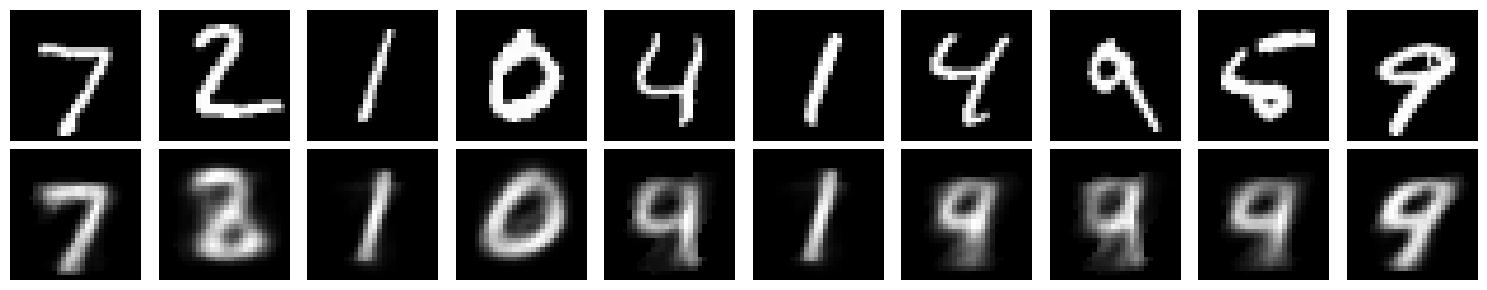

In [15]:
ae.eval()

x, _ = next(iter(test_loader))
x = x[:10].to(device)

with torch.no_grad():
    x_hat = ae(x)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstruit")

plt.tight_layout()
plt.show()

# Visualiser les reconstructions d’un autoencodeur

Ce code permet de **comparer visuellement des images originales avec les reconstructions produites par l’autoencodeur**.

Il affiche une grille de deux lignes et dix colonnes :

- **première ligne** : les images originales ;
- **deuxième ligne** : les images reconstruites.

```text
                  Image 1   Image 2   Image 3   ...   Image 10

Originales           ↓         ↓         ↓               ↓
                  [image]   [image]   [image]    ...   [image]

Reconstructions      ↓         ↓         ↓               ↓
                  [image]   [image]   [image]    ...   [image]
```

Chaque colonne permet de comparer une image avec sa reconstruction.

> Ce code ne réalise aucun apprentissage : il utilise les paramètres actuels du modèle pour produire et afficher des reconstructions.

---

## 1. Passer le modèle en mode évaluation

```python
ae.eval()
```

Cette instruction place l’autoencodeur `ae` en **mode évaluation**.

Certaines couches fonctionnent différemment pendant l’entraînement et l’évaluation :

| Couche | Pendant l’entraînement | Pendant l’évaluation |
|---|---|---|
| `Dropout` | Désactive aléatoirement certaines activations | Ne désactive plus les activations |
| `BatchNorm` avec ses réglages habituels | Utilise les statistiques du lot et met à jour ses statistiques suivies | Utilise les statistiques suivies pendant l’entraînement |

Dans l’autoencodeur étudié précédemment, les couches utilisées sont `Flatten`, `Linear`, `ReLU` et `Sigmoid`. Leur comportement ne change pas entre ces deux modes.

L’appel à `eval()` reste cependant une bonne pratique.

> **Attention :** `ae.eval()` ne désactive pas le calcul des gradients. C’est le rôle de `torch.no_grad()` dans la suite du code.

---

## 2. Récupérer un lot d’images de test

```python
x, _ = next(iter(test_loader))
```

Cette ligne récupère **un seul lot** fourni par `test_loader`.

Décomposons-la.

### Étape 1 — Créer un itérateur

```python
iter(test_loader)
```

Un itérateur est un objet qui permet de parcourir des éléments successivement.

Ici, les éléments sont les lots produits par le chargeur de données.

```text
test_loader → lot 1 → lot 2 → lot 3 → ...
```

### Étape 2 — Récupérer le premier lot

```python
next(iter(test_loader))
```

`next(...)` demande le prochain élément de l’itérateur.

Comme cet itérateur vient d’être créé, on récupère son premier lot.

Pour un jeu de données comme MNIST, ce lot contient généralement :

```python
(images, etiquettes)
```

### Étape 3 — Conserver uniquement les images

```python
x, _ = ...
```

- `x` reçoit les images ;
- `_` reçoit les étiquettes, que l’on ignore.

Les étiquettes ne sont pas nécessaires, car on souhaite comparer chaque image à sa reconstruction, et non vérifier une prédiction de classe.

> Si le chargeur mélange les données, les images récupérées peuvent changer à chaque nouvelle exécution. Sans mélange, on retrouve généralement le même premier lot.

---

## 3. Garder dix images et les déplacer sur le bon périphérique

```python
x = x[:10].to(device)
```

Cette ligne effectue deux opérations.

### Sélectionner les dix premières images

```python
x[:10]
```

La notation `[:10]` sélectionne les éléments d’indices `0` à `9` sur la première dimension du tenseur.

Cette dimension correspond au nombre d’images du lot.

Par exemple, si le lot contient `64` images :

```text
Avant : [64, 1, 28, 28]
Après : [10, 1, 28, 28]
```

Les autres dimensions sont conservées :

| Dimension | Signification |
|---|---|
| `10` | Nombre d’images sélectionnées |
| `1` | Un canal pour le niveau de gris |
| `28` | Hauteur |
| `28` | Largeur |

### Déplacer les images sur le périphérique du modèle

```python
.to(device)
```

Les images sont placées sur le périphérique indiqué par `device` :

- CPU ;
- ou GPU compatible, selon la configuration.

Le modèle et les données doivent être sur le même périphérique pour effectuer le calcul.

> Le code suppose que le lot contient **au moins dix images**. Si ce n’est pas le cas, `x[:10]` en sélectionne moins de dix, et la boucle `range(10)` provoquera ensuite une erreur d’indice.

---

## 4. Produire les reconstructions sans calculer les gradients

```python
with torch.no_grad():
    x_hat = ae(x)
```

### Pourquoi utiliser `torch.no_grad()` ?

Pendant l’entraînement, PyTorch enregistre les opérations nécessaires au calcul des gradients.

Ici, nous voulons seulement obtenir des reconstructions. Nous n’avons pas besoin de rétropropagation.

```python
with torch.no_grad():
```

désactive donc le suivi des gradients pour les opérations effectuées dans ce bloc.

Cela permet notamment de :

- réduire la mémoire utilisée ;
- éviter le coût du suivi des opérations pour la rétropropagation.

### Que fait `ae(x)` ?

```python
x_hat = ae(x)
```

Cet appel exécute le passage avant de l’autoencodeur :

```text
Images originales
        ↓
     Encodeur
        ↓
Représentations latentes
        ↓
     Décodeur
        ↓
Images reconstruites
```

Avec dix images et une dimension latente de `2` :

```text
x     : [10, 1, 28, 28]
z     : [10, 2]
x_hat : [10, 1, 28, 28]
```

Le nom `x_hat`, noté $\hat{x}$, désigne une estimation ou une reconstruction de `x`.

### `eval()` et `no_grad()` : deux rôles différents

| Instruction | Rôle |
|---|---|
| `ae.eval()` | Configurer le comportement des couches pour l’évaluation |
| `torch.no_grad()` | Désactiver le suivi des gradients |

Ces deux mécanismes sont complémentaires.

> Aucune mise à jour des paramètres n’a lieu ici : il n’y a ni `backward()` ni appel à l’optimiseur.

---

## 5. Créer la grille d’affichage

```python
fig, axes = plt.subplots(2, 10, figsize=(15, 3))
```

Cette instruction utilise Matplotlib pour créer une figure contenant plusieurs zones d’affichage.

Le code suppose que l’import suivant a été effectué :

```python
import matplotlib.pyplot as plt
```

### Que signifient `2` et `10` ?

```python
plt.subplots(2, 10, ...)
```

crée :

- `2` lignes ;
- `10` colonnes ;
- donc `20` sous-graphiques.

```text
          Colonne 0   Colonne 1   ...   Colonne 9
Ligne 0      [ ]         [ ]      ...      [ ]
Ligne 1      [ ]         [ ]      ...      [ ]
```

### Que contient `fig` ?

`fig` représente la **figure complète**, c’est-à-dire le conteneur de tous les sous-graphiques.

### Que contient `axes` ?

`axes` est ici un tableau de forme :

```text
(2, 10)
```

Chaque élément correspond à une zone d’affichage.

Par exemple :

```python
axes[0, 0]  # Première ligne, première colonne
axes[0, 4]  # Première ligne, cinquième colonne
axes[1, 0]  # Deuxième ligne, première colonne
```

### À quoi sert `figsize=(15, 3)` ?

Cette option fixe la taille de la figure :

- largeur : `15` pouces ;
- hauteur : `3` pouces.

La taille finale en pixels dépend aussi de la résolution de la figure, exprimée en DPI.

Ce format large et peu haut convient à une grille de deux lignes et dix colonnes.

---

## 6. Parcourir les dix images

```python
for i in range(10):
```

Cette boucle parcourt les indices :

```text
0, 1, 2, 3, 4, 5, 6, 7, 8, 9
```

À chaque itération, elle affiche :

1. l’image originale d’indice `i` sur la première ligne ;
2. sa reconstruction sur la deuxième ligne.

Les deux images sont placées dans la même colonne pour faciliter la comparaison.

---

## 7. Afficher une image originale

```python
axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
```

Cette ligne combine plusieurs opérations.

### Choisir la zone d’affichage

```python
axes[0, i]
```

On sélectionne le sous-graphe situé :

- sur la première ligne, d’indice `0` ;
- dans la colonne `i`.

### Sélectionner une image

```python
x[i]
```

Si `x` a pour forme :

```text
[10, 1, 28, 28]
```

alors `x[i]` a pour forme :

```text
[1, 28, 28]
```

La dimension du lot disparaît, puisqu’on a sélectionné une seule image.

### Ramener l’image sur le CPU

```python
.cpu()
```

Matplotlib ne peut pas afficher directement un tenseur situé sur le GPU.

`.cpu()` garantit que les données sont sur le CPU avant l’affichage.

Si elles sont déjà sur le CPU, aucun transfert depuis le GPU n’est nécessaire.

### Supprimer la dimension de taille 1

```python
.squeeze()
```

`squeeze()` supprime les dimensions dont la taille vaut `1`.

Ici :

```text
[1, 28, 28] → [28, 28]
```

On obtient ainsi une matrice à deux dimensions, adaptée à l’affichage d’une image en niveaux de gris.

> `squeeze()` ne modifie pas les pixels : il change uniquement la forme du tenseur.

### Afficher l’image en niveaux de gris

```python
.imshow(..., cmap="gray")
```

`imshow` affiche les données sous forme d’image.

L’option :

```python
cmap="gray"
```

choisit une palette en niveaux de gris :

- valeurs faibles : sombres ;
- valeurs élevées : claires.

### Récapitulatif des transformations

```text
x                         [10, 1, 28, 28]
          ↓ x[i]
                           [1, 28, 28]
          ↓ .cpu()
                           [1, 28, 28] sur CPU
          ↓ .squeeze()
                              [28, 28]
          ↓ imshow(...)
                         Image affichée
```

Matplotlib peut convertir implicitement ce tenseur CPU en un tableau utilisable pour l’affichage, puisqu’il ne nécessite pas de gradient.

---

## 8. Masquer les axes de l’image originale

```python
axes[0, i].axis("off")
```

Cette instruction masque les éléments graphiques des axes :

- graduations ;
- valeurs des graduations ;
- bordures et autres éléments associés aux axes.

Pour afficher des images, ces éléments sont généralement inutiles.

```text
Avec axes : image entourée de coordonnées
Sans axes : image seule
```

> Cette désactivation masque aussi les étiquettes d’axes, ce qui a une conséquence sur les appels à `set_ylabel()` plus bas.

---

## 9. Afficher l’image reconstruite

```python
axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
axes[1, i].axis("off")
```

Le principe est identique à celui utilisé pour l’image originale.

La différence est que :

- on utilise `x_hat[i]`, la reconstruction ;
- on affiche l’image sur la deuxième ligne, d’indice `1`.

```text
axes[0, i] → image originale i
axes[1, i] → reconstruction de l’image i
```

Le modèle conserve l’ordre des images du lot : la reconstruction `x_hat[i]` correspond bien à l’entrée `x[i]`.

---

## 10. Ajouter les noms des lignes

```python
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstruit")
```

L’intention est d’afficher un libellé à gauche de chaque ligne :

```text
Original      [image] [image] [image] ...
Reconstruit   [image] [image] [image] ...
```

### Pourquoi uniquement la colonne `0` ?

La première colonne est située à gauche de la grille. Il suffit donc d’y placer une étiquette pour identifier toute la ligne.

### Attention : les étiquettes peuvent être masquées

Dans ce code, les axes ont été désactivés avec :

```python
axis("off")
```

Or `set_ylabel()` ajoute une étiquette appartenant à l’axe vertical. Elle reste donc masquée lorsque l’axe est désactivé, même si on la définit après cet appel.

### Une solution : ajouter du texte indépendant des axes

On peut remplacer les deux appels à `set_ylabel()` par :

```python
axes[0, 0].text(
    -0.15, 0.5, "Original",
    transform=axes[0, 0].transAxes,
    rotation=90,
    va="center",
    ha="right"
)

axes[1, 0].text(
    -0.15, 0.5, "Reconstruit",
    transform=axes[1, 0].transAxes,
    rotation=90,
    va="center",
    ha="right"
)
```

Dans ces appels :

- `transform=...transAxes` exprime la position relativement au sous-graphe ;
- `x=-0.15` place le texte légèrement à gauche ;
- `y=0.5` le centre verticalement ;
- `rotation=90` oriente le texte verticalement ;
- `va` et `ha` règlent les alignements vertical et horizontal.

Ce texte reste visible même si les axes sont désactivés.

---

## 11. Ajuster automatiquement la disposition

```python
plt.tight_layout()
```

Cette instruction ajuste les espacements entre les sous-graphiques pour limiter les chevauchements et mieux utiliser l’espace disponible.

Elle est particulièrement utile lorsqu’une figure contient plusieurs images, titres ou annotations.

> Selon la taille de la figure et les annotations ajoutées, des ajustements manuels peuvent parfois rester nécessaires.

---

## 12. Afficher la figure

```python
plt.show()
```

Cette instruction demande à Matplotlib d’afficher la figure.

Dans un notebook, la figure apparaît généralement sous la cellule de code exécutée.

Certains environnements affichent automatiquement les figures, mais l’appel à `plt.show()` rend l’intention explicite.

---

## 13. Attention à l’échelle des niveaux de gris

Le code utilise :

```python
imshow(image, cmap="gray")
```

Par défaut, pour une image représentée par une matrice de valeurs, Matplotlib adapte généralement l’échelle des couleurs au minimum et au maximum de cette image.

Deux images peuvent donc être affichées avec des échelles différentes.

### Pourquoi cela peut-il gêner la comparaison ?

Supposons que :

- l’image originale contienne des valeurs entre `0` et `1` ;
- sa reconstruction contienne seulement des valeurs entre `0.3` et `0.7`.

Avec une adaptation séparée, la reconstruction peut quand même sembler utiliser toute la gamme du noir au blanc. Cela peut masquer une différence de contraste.

### Utiliser une échelle commune

Si les pixels sont dans l’intervalle `[0, 1]`, il est préférable d’écrire :

```python
axes[0, i].imshow(
    x[i].cpu().squeeze(),
    cmap="gray",
    vmin=0,
    vmax=1
)

axes[1, i].imshow(
    x_hat[i].cpu().squeeze(),
    cmap="gray",
    vmin=0,
    vmax=1
)
```

Ainsi, toutes les images utilisent la même correspondance :

```text
0 → noir
1 → blanc
```

> Cette échelle commune rend la comparaison des intensités plus fidèle.

---

## 14. Comment interpréter les résultats ?

La comparaison visuelle permet d’observer plusieurs aspects :

### La forme générale est-elle conservée ?

Pour des chiffres manuscrits, on peut vérifier si la reconstruction garde :

- la silhouette du chiffre ;
- son orientation ;
- la disposition de ses traits.

### Les détails sont-ils préservés ?

On peut regarder si :

- les traits fins restent visibles ;
- les contours sont nets ;
- les petites particularités de l’écriture sont conservées.

### Certaines reconstructions sont-elles floues ?

Un autoencodeur peut produire des images plus lisses que les originales.

Cela peut notamment être lié :

- à une représentation latente très petite ;
- aux limites de l’architecture ;
- à un entraînement insuffisant ;
- à l’utilisation d’une erreur pixel par pixel comme la MSE.

Dans le modèle précédent, chaque image est résumée par seulement **deux nombres**. Cette contrainte forte peut entraîner une perte importante de détails.

> Dix images fournissent une illustration qualitative, pas une mesure complète des performances. Il faut aussi évaluer l’erreur de reconstruction sur l’ensemble du jeu de test.

---

## 15. Vue d’ensemble du code

```text
1. Passer le modèle en mode évaluation
                   ↓
2. Récupérer un lot de test
                   ↓
3. Sélectionner dix images
                   ↓
4. Produire leurs reconstructions sans gradients
                   ↓
5. Créer une grille de 2 lignes × 10 colonnes
                   ↓
6. Afficher les originales sur la première ligne
                   ↓
7. Afficher les reconstructions sur la deuxième ligne
                   ↓
8. Ajuster et afficher la figure
```

---

## À retenir

| Élément | Rôle |
|---|---|
| `ae.eval()` | Activer le mode évaluation |
| `iter(test_loader)` | Créer un itérateur sur les lots de test |
| `next(...)` | Récupérer le prochain lot |
| `x, _` | Conserver les images et ignorer les étiquettes |
| `x[:10]` | Sélectionner les dix premières images disponibles |
| `.to(device)` | Placer les images sur le périphérique du modèle |
| `torch.no_grad()` | Désactiver le suivi des gradients |
| `ae(x)` | Produire les reconstructions |
| `plt.subplots(2, 10)` | Créer une grille de vingt sous-graphiques |
| `axes[0, i]` | Sélectionner la case d’une image originale |
| `axes[1, i]` | Sélectionner la case de sa reconstruction |
| `.cpu()` | Ramener un tenseur sur le CPU |
| `.squeeze()` | Supprimer les dimensions de taille `1` |
| `imshow(...)` | Afficher une image |
| `cmap="gray"` | Utiliser une palette en niveaux de gris |
| `axis("off")` | Masquer les axes et leurs étiquettes |
| `vmin=0, vmax=1` | Fixer une échelle commune pour les images dans `[0, 1]` |
| `plt.tight_layout()` | Ajuster les espacements |
| `plt.show()` | Afficher la figure |

**En une phrase : ce code utilise l’autoencodeur pour reconstruire dix images de test, puis place chaque reconstruction sous son image originale afin de comparer visuellement les résultats.**

# **6. Visualisation de l'espace latent**

Nous avons volontairement choisi :

```python
latent_dim = 2
```

Nous pouvons donc représenter chaque image MNIST par un point dans un plan.

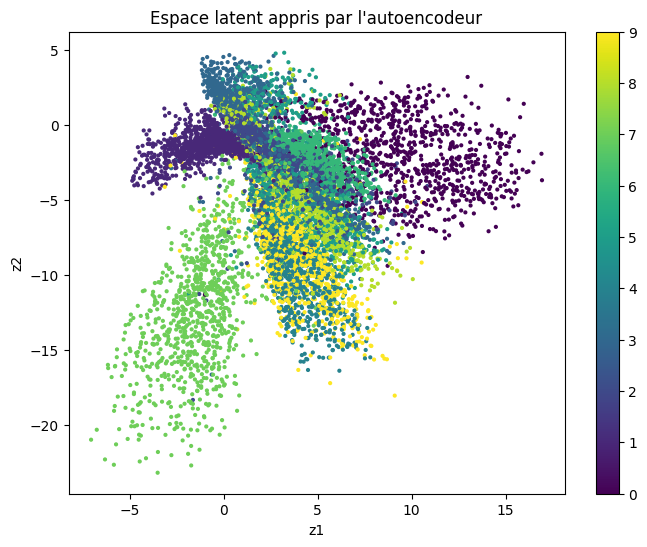

In [16]:
## Visualisation de l'espace latent
ae.eval()

zs = []
ys = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        z = ae.encode(x)

        zs.append(z.cpu())
        ys.append(y)

Z = torch.cat(zs).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(Z[:, 0], Z[:, 1], c=Y, s=4)
plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Espace latent appris par l'autoencodeur")
plt.colorbar(scatter)
plt.show()

**Que représente ce graphique ?**

Ce graphique montre une représentation en deux dimensions de l’espace latent appris par l’autoencodeur sur MNIST :

Chaque point correspond à une image d’un chiffre manuscrit.
Sa couleur indique sa classe réelle, de 0 à 9.
Les coordonnées (z_1) et (z_2) décrivent sa représentation latente.
Si le goulot d’étranglement de l’autoencodeur contient deux neurones, ce sont directement les sorties de l’encodeur. Si tu as utilisé une projection comme PCA, t-SNE ou UMAP, l’interprétation dépend aussi de cette méthode.

**Ce que l’on observe**
Une organisation visible, mais une séparation partielle
Les points ne sont pas répartis aléatoirement : plusieurs régions et branches apparaissent.

D’après les couleurs de la figure :

Les 0, en violet foncé, sont principalement regroupés à gauche.
Les 1, également violets mais un peu plus clairs, forment une grande région à droite, relativement séparée.
Les 2, en bleu, occupent notamment une branche qui s’étend vers le haut à gauche.
Plusieurs autres classes se concentrent dans la zone centrale, avec un chevauchement important.
L’association exacte entre certaines couleurs et certains chiffres reste difficile à lire avec cette palette continue.

Interprétation : l’encodeur semble avoir appris des caractéristiques qui différencient certaines familles d’images, mais il ne produit pas dix groupes nettement distincts.

Un mélange important au centre
La région centrale rassemble de nombreux points de couleurs différentes. Cela signifie que des images de classes différentes ont des représentations proches dans cette visualisation.

Ce phénomène peut venir de plusieurs facteurs :

Des chiffres différents partagent des caractéristiques graphiques : boucles, courbures, traits verticaux, inclinaison.
Un autoencodeur classique cherche à reconstruire les images, pas à séparer leurs étiquettes.
Si l’espace latent est réellement limité à deux dimensions, la compression est très forte : une image MNIST contient (28 \times 28 = 784) pixels.
S’il s’agit d’une projection d’un espace de dimension supérieure, une partie du mélange peut être introduite par la projection.
Le chevauchement ne prouve donc pas, à lui seul, que le modèle a mal appris.

Des groupes étirés plutôt que compacts
Certaines classes forment des branches ou des structures allongées. Cela pourrait refléter des variations internes aux chiffres : épaisseur du trait, inclinaison, largeur ou style d’écriture.

Pour vérifier cette hypothèse, il faudrait afficher des images correspondant à plusieurs points le long d’une même branche. Le graphique seul ne permet pas d’attribuer une signification précise à (z_1) ou (z_2).

**3. **Est-ce un bon autoencodeur ?**

Ce graphique montre une structure latente intéressante, mais ne suffit pas à juger la qualité globale de l’autoencodeur.

Un autoencodeur classique apprend généralement :
$$
[
z = f_\theta(x), \qquad \hat{x} = g_\phi(z)
]
$$

en minimisant une erreur de reconstruction :
$$
[
\mathcal{L}{\mathrm{rec}} = \frac{1}{N}\sum{i=1}^{N}\ell(x_i,\hat{x}_i).
]
$$
Il n’est donc pas directement pénalisé lorsque deux classes se mélangent dans l’espace latent.

Objectif	Ce que suggère la figure
Reconstruction des images	Impossible à évaluer sans voir les reconstructions et mesurer leur erreur.
Apprentissage d’une représentation structurée	Résultat encourageant : plusieurs régions distinctes sont visibles.
Classification ou clustering des dix chiffres	Séparation partielle, avec un mélange central important.
Génération de nouveaux chiffres	Impossible à conclure à partir du nuage de points seul.

**4. **Comment compléter l’évaluation ?**

Vérifier les reconstructions
Afficher côte à côte des images originales et reconstruites, idéalement pour chaque chiffre. Observer si les détails discriminants sont conservés : fermeture des boucles, petites barres, courbures, etc.

Mesurer la généralisation
Comparer les pertes de reconstruction sur les ensembles d’entraînement et de test. Une faible erreur d’entraînement ne garantit pas une bonne reconstruction d’images nouvelles.

Tester l’information contenue dans les codes latents
Entraîner un classifieur simple — k-NN ou régression logistique — sur les codes latents d’entraînement, puis l’évaluer sur ceux du test. Cela permet de mesurer si les représentations conservent une information utile pour reconnaître les chiffres.

Améliorer la visualisation
Utiliser une palette catégorielle à dix couleurs, une légende par chiffre et des points plus transparents. Cela rendrait les chevauchements et les groupes plus faciles à analyser.

**Pistes d’amélioration selon l’objectif**

Pour mieux reconstruire : si le code latent est de dimension 2, essayer des dimensions comme 8, 16 ou 32 et comparer les résultats. Une architecture convolutionnelle peut aussi mieux exploiter la structure spatiale de MNIST.
Pour mieux séparer les classes : ajouter un objectif supervisé ou contrastif, si l’utilisation des étiquettes est autorisée. Cela change toutefois l’objectif d’un autoencodeur purement non supervisé.
Pour obtenir un espace plus adapté à l’échantillonnage : envisager un VAE. Sa régularisation favorise un espace latent plus organisé pour la génération, sans garantir une meilleure séparation des chiffres.
Conclusion
L’autoencodeur semble avoir appris une organisation partielle des chiffres MNIST, avec certaines classes assez distinctes et un fort mélange des autres au centre. Ce résultat est compatible avec un apprentissage orienté reconstruction plutôt que classification. Pour conclure sur sa qualité, il faut surtout examiner les images reconstruites, l’erreur sur le test et l’utilité des codes latents.

# Explication du code pour visualiser l’espace latent d’un autoencodeur

Ce code permet de **visualiser la manière dont l’autoencodeur représente les images dans son espace latent**.

Dans le modèle étudié, chaque image de `28 × 28` pixels est transformée par l’encodeur en un vecteur de **deux nombres** :

$$
z = (z_1, z_2)
$$

Ces deux nombres deviennent les coordonnées d’un point dans un graphique :

- $z_1$ : position horizontale ;
- $z_2$ : position verticale.

Chaque point représente donc **une image**, et sa couleur indique son **étiquette réelle**.

Pour MNIST, cette étiquette est le chiffre représenté dans l’image : `0`, `1`, ..., `9`.

```text
Image de 28 × 28 pixels
          ↓
       Encodeur
          ↓
Deux coordonnées : (z1, z2)
          ↓
Point dans un graphique, coloré selon l’étiquette
```

> Ce graphique permet d’examiner si des images appartenant à une même classe occupent des régions proches dans l’espace latent. Ce regroupement n’est pas garanti : l’autoencodeur a appris à reconstruire des images, pas à les classer.

---

## 1. Qu’est-ce que l’espace latent ?

L’espace latent est l’espace dans lequel se trouvent les **représentations compactes apprises par l’encodeur**.

L’image d’origine contient `784` valeurs :

$$
28 \times 28 = 784
$$

Avec `latent_dim=2`, l’encodeur transforme ces `784` valeurs en seulement deux coordonnées :

```text
784 valeurs → 128 valeurs → 32 valeurs → 2 valeurs
```

On peut imaginer les représentations suivantes :

```text
Image A → z = [ 0.8, -1.2]
Image B → z = [ 0.9, -1.1]
Image C → z = [-2.0,  1.5]
```

Dans le graphique, les images A et B seront proches, tandis que l’image C sera plus éloignée.

### Que signifient ces coordonnées ?

Les coordonnées sont apprises automatiquement pour aider le décodeur à reconstruire les images.

Elles ne correspondent pas nécessairement à des propriétés directement interprétables, comme :

- l’épaisseur d’un trait ;
- l’inclinaison du chiffre ;
- la présence d’une boucle.

> Les axes latents n’ont pas de signification fixée à l’avance. Leur orientation et leur échelle peuvent changer d’un entraînement à l’autre.

---

## 2. Passer le modèle en mode évaluation

```python
ae.eval()
```

Cette instruction place l’autoencodeur en **mode évaluation**.

Ce mode adapte le comportement des couches qui distinguent entraînement et évaluation, comme `Dropout` ou `BatchNorm`.

Dans notre autoencodeur composé de couches `Linear`, `ReLU`, `Flatten` et `Sigmoid`, le comportement de ces couches ne change pas. L’appel reste une bonne pratique.

> `ae.eval()` ne désactive pas le calcul des gradients. On utilise `torch.no_grad()` pour cela.

---

## 3. Préparer deux listes de stockage

```python
zs = []
ys = []
```

Ces listes vont accumuler les résultats obtenus pour chaque lot.

### La liste `zs`

```python
zs = []
```

Elle contiendra les **vecteurs latents** des images.

Chaque élément de la liste sera un tenseur correspondant à un lot :

```text
zs = [
    représentations du lot 1,
    représentations du lot 2,
    représentations du lot 3,
    ...
]
```

Avec des lots de `64` images et une dimension latente de `2`, chaque tenseur aura généralement la forme :

```text
[64, 2]
```

Le dernier lot peut être plus petit.

### La liste `ys`

```python
ys = []
```

Elle contiendra les **étiquettes réelles** des images.

Pour un lot de `64` images, le tenseur d’étiquettes a généralement la forme :

```text
[64]
```

Les étiquettes serviront uniquement à choisir la couleur des points.

---

## 4. Désactiver le suivi des gradients

```python
with torch.no_grad():
```

Nous voulons calculer les représentations latentes, sans entraîner le modèle.

Il n’est donc pas nécessaire de conserver les opérations pour une rétropropagation.

`torch.no_grad()` désactive le suivi des gradients dans le bloc concerné, ce qui permet notamment de réduire l’utilisation de mémoire.

### Deux instructions complémentaires

| Instruction | Rôle |
|---|---|
| `ae.eval()` | Configurer le mode d’évaluation du modèle |
| `torch.no_grad()` | Désactiver le suivi des gradients |

Aucune mise à jour des paramètres n’est effectuée dans ce code.

---

## 5. Parcourir les lots de test

```python
for x, y in test_loader:
```

La boucle parcourt tous les lots fournis par `test_loader`.

Pour chaque lot :

- `x` contient les images ;
- `y` contient leurs étiquettes.

Par exemple :

```text
x : [64, 1, 28, 28]
y : [64]
```

### Pourquoi conserver les étiquettes ici ?

Lors de l’entraînement de l’autoencodeur, nous pouvions écrire :

```python
for x, _ in loader:
```

car les étiquettes n’étaient pas utilisées.

Ici, on les conserve pour colorer le graphique :

```text
Étiquette 0 → une couleur
Étiquette 1 → une autre couleur
...
Étiquette 9 → une autre couleur
```

> Les étiquettes servent à analyser les représentations après l’entraînement. Elles ne sont pas transmises à l’encodeur.

---

## 6. Déplacer les images sur le bon périphérique

```python
x = x.to(device)
```

Cette ligne place les images sur le périphérique utilisé par le modèle :

- CPU ;
- ou GPU, selon la valeur de `device`.

Les données et le modèle doivent se trouver sur le même périphérique.

Les étiquettes `y` n’ont pas besoin d’être envoyées sur le GPU, puisqu’elles ne participent pas au calcul des représentations.

---

## 7. Calculer les représentations latentes

```python
z = ae.encode(x)
```

Cette instruction applique **uniquement l’encodeur**.

Dans la classe présentée précédemment :

```python
def encode(self, x):
    return self.encoder(x)
```

Le résultat `z` contient donc les coordonnées latentes des images du lot.

Avec `latent_dim=2` :

```text
x : [B, 1, 28, 28]
         ↓ encodeur
z : [B, 2]
```

où `B` désigne le nombre d’images du lot.

### Pourquoi ne pas utiliser `ae(x)` ?

Les deux appels n’ont pas le même résultat :

| Appel | Calcul effectué | Résultat |
|---|---|---|
| `ae.encode(x)` | Encodeur uniquement | Vecteurs latents |
| `ae(x)` | Encodeur puis décodeur | Images reconstruites |

Pour visualiser l’espace latent, nous avons besoin des vecteurs `z`, pas des reconstructions.

---

## 8. Stocker les résultats du lot

```python
zs.append(z.cpu())
ys.append(y)
```

### Stocker les représentations sur le CPU

```python
zs.append(z.cpu())
```

Cette ligne :

1. ramène les représentations `z` sur le CPU ;
2. ajoute le tenseur obtenu à la liste `zs`.

Pourquoi revenir sur le CPU ?

- La conversion classique vers NumPy nécessite ici des tenseurs CPU.
- Les résultats accumulés ne restent pas stockés sur le GPU.

La forme du tenseur ne change pas :

```text
[B, 2] sur GPU → [B, 2] sur CPU
```

### Stocker les étiquettes

```python
ys.append(y)
```

Cette ligne ajoute les étiquettes du lot à la liste `ys`.

Dans un `DataLoader` classique, `y` est déjà sur le CPU.

### Conserver la correspondance image–étiquette

Les représentations et les étiquettes sont ajoutées dans le même ordre :

```text
zs[0] ↔ ys[0] : premier lot
zs[1] ↔ ys[1] : deuxième lot
...
```

Cette correspondance permettra d’attribuer la bonne couleur à chaque point.

Même si le chargeur mélange les images, cette association reste correcte, car `x` et `y` sont récupérés ensemble.

---

## 9. Regrouper les représentations en un seul tableau

```python
Z = torch.cat(zs).numpy()
```

Cette ligne réalise deux opérations.

### Étape 1 — Concaténer les tenseurs

```python
torch.cat(zs)
```

`torch.cat` assemble les tenseurs de la liste.

Par défaut, la concaténation se fait sur la première dimension, `dim=0`, celle des images.

Par exemple :

```text
Lot 1 : [64, 2]
Lot 2 : [64, 2]
Lot 3 : [22, 2]
          ↓ concaténation
Total : [150, 2]
```

Si `N` images ont été parcourues :

```text
Z avant conversion : [N, 2]
```

> `torch.cat` prolonge une dimension existante. Il n’ajoute pas une nouvelle dimension, contrairement à `torch.stack`.

### Étape 2 — Convertir en tableau NumPy

```python
.numpy()
```

Cette méthode transforme le tenseur CPU en tableau NumPy, un format directement utilisable par Matplotlib.

Ici, la conversion est possible parce que les représentations :

- ont été placées sur le CPU avec `.cpu()` ;
- ont été calculées sans suivi des gradients.

Chaque ligne de `Z` correspond à une image :

```text
Z = [
    [z1 de l’image 1, z2 de l’image 1],
    [z1 de l’image 2, z2 de l’image 2],
    ...
]
```

---

## 10. Regrouper les étiquettes

```python
Y = torch.cat(ys).numpy()
```

Le même principe est appliqué aux étiquettes.

Exemple :

```text
Lot 1 : [64]
Lot 2 : [64]
Lot 3 : [22]
          ↓ concaténation
Total : [150]
```

On obtient donc :

```text
Z : [N, 2]
Y : [N]
```

La correspondance est la suivante :

```python
Z[i]  # Coordonnées latentes de l’image i
Y[i]  # Étiquette réelle de cette même image
```

> Le code suppose que les étiquettes sont des tenseurs CPU. Si elles se trouvaient sur le GPU, il faudrait les ramener sur le CPU avant `.numpy()`, par exemple avec `ys.append(y.cpu())`.

---

## 11. Créer la figure

```python
plt.figure(figsize=(8, 6))
```

Cette instruction crée une figure Matplotlib de :

- `8` pouces de largeur ;
- `6` pouces de hauteur.

Le code suppose que l’import suivant a été effectué :

```python
import matplotlib.pyplot as plt
```

La taille finale en pixels dépend aussi de la résolution de la figure.

---

## 12. Dessiner le nuage de points

```python
scatter = plt.scatter(Z[:, 0], Z[:, 1], c=Y, s=4)
```

C’est la ligne centrale de la visualisation.

`plt.scatter` crée un **nuage de points**.

### Les coordonnées horizontales : `Z[:, 0]`

```python
Z[:, 0]
```

Cette notation signifie :

- `:` : sélectionner toutes les lignes ;
- `0` : sélectionner la première colonne.

On récupère donc la première coordonnée latente de chaque image :

```text
[z1 de l’image 1, z1 de l’image 2, ..., z1 de l’image N]
```

Ces valeurs sont placées sur l’axe horizontal.

### Les coordonnées verticales : `Z[:, 1]`

```python
Z[:, 1]
```

Cette expression récupère la deuxième coordonnée latente de chaque image.

Ces valeurs sont placées sur l’axe vertical.

### Un exemple

Si :

```python
Z = [
    [ 0.8, -1.2],
    [ 0.9, -1.1],
    [-2.0,  1.5]
]
```

alors :

```text
Coordonnées horizontales : [ 0.8,  0.9, -2.0]
Coordonnées verticales   : [-1.2, -1.1,  1.5]
```

Trois points seront affichés.

### Colorer les points : `c=Y`

```python
c=Y
```

L’argument `c` utilise les étiquettes de `Y` pour déterminer les couleurs.

Les points associés à la même étiquette reçoivent la même couleur.

Pour MNIST :

```text
Chaque point représente une image.
Sa position dépend de l’encodeur.
Sa couleur dépend du chiffre réellement représenté.
```

> La couleur ne correspond pas à une prédiction du modèle. Elle représente une information connue du jeu de données.

### Régler la taille des points : `s=4`

```python
s=4
```

L’argument `s` contrôle l’aire des marqueurs, exprimée en points typographiques au carré.

Une petite valeur convient lorsque de nombreuses images sont affichées, afin de limiter le chevauchement.

### Pourquoi conserver le résultat dans `scatter` ?

```python
scatter = ...
```

L’objet renvoyé contient notamment les informations sur les points et leurs couleurs.

Il sera utilisé pour créer une barre de couleurs correspondant exactement à ce graphique.

---

## 13. Nommer les axes

```python
plt.xlabel("z1")
plt.ylabel("z2")
```

Ces instructions ajoutent les noms des deux coordonnées latentes :

- `z1` sur l’axe horizontal ;
- `z2` sur l’axe vertical.

### Attention à leur interprétation

Ces axes ne représentent pas directement :

- le numéro du chiffre ;
- une probabilité ;
- une caractéristique imposée manuellement.

Ce sont deux variables internes apprises pour faciliter la reconstruction.

Il n’y a pas non plus de raison qu’elles soient limitées à `[0, 1]` : dans l’encodeur précédent, la dernière couche n’avait pas de fonction d’activation imposant cette contrainte.

---

## 14. Ajouter un titre

```python
plt.title("Espace latent appris par l'autoencodeur")
```

Cette instruction ajoute un titre à la figure.

Le titre rappelle que les coordonnées affichées sont issues d’une représentation **apprise par le modèle**, et non choisies à l’avance.

---

## 15. Ajouter une barre de couleurs

```python
plt.colorbar(scatter)
```

Cette ligne ajoute une barre indiquant la correspondance entre les valeurs des étiquettes et les couleurs utilisées.

Pour MNIST, elle aide à identifier les couleurs associées aux chiffres de `0` à `9`.

L’argument `scatter` relie explicitement la barre de couleurs au nuage de points.

### Une nuance : les classes sont des catégories

Le code ne précise pas de palette particulière. Matplotlib utilise donc sa palette par défaut, généralement continue.

Cela fonctionne, mais les chiffres sont ici des **catégories distinctes**. Une palette discrète peut rendre le graphique plus clair.

Pour MNIST, on pourrait remplacer le tracé et la barre de couleurs par :

```python
scatter = plt.scatter(
    Z[:, 0],
    Z[:, 1],
    c=Y,
    s=4,
    cmap=plt.get_cmap("tab10"),
    vmin=-0.5,
    vmax=9.5
)

plt.colorbar(
    scatter,
    ticks=range(10),
    label="Chiffre réel"
)
```

Cette version utilise dix couleurs distinctes et affiche une graduation pour chaque chiffre.

---

## 16. Afficher la figure

```python
plt.show()
```

Cette instruction affiche la figure.

Dans un notebook, le graphique apparaît généralement sous la cellule de code exécutée.

---

## 17. Comment interpréter le graphique ?

### Cas 1 — Les points d’une même couleur sont regroupés

Cela suggère que l’encodeur attribue des représentations proches à plusieurs images de cette classe.

Par exemple, des images du chiffre `1` peuvent partager une forme simple et se retrouver dans une région commune.

### Cas 2 — Plusieurs couleurs se mélangent

Cela signifie que des images de classes différentes occupent des régions proches dans cette projection.

Ce n’est pas nécessairement une erreur d’entraînement.

L’autoencodeur optimise la reconstruction, pas la séparation des classes. Des chiffres différents peuvent partager des caractéristiques visuelles.

### Cas 3 — Une même couleur apparaît dans plusieurs régions

Une classe peut contenir plusieurs styles d’écriture :

- chiffres inclinés ou droits ;
- traits fins ou épais ;
- formes ouvertes ou fermées.

L’encodeur peut représenter ces variantes dans différentes régions.

### Les distances ont-elles un sens absolu ?

Pas nécessairement.

Des points proches ont des codes latents proches, mais un autoencodeur classique ne garantit pas qu’une distance dans cet espace corresponde exactement à une similarité visuelle ou sémantique.

De plus, l’échelle d’affichage peut modifier l’impression visuelle des distances. Pour représenter une unité de la même taille sur les deux axes, on peut ajouter :

```python
plt.gca().set_aspect("equal", adjustable="box")
```

> Ce graphique est un outil d’exploration. Il ne constitue pas à lui seul une preuve de bonne reconstruction ou de bonne séparation des classes.

---

## 18. Pourquoi une dimension latente de deux est-elle pratique ?

Avec :

```python
latent_dim = 2
```

chaque représentation peut être affichée directement dans un plan.

Il n’y a donc pas besoin d’une méthode supplémentaire comme PCA, t-SNE ou UMAP.

### Si la dimension latente est supérieure à deux

Le code :

```python
plt.scatter(Z[:, 0], Z[:, 1], ...)
```

fonctionne encore, mais n’affiche que les **deux premières coordonnées**. Les autres dimensions sont ignorées.

Le graphique ne représente alors qu’une vue partielle de l’espace latent.

### Si la dimension latente vaut un

L’expression :

```python
Z[:, 1]
```

provoque une erreur, car il n’existe pas de deuxième coordonnée.

> La visualisation représente directement l’intégralité du vecteur latent uniquement lorsque celui-ci possède exactement deux dimensions.

---

## 19. Vue d’ensemble des formes des données

Si `N` images sont parcourues au total et si chaque lot contient `B` images :

| Variable | Contenu | Forme |
|---|---|---|
| `x` | Images d’un lot | `[B, 1, 28, 28]` |
| `y` | Étiquettes de ce lot | `[B]` |
| `z` | Représentations latentes du lot | `[B, 2]` |
| `zs` | Liste des tenseurs latents | Une entrée par lot |
| `ys` | Liste des tenseurs d’étiquettes | Une entrée par lot |
| `Z` | Toutes les représentations, en NumPy | `[N, 2]` |
| `Y` | Toutes les étiquettes, en NumPy | `[N]` |
| `Z[:, 0]` | Coordonnées horizontales | `[N]` |
| `Z[:, 1]` | Coordonnées verticales | `[N]` |

Dans un chargeur classique parcourant tout le jeu de test sans supprimer le dernier lot, `N` correspond au nombre total d’images de test.

---

## 20. Résumé du déroulement

```text
1. Activer le mode évaluation
                ↓
2. Parcourir les lots de test sans gradients
                ↓
3. Encoder les images de chaque lot
                ↓
4. Stocker les codes latents et les étiquettes
                ↓
5. Regrouper les lots dans deux tableaux
                ↓
6. Tracer un point par image aux coordonnées (z1, z2)
                ↓
7. Colorer chaque point selon son étiquette réelle
                ↓
8. Afficher le graphique et sa barre de couleurs
```

---

## À retenir

| Élément | Rôle |
|---|---|
| `ae.eval()` | Activer le mode évaluation |
| `zs = []` | Préparer le stockage des représentations latentes |
| `ys = []` | Préparer le stockage des étiquettes |
| `torch.no_grad()` | Désactiver le suivi des gradients |
| `for x, y in test_loader` | Parcourir les images de test et leurs étiquettes |
| `x.to(device)` | Placer les images sur le périphérique du modèle |
| `ae.encode(x)` | Calculer les vecteurs latents |
| `z.cpu()` | Ramener les représentations sur le CPU |
| `append(...)` | Ajouter les résultats d’un lot à une liste |
| `torch.cat(...)` | Regrouper les tenseurs des différents lots |
| `.numpy()` | Convertir un tenseur CPU en tableau NumPy |
| `Z[:, 0]` | Sélectionner la première coordonnée latente |
| `Z[:, 1]` | Sélectionner la deuxième coordonnée latente |
| `c=Y` | Colorer les points selon les étiquettes réelles |
| `s=4` | Définir la taille des points |
| `plt.colorbar(scatter)` | Afficher la correspondance entre couleurs et étiquettes |
| `plt.show()` | Afficher la figure |

**En une phrase : ce code représente chaque image de test par un point dans l’espace latent à deux dimensions, puis colore ce point selon son étiquette réelle pour explorer l’organisation apprise par l’autoencodeur.**

## Génération à partir d'un chiffre connu

In [17]:
import torch
import matplotlib.pyplot as plt

@torch.no_grad()
def generer_chiffre(model, dataloader, chiffre):
    if chiffre not in range(10):
        raise ValueError("Le chiffre doit être compris entre 0 et 9.")

    device = next(model.parameters()).device
    model.eval()

    somme_z = None
    nombre = 0

    for images, labels in dataloader:
        # Sélection des images du chiffre demandé
        images = images[labels == chiffre]

        if images.shape[0] == 0:
            continue

        z = model.encode(images.to(device))

        if somme_z is None:
            somme_z = z.sum(dim=0, keepdim=True)
        else:
            somme_z += z.sum(dim=0, keepdim=True)

        nombre += z.shape[0]

    if nombre == 0:
        raise ValueError(f"Aucune image du chiffre {chiffre} trouvée.")

    z_moyen = somme_z / nombre
    return model.decode(z_moyen).cpu()

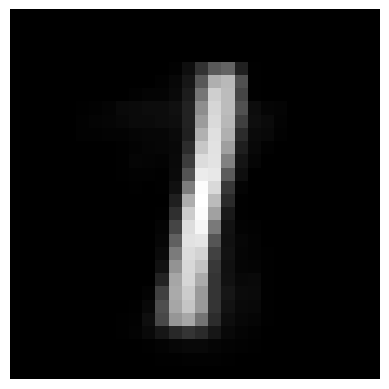

In [18]:
# model : ton autoencodeur entraîné
# train_loader : ton DataLoader MNIST
image = generer_chiffre(ae, train_loader, chiffre=1)

plt.imshow(image[0, 0].numpy(), cmap="gray")
plt.axis("off")
plt.show()

# **7. Limite d'un autoencodeur classique**

L'AE apprend des représentations utiles, mais rien ne garantit que l'espace latent soit :

- continu ;
- régulier ;
- facile à échantillonner ;
- distribué selon une loi connue.

Si nous choisissons arbitrairement un point :
$$
\
z=(z_1,z_2)
\
$$
le décodeur peut produire une image peu réaliste.

Cette difficulté motive le **Variational Autoencoder**.

# **Partie III — Variational Autoencoder (VAE)**

# **8. Principe**

Au lieu d'associer une entrée \(x\) à un point latent unique, le VAE associe \(x\) à une distribution :
$$
\
q(z|x)=\mathcal{N}(\mu,\sigma^2)
\
$$
L'encodeur produit :
$$
\
\mu(x)
\
$$
et :
$$
\
\log \sigma^2(x)
\
$$
Puis nous échantillonnons \(z\).

# **9. Reparameterization trick**

On veut échantillonner :
$$
\
z \sim \mathcal{N}(\mu,\sigma^2)
\
$$

tout en conservant la rétropropagation.

On écrit :
$$
\
\epsilon \sim \mathcal{N}(0,I)
\
$$
puis :
$$
\
\boxed{
z=\mu+\sigma\odot\epsilon
}
\
$$

C'est le **reparameterization trick**.

In [22]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        return x_hat, mu, logvar

vae = VAE(latent_dim=2).to(device)
vae

VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=64, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

# Comprendre un Variational Autoencoder (VAE) avec PyTorch

Ce modèle apprend à reconstruire des images MNIST de **28 × 28 pixels**, en passant par une représentation compacte appelée **code latent**.

Contrairement à un auto-encodeur classique, le VAE ne calcule pas directement un code unique : il calcule les paramètres d’une distribution, puis tire un code dans cette distribution.

```text
Image → Encodeur → Distribution latente → Code z → Décodeur → Reconstruction
```

Dans cette explication, nous utiliserons un lot de **32 images**.

## 1. Déclarer le modèle

```python
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
```

### `class VAE(nn.Module)`

Le modèle hérite de `nn.Module`, la classe de base des réseaux de neurones PyTorch.

Cela permet notamment :
- de gérer les paramètres du modèle ;
- de calculer leurs gradients ;
- de déplacer le modèle sur CPU ou GPU ;
- de sauvegarder ses paramètres.

### `super().__init__()`

Cette instruction initialise les fonctionnalités héritées de `nn.Module`.

### `latent_dim=2`

Chaque code latent contiendra **deux nombres** :

```text
z = [z₁, z₂]
```

Un espace latent à deux dimensions est facile à visualiser sur un graphique. Cependant, il peut limiter la qualité des reconstructions.

## 2. Construire l’encodeur

```python
self.encoder = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 64),
    nn.ReLU()
)
```

L’encodeur transforme une image en **64 caractéristiques apprises**.

`nn.Sequential` applique les couches dans l’ordre.

### Aplatir les images

```python
nn.Flatten()
```

Un lot de 32 images MNIST a la forme :

```text
[32, 1, 28, 28]
```

Ces dimensions représentent :

| Dimension | Signification |
|---|---|
| 32 | Nombre d’images |
| 1 | Nombre de canaux : niveaux de gris |
| 28 | Hauteur |
| 28 | Largeur |

`Flatten()` conserve la dimension du lot et transforme chaque image en vecteur :

```text
[32, 1, 28, 28] → [32, 784]
```

En effet :

\[
28 \times 28 = 784
\]

### Transformer les pixels en caractéristiques

```python
nn.Linear(784, 256)
```

Chaque vecteur de 784 pixels devient un vecteur de 256 caractéristiques :

```text
[32, 784] → [32, 256]
```

Une couche linéaire applique une transformation :

\[
y = Wx + b
\]

Les poids \(W\) et les biais \(b\) sont appris pendant l’entraînement.

### Ajouter une non-linéarité

```python
nn.ReLU()
```

ReLU conserve les valeurs positives et remplace les valeurs négatives par zéro :

```text
Entrée : [-2, 0.5, 3]
Sortie : [ 0, 0.5, 3]
```

Elle permet au réseau d’apprendre des relations non linéaires.

### Réduire à 64 caractéristiques

```python
nn.Linear(256, 64),
nn.ReLU()
```

On obtient :

```text
[32, 256] → [32, 64]
```

**Ces 64 caractéristiques ne sont pas encore le code latent.**

> Ce modèle utilise des couches entièrement connectées : ce n’est pas un CNN.

## 3. Prédire les paramètres de la distribution latente

```python
self.fc_mu = nn.Linear(64, latent_dim)
self.fc_logvar = nn.Linear(64, latent_dim)
```

Les 64 caractéristiques alimentent deux couches :

```text
                         ┌→ fc_mu     → moyenne μ
64 caractéristiques ─────┤
                         └→ fc_logvar → logarithme de la variance
```

Avec `latent_dim=2`, chaque image reçoit :
- deux moyennes ;
- deux logarithmes de variances.

Pour notre lot :

```text
mu     : [32, 2]
logvar : [32, 2]
```

### La moyenne `mu`

Elle définit le centre de la distribution latente.

```text
mu = [1.0, -0.5]
```

Cela signifie que les codes tirés seront centrés autour de ce point.

### Le logarithme de la variance `logvar`

La variance décrit la dispersion autour du centre.

Le modèle prédit son logarithme :

\[
\text{logvar} = \log(\sigma^2)
\]

Pourquoi ?

Une couche linéaire peut produire des valeurs négatives, alors qu’une variance doit être positive.

En utilisant l’exponentielle, on retrouve une variance positive :

\[
\sigma^2 = \exp(\text{logvar})
\]

**Une valeur négative de `logvar` ne signifie donc pas une variance négative.**

> Image mentale : l’encodeur associe un petit nuage à chaque image. `mu` indique son centre et `logvar` détermine son étendue.

## 4. La méthode `encode`

```python
def encode(self, x):
    h = self.encoder(x)
    mu = self.fc_mu(h)
    logvar = self.fc_logvar(h)
    return mu, logvar
```

Cette méthode :
1. extrait les caractéristiques `h` ;
2. calcule `mu` ;
3. calcule `logvar`.

```text
x      : [32, 1, 28, 28]
h      : [32, 64]
mu     : [32, 2]
logvar : [32, 2]
```

Elle décrit une distribution par image, mais ne tire pas encore de code.

## 5. La méthode `reparameterize`

```python
def reparameterize(self, mu, logvar):
    std = torch.exp(0.5 * logvar)
    eps = torch.randn_like(std)
    return mu + std * eps
```

Cette méthode tire le code latent avec la formule :

\[
z = \mu + \sigma \odot \varepsilon,
\qquad \varepsilon \sim \mathcal{N}(0,I)
\]

Le symbole \(\odot\) désigne une multiplication élément par élément.

### Calculer l’écart-type

```python
std = torch.exp(0.5 * logvar)
```

L’écart-type est la racine carrée de la variance :

\[
\sigma
=
\sqrt{\sigma^2}
=
\exp\left(\frac{1}{2}\log(\sigma^2)\right)
\]

C’est pourquoi on multiplie `logvar` par `0.5`.

### Générer un bruit aléatoire

```python
eps = torch.randn_like(std)
```

Cette instruction crée un tenseur :
- de même forme que `std` ;
- sur le même appareil ;
- contenant des tirages gaussiens de moyenne 0 et de variance 1.

### Construire le code

```python
return mu + std * eps
```

Exemple pour une image :

```text
mu  = [1.0, -0.5]
std = [0.2,  0.4]
eps = [0.5, -1.0]

z = [1.0 + 0.2 × 0.5, -0.5 + 0.4 × (-1.0)]
z = [1.1, -0.9]
```

### Pourquoi utiliser cette astuce ?

Le hasard est placé dans `eps`. Le résultat reste une expression différentiable de `mu` et de `std`.

PyTorch peut donc calculer les gradients nécessaires pour entraîner l’encodeur.

**La reparamétrisation permet de combiner échantillonnage aléatoire et apprentissage par rétropropagation.**

## 6. Construire le décodeur

```python
self.decoder = nn.Sequential(
    nn.Linear(latent_dim, 64),
    nn.ReLU(),
    nn.Linear(64, 256),
    nn.ReLU(),
    nn.Linear(256, 784),
    nn.Sigmoid()
)
```

Le décodeur transforme le code latent en pixels :

```text
[32, 2] → [32, 64] → [32, 256] → [32, 784]
```

Il apprend à reconstruire une image à partir de deux nombres.

### Pourquoi utiliser `Sigmoid()` ?

La sigmoid ramène les valeurs entre 0 et 1.

Ces valeurs peuvent être affichées comme des intensités de pixels :

```text
0   → noir
0.5 → gris
1   → blanc
```

Dans une formulation courante du VAE, elles paramètrent des distributions de Bernoulli pour les pixels.

> Avec une perte de reconstruction BCE, les images cibles doivent être dans `[0, 1]`. `transforms.ToTensor()` convient ; une standardisation produisant des valeurs négatives ne convient pas directement à cette perte.

## 7. La méthode `decode`

```python
def decode(self, z):
    x_hat = self.decoder(z)
    return x_hat.view(-1, 1, 28, 28)
```

`x_hat` désigne la reconstruction de l’entrée.

Le décodeur produit d’abord :

```text
[32, 784]
```

Puis `view` réorganise ces valeurs en images :

```text
[32, 784] → [32, 1, 28, 28]
```

Dans :

```python
view(-1, 1, 28, 28)
```

- `-1` demande à PyTorch de déduire le nombre d’images ;
- `1` correspond au canal ;
- `28, 28` correspondent à la hauteur et à la largeur.

**Cette opération change la forme du tenseur, pas les valeurs des pixels.**

## 8. La méthode `forward`

```python
def forward(self, x):
    mu, logvar = self.encode(x)
    z = self.reparameterize(mu, logvar)
    x_hat = self.decode(z)
    return x_hat, mu, logvar
```

Elle relie toutes les étapes :

```text
Image → mu et logvar → z → Reconstruction
```

Quand on écrit :

```python
x_hat, mu, logvar = vae(images)
```

PyTorch appelle cette méthode.

### Pourquoi retourner trois résultats ?

L’entraînement utilise deux termes :
$$
\
\text{Perte VAE}
=
\text{Perte de reconstruction}
+
\text{Divergence KL}
\
$$

| Résultat | Utilité |
|---|---|
| `x_hat` | Comparer la reconstruction à l’image originale |
| `mu` | Calculer la divergence KL |
| `logvar` | Calculer la divergence KL |

La divergence KL rapproche les distributions latentes de la référence :
$$
\
p(z)=\mathcal{N}(0,I)
\
$$

**Important : ce code définit le réseau, mais ne calcule pas la perte et n’effectue pas l’entraînement. La régularisation KL doit être ajoutée dans la boucle d’entraînement.**

## 9. Instancier le modèle

```python
vae = VAE(latent_dim=2).to(device)
```

Cette ligne :
1. crée le modèle ;
2. choisit deux dimensions latentes ;
3. déplace les paramètres sur `device`.

Par exemple :

```python
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
```

Les images doivent être sur le même appareil :

```python
images = images.to(device)
x_hat, mu, logvar = vae(images)
```

Dans un notebook, écrire :

```python
vae
```

affiche l’architecture. Dans un script, utilisez :

```python
print(vae)
```

## 10. Générer de nouvelles images

Après l’entraînement, on peut tirer directement des codes dans la distribution de référence :

```python
vae.eval()

with torch.no_grad():
    z = torch.randn(16, 2, device=device)
    generated_images = vae.decode(z)
```

On obtient :

```text
generated_images : [16, 1, 28, 28]
```

L’encodeur n’est pas nécessaire pour cette génération.

### Attention au mode évaluation

`vae.eval()` ne supprime pas le tirage aléatoire dans `reparameterize`.

Pour reconstruire une image sans ce tirage, on peut décoder directement la moyenne :

```python
with torch.no_grad():
    mu, _ = vae.encode(images)
    reconstruction = vae.decode(mu)
```

## Résumé

| Élément | Rôle |
|---|---|
| `encoder` | Extraire des caractéristiques |
| `fc_mu` | Définir le centre de la distribution latente |
| `fc_logvar` | Définir sa dispersion |
| `reparameterize` | Tirer un code tout en permettant le calcul des gradients |
| `decoder` | Transformer le code en pixels |
| `forward` | Enchaîner toutes les étapes |

> **L’encodeur décrit un nuage, la reparamétrisation choisit un point dans ce nuage, et le décodeur transforme ce point en image.**

# **10. Loss et entrainement du VAE**

Le VAE combine deux termes :

### Reconstruction
$$
\
\mathcal{L}_{rec}
\
$$

### Régularisation de l'espace latent
$$
\
D_{KL}
\left(
q(z|x)
\parallel
\mathcal N(0,I)
\right)
\
$$

Pour une gaussienne diagonale :
$$
\
D_{KL}
=
-\frac12
\sum
\left(
1+\log\sigma^2-\mu^2-\sigma^2
\right)
\
$$

La loss totale est :
$$
\
\boxed{
\mathcal L_{VAE}
=
\mathcal L_{rec}
+
\beta D_{KL}
}
\
$$

In [23]:
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    rec_loss = F.binary_cross_entropy(
        x_hat,
        x,
        reduction="sum"
    )

    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return rec_loss + beta * kl_loss, rec_loss, kl_loss

# Comprendre la fonction de perte d’un autoencodeur variationnel (VAE)

Ce code définit la **fonction de perte d’un autoencodeur variationnel**, ou **VAE** (*Variational Autoencoder*).

```python
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    rec_loss = F.binary_cross_entropy(
        x_hat,
        x,
        reduction="sum"
    )

    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return rec_loss + beta * kl_loss, rec_loss, kl_loss
```

Cette perte combine deux objectifs :

1. **bien reconstruire les données d’entrée** ;
2. **régulariser les distributions latentes produites par l’encodeur**.

Elle s’écrit :

$$
\mathcal{L}_{\text{totale}}
=
\mathcal{L}_{\text{reconstruction}}
+
\beta \, \mathcal{L}_{\text{KL}}
$$

> Contrairement à un autoencodeur classique, un VAE ne représente pas directement chaque image par un unique vecteur latent. Son encodeur définit une distribution de probabilité à partir de laquelle on peut échantillonner un vecteur latent.

---

## 1. Rappel : que produit l’encodeur d’un VAE ?

### Dans un autoencodeur classique

L’encodeur transforme une image en un vecteur latent :

```text
Image x → Encodeur → Vecteur latent z
```

### Dans un VAE

L’encodeur produit les paramètres d’une distribution, généralement une loi normale à covariance diagonale :

```text
                       → Moyenne mu
Image x → Encodeur
                       → Logarithme de la variance logvar
```

On note cette distribution :

$$
q_\phi(z \mid x)
=
\mathcal{N}
\left(
\mu(x),
\operatorname{diag}(\sigma^2(x))
\right)
$$

où :

- $\mu(x)$ contient les moyennes des coordonnées latentes ;
- $\sigma^2(x)$ contient leurs variances ;
- $\phi$ représente les paramètres de l’encodeur ;
- la covariance diagonale signifie que les coordonnées sont indépendantes dans cette distribution conditionnelle.

Le modèle peut ensuite obtenir un vecteur latent par :

$$
z = \mu + \sigma \odot \varepsilon,
\qquad
\varepsilon \sim \mathcal{N}(0, I)
$$

Le symbole $\odot$ représente une multiplication élément par élément.

Le décodeur utilise ce vecteur pour reconstruire l’image :

```text
Image x
   ↓
Encodeur
   ↓
mu et logvar
   ↓
Échantillonnage de z
   ↓
Décodeur
   ↓
Reconstruction x_hat
```

> L’échantillonnage n’est pas réalisé dans la fonction `vae_loss`. Celle-ci reçoit les résultats nécessaires pour calculer la perte.

---

## 2. Les arguments de la fonction

```python
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
```

| Argument | Signification |
|---|---|
| `x_hat` | Reconstruction produite par le décodeur |
| `x` | Données originales à reconstruire |
| `mu` | Moyennes des distributions latentes |
| `logvar` | Logarithmes des variances latentes |
| `beta` | Poids accordé au terme de régularisation KL |

Pour un lot de `B` images de `28 × 28` pixels et une dimension latente `D`, les formes peuvent être :

```text
x      : [B, 1, 28, 28]
x_hat  : [B, 1, 28, 28]
mu     : [B, D]
logvar : [B, D]
```

`x_hat` et `x` doivent avoir la même forme.

Le code suppose notamment les imports suivants :

```python
import torch
import torch.nn.functional as F
```

---

## 3. Première composante : l’erreur de reconstruction

```python
rec_loss = F.binary_cross_entropy(
    x_hat,
    x,
    reduction="sum"
)
```

Cette instruction mesure l’écart entre la reconstruction `x_hat` et l’entrée `x`.

Elle utilise l’**entropie croisée binaire**, appelée **BCE** pour *Binary Cross-Entropy*.

### Pourquoi « binaire » ?

Pour une variable binaire, une valeur cible vaut `0` ou `1`, et la prédiction représente la probabilité d’obtenir `1`.

Dans le contexte d’une image :

- un pixel noir peut être représenté par `0` ;
- un pixel blanc par `1` ;
- la sortie du décodeur donne une valeur entre `0` et `1`.

La BCE pénalise les reconstructions qui ne correspondent pas aux valeurs cibles.

PyTorch accepte aussi des cibles intermédiaires dans `[0, 1]`, ce qui permet son utilisation sur des images en niveaux de gris ramenées dans cet intervalle.

> Pour des pixels strictement binaires, la BCE correspond à une vraisemblance de Bernoulli. Pour des intensités continues en niveaux de gris, elle reste une fonction de coût utilisable, mais son interprétation comme modèle probabiliste exact des intensités demande davantage de précautions.

---

## 4. Comprendre la formule de la BCE

Pour une valeur cible $x$ et une valeur reconstruite $\hat{x}$ :

$$
\operatorname{BCE}(\hat{x}, x)
=
-\left[
x \log(\hat{x})
+
(1-x)\log(1-\hat{x})
\right]
$$

Les logarithmes sont naturels.

### Si le pixel cible vaut `1`

La formule devient :

$$
\operatorname{BCE}(\hat{x}, 1)
=
-\log(\hat{x})
$$

Exemples :

| Cible | Reconstruction | Perte approximative |
|---|---|---|
| `1` | `0.9` | `0.105` |
| `1` | `0.5` | `0.693` |
| `1` | `0.1` | `2.303` |

Plus la reconstruction est proche de `1`, plus la perte est faible.

### Si le pixel cible vaut `0`

La formule devient :

$$
\operatorname{BCE}(\hat{x}, 0)
=
-\log(1-\hat{x})
$$

Cette fois, une reconstruction proche de `0` donne une faible perte.

### Une nuance pour les niveaux de gris

Si la cible est une valeur intermédiaire, par exemple `0.5`, la BCE est minimisée lorsque la prédiction vaut aussi `0.5`.

Mais la perte minimale n’est alors **pas nulle** :

$$
\operatorname{BCE}(0.5, 0.5)
=
-\log(0.5)
\approx 0.693
$$

> Contrairement à la MSE, la BCE n’est donc pas nécessairement nulle lorsque la reconstruction correspond exactement à une cible en niveaux de gris.

---

## 5. Les conditions nécessaires pour utiliser cette BCE

```python
F.binary_cross_entropy(x_hat, x, ...)
```

Cette fonction attend :

- des reconstructions `x_hat` dans `[0, 1]` ;
- des cibles `x` dans `[0, 1]`.

Pour produire ces reconstructions, le décodeur se termine souvent par :

```python
nn.Sigmoid()
```

### Et si le décodeur ne contient pas de sigmoïde ?

S’il produit des valeurs brutes, appelées **logits**, on utilise plutôt :

```python
F.binary_cross_entropy_with_logits(
    logits,
    x,
    reduction="sum"
)
```

Cette fonction combine la sigmoïde et le calcul de la BCE de façon numériquement plus stable.

> Il ne faut pas appliquer une sigmoïde avant `binary_cross_entropy_with_logits`, car cette fonction attend directement les logits.

---

## 6. Que signifie `reduction="sum"` ?

```python
reduction="sum"
```

Cette option demande de **sommer les pertes de tous les éléments**, au lieu d’en calculer la moyenne.

Pour des images, on additionne donc les contributions :

- de tous les pixels ;
- de tous les canaux ;
- de toutes les images du lot.

Pour `B` images en niveaux de gris de `28 × 28` pixels :

$$
\mathcal{L}_{\text{reconstruction}}
=
\sum_{b=1}^{B}
\sum_{p=1}^{784}
\operatorname{BCE}(\hat{x}_{b,p}, x_{b,p})
$$

Le résultat `rec_loss` est un tenseur scalaire : il contient une seule valeur.

### Conséquence importante

La valeur de cette perte dépend du nombre d’éléments comparés.

À qualité de reconstruction comparable :

- un lot deux fois plus grand produit approximativement une perte deux fois plus grande ;
- une image contenant davantage de pixels contribue davantage à la somme.

> Une perte calculée avec `"sum"` ne peut pas être directement comparée à une perte calculée avec `"mean"` sans tenir compte de leur normalisation.

---

## 7. Deuxième composante : la divergence KL

```python
kl_loss = -0.5 * torch.sum(
    1 + logvar - mu.pow(2) - logvar.exp()
)
```

Ce terme régularise les distributions latentes produites par l’encodeur.

Il mesure la **divergence de Kullback-Leibler**, abrégée **KL**, entre :

1. la distribution produite pour une image :

$$
q_\phi(z \mid x)
$$

2. une distribution de référence, appelée **prior** :

$$
p(z) = \mathcal{N}(0, I)
$$

Ce prior est une loi normale standard :

- moyenne nulle ;
- variance égale à `1` dans chaque dimension ;
- coordonnées indépendantes.

Le terme calculé est donc :

$$
D_{\mathrm{KL}}
\left(
q_\phi(z \mid x)
\,\|\, 
p(z)
\right)
$$

### À quoi sert cette régularisation ?

Sans ce terme, le modèle pourrait organiser les représentations uniquement pour reconstruire les images, sans chercher à les rendre compatibles avec une distribution de référence simple.

Le terme KL encourage des distributions latentes proches du prior.

Cela aide notamment à générer des données en suivant le schéma :

```text
Tirer z dans une loi normale standard
                 ↓
              Décodeur
                 ↓
           Image générée
```

> Cette régularisation favorise un espace latent compatible avec le prior, mais ne garantit pas à elle seule des générations de bonne qualité ni des classes bien séparées.

---

## 8. Pourquoi utiliser `logvar` plutôt que la variance ?

Le code utilise :

```python
logvar
```

qui représente :

$$
\text{logvar} = \log(\sigma^2)
$$

Il s’agit du **logarithme de la variance**, et non du logarithme de l’écart-type.

### Quel est l’intérêt ?

Une variance doit être positive.

En revanche, son logarithme peut prendre n’importe quelle valeur réelle. Le réseau peut donc produire `logvar` sans imposer directement une contrainte de positivité à sa sortie.

On retrouve la variance avec :

$$
\sigma^2 = \exp(\text{logvar})
$$

En PyTorch :

```python
variance = logvar.exp()
```

Pour retrouver l’écart-type :

$$
\sigma = \exp\left(\frac{1}{2}\text{logvar}\right)
$$

En PyTorch :

```python
std = torch.exp(0.5 * logvar)
```

> La valeur `logvar = 0` signifie une variance égale à `1`, car $\exp(0)=1$. Elle ne signifie pas une variance nulle.

---

## 9. D’où vient la formule de la KL ?

Pour une loi normale à covariance diagonale et un prior normal standard, la divergence KL possède une expression calculable directement :

$$
D_{\mathrm{KL}}
=
\frac{1}{2}
\sum_{j=1}^{D}
\left(
\mu_j^2
+
\sigma_j^2
-
1
-
\log(\sigma_j^2)
\right)
$$

En remplaçant :

$$
\log(\sigma_j^2) = \text{logvar}_j
$$

et :

$$
\sigma_j^2 = \exp(\text{logvar}_j)
$$

on obtient :

$$
D_{\mathrm{KL}}
=
\frac{1}{2}
\sum_{j=1}^{D}
\left(
\mu_j^2
+
\exp(\text{logvar}_j)
-
1
-
\text{logvar}_j
\right)
$$

Cette expression est équivalente à :

$$
D_{\mathrm{KL}}
=
-\frac{1}{2}
\sum_{j=1}^{D}
\left(
1
+
\text{logvar}_j
-
\mu_j^2
-
\exp(\text{logvar}_j)
\right)
$$

C’est exactement la forme utilisée dans le code.

> Cette formule suppose une distribution latente gaussienne à covariance diagonale et un prior $\mathcal{N}(0,I)$. Elle ne s’applique pas telle quelle à n’importe quelles distributions.

---

## 10. Décomposer le calcul PyTorch de la KL

```python
1 + logvar - mu.pow(2) - logvar.exp()
```

Chaque opération est effectuée élément par élément.

### Le carré de la moyenne

```python
mu.pow(2)
```

calcule :

$$
\mu^2
$$

Par exemple :

```text
mu        : [-2, 0, 3]
mu.pow(2) : [ 4, 0, 9]
```

Ce terme contribue à pénaliser les moyennes éloignées de zéro.

### La variance

```python
logvar.exp()
```

calcule :

$$
\exp(\text{logvar}) = \sigma^2
$$

### La somme

```python
torch.sum(...)
```

Sans argument `dim`, `torch.sum` additionne **tous les éléments** du tenseur.

Si `mu` et `logvar` ont pour forme :

```text
[B, D]
```

la somme porte donc sur :

- les `D` dimensions latentes ;
- les `B` images du lot.

### Le facteur `-0.5`

```python
-0.5 * ...
```

complète la formule analytique de la divergence KL.

Le résultat `kl_loss` est un tenseur scalaire, comme `rec_loss`.

---

## 11. Un exemple simple pour comprendre la KL

### Cas 1 — La distribution correspond exactement au prior

Supposons :

```python
mu = 0
logvar = 0
```

Alors :

$$
\mu = 0
\qquad \text{et} \qquad
\sigma^2 = e^0 = 1
$$

La KL vaut :

$$
-\frac{1}{2}
\left(
1 + 0 - 0^2 - 1
\right)
=
0
$$

La distribution est exactement la loi normale standard : aucune pénalité KL n’est nécessaire.

### Cas 2 — La moyenne s’éloigne de zéro

Supposons :

```python
mu = 2
logvar = 0
```

La variance reste égale à `1`, mais la moyenne vaut `2`.

$$
D_{\mathrm{KL}}
=
-\frac{1}{2}
\left(
1 + 0 - 2^2 - 1
\right)
=
2
$$

Le terme KL augmente.

### Cas 3 — La variance s’éloigne de un

Supposons une moyenne nulle et une variance de `4` :

$$
\mu = 0,
\qquad
\text{logvar} = \log(4)
$$

Alors :

$$
D_{\mathrm{KL}}
=
\frac{1}{2}
\left(
4 - 1 - \log(4)
\right)
\approx 0.807
$$

La divergence pénalise donc aussi une variance différente de celle du prior.

> La KL est théoriquement toujours positive ou nulle. Ce n’est pas une distance au sens strict, notamment parce qu’elle n’est pas symétrique.

---

## 12. Le rôle de `beta`

```python
beta=1.0
```

Le coefficient `beta` règle l’importance du terme KL par rapport à la reconstruction :

$$
\mathcal{L}_{\text{totale}}
=
\mathcal{L}_{\text{reconstruction}}
+
\beta \mathcal{L}_{\text{KL}}
$$

On utilise généralement une valeur positive ou nulle.

### Si `beta = 1`

On retrouve la pondération habituelle de l’objectif d’un VAE standard, sous les hypothèses probabilistes correspondantes.

La perte est liée à l’opposé de l’**ELBO**, une borne inférieure de la log-vraisemblance des données.

Dans une implémentation utilisant un seul échantillon latent par image, le terme de reconstruction estime une espérance, tandis que la KL est ici calculée analytiquement.

### Si `beta = 0`

La perte devient :

$$
\mathcal{L}_{\text{totale}}
=
\mathcal{L}_{\text{reconstruction}}
$$

Le terme KL ne participe plus à l’optimisation.

> Cela ne transforme pas automatiquement le modèle en autoencodeur déterministe : si son passage avant continue d’échantillonner `z`, il reste stochastique.

### Si `0 < beta < 1`

La régularisation est moins forte relativement à la reconstruction.

Le modèle peut consacrer davantage de capacité à reconstruire les images, au prix d’une moins bonne correspondance avec le prior.

### Si `beta > 1`

La régularisation prend davantage d’importance.

Cela peut limiter la quantité d’information portée par les représentations latentes, parfois au détriment des reconstructions.

Les variantes utilisant cette pondération sont souvent associées au terme **β-VAE**.

### Un risque : le *posterior collapse*

Si les distributions latentes deviennent presque identiques au prior pour toutes les images :

$$
q_\phi(z \mid x) \approx p(z)
$$

alors `z` peut contenir très peu d’information sur `x`.

Le décodeur peut alors apprendre à peu utiliser le code latent : on parle de **posterior collapse**.

> Une KL très faible n’est donc pas automatiquement une bonne nouvelle. Il faut examiner conjointement la reconstruction et l’utilisation de l’espace latent.

---

## 13. Pourquoi les deux termes sont-ils en somme ?

Dans ce code :

```python
rec_loss
```

somme les contributions de tous les pixels de toutes les images.

Et :

```python
kl_loss
```

somme les contributions de toutes les dimensions latentes de toutes les images.

Les deux termes sont donc additionnés sur le lot de manière cohérente avec une somme d’objectifs par image.

### Peut-on calculer une moyenne par image ?

Oui. Si `B = x.size(0)`, on peut diviser les deux termes par `B` :

```python
batch_size = x.size(0)

rec_loss = rec_loss / batch_size
kl_loss = kl_loss / batch_size
```

Cela donne une moyenne par image tout en conservant le même poids relatif entre les deux composantes.

### Attention à une modification isolée

Remplacer uniquement :

```python
reduction="sum"
```

par :

```python
reduction="mean"
```

dans la BCE ne revient pas simplement à moyenner toute la perte.

La BCE serait divisée par le nombre total de pixels du lot, tandis que la KL resterait inchangée. Leur équilibre serait donc fortement modifié.

> Le sens pratique de `beta` dépend aussi des normalisations utilisées pour les deux termes.

---

## 14. Les trois valeurs renvoyées

```python
return rec_loss + beta * kl_loss, rec_loss, kl_loss
```

La fonction renvoie un tuple contenant :

1. la perte totale ;
2. la perte de reconstruction ;
3. la divergence KL non pondérée.

On peut les récupérer ainsi :

```python
loss, rec_loss, kl_loss = vae_loss(
    x_hat,
    x,
    mu,
    logvar,
    beta=1.0
)
```

### Pourquoi renvoyer les composantes séparément ?

La perte totale sert à entraîner le modèle :

```python
optimizer.zero_grad()
loss.backward()
optimizer.step()
```

Les deux autres valeurs permettent de suivre ce qui se passe :

```python
print("Perte totale :", loss.item())
print("Reconstruction :", rec_loss.item())
print("KL :", kl_loss.item())
```

Par exemple :

- une reconstruction qui diminue indique une amélioration selon la BCE ;
- une KL qui augmente indique que les distributions s’éloignent davantage du prior ;
- une KL presque nulle avec des reconstructions médiocres peut signaler un problème d’utilisation de l’espace latent.

La fonction renvoie `kl_loss`, et non `beta * kl_loss`. Pour connaître sa contribution réelle à la perte totale :

```python
weighted_kl = beta * kl_loss
```

> Renvoyer trois valeurs ne calcule pas trois rétropropagations. On effectue généralement un seul `backward()` sur la perte totale.

---

## 15. Comment les gradients circulent-ils ?

La perte de reconstruction dépend de la sortie du décodeur.

Avec la reparamétrisation utilisée dans un VAE, ses gradients peuvent remonter :

```text
Perte de reconstruction
          ↓
       Décodeur
          ↓
Vecteur latent échantillonné
          ↓
     mu et logvar
          ↓
       Encodeur
```

Le terme KL dépend directement de `mu` et de `logvar` :

```text
Perte KL
   ↓
mu et logvar
   ↓
Encodeur
```

Ainsi :

- l’encodeur reçoit des gradients des deux composantes ;
- le décodeur reçoit des gradients du terme de reconstruction ;
- le terme KL n’agit pas directement sur les paramètres du décodeur.

> La fonction calcule les pertes et leur graphe de calcul. Elle ne modifie pas les paramètres : cela nécessite ensuite `backward()` et `optimizer.step()`.

---

## 16. Exemple d’utilisation dans une boucle d’entraînement

Supposons que le VAE renvoie :

```python
x_hat, mu, logvar = vae(x)
```

Une étape d’entraînement peut alors s’écrire :

```python
# Passage avant
x_hat, mu, logvar = vae(x)

# Calcul des trois pertes
loss, rec_loss, kl_loss = vae_loss(
    x_hat,
    x,
    mu,
    logvar,
    beta=1.0
)

# Calcul des gradients et mise à jour
optimizer.zero_grad()
loss.backward()
optimizer.step()
```

Cet exemple suppose que :

- `vae` est un modèle variationnel déjà défini ;
- `optimizer` est lié à ses paramètres ;
- `x` se trouve sur le même périphérique que le modèle ;
- les images et les reconstructions respectent les conditions de la BCE.

L’autoencodeur classique présenté précédemment ne produit pas `mu` et `logvar` : il faut donc une architecture VAE adaptée.

---

## 17. Vue d’ensemble

```text
                         Image originale x
                                 │
                ┌────────────────┴────────────────┐
                ↓                                 │
             Encodeur                             │
                ↓                                 │
          mu et logvar                            │
             │       │                            │
             │       └──────────────┐             │
             ↓                      ↓             │
    Échantillonnage de z         Perte KL          │
             ↓                      │             │
          Décodeur                  │             │
             ↓                      │             │
     Reconstruction x_hat           │             │
             │                      │             │
             └──── Comparaison avec x ────────────┘
                         ↓          │
               Perte reconstruction│
                         │          │
                         └────┬─────┘
                              ↓
                 Reconstruction + beta × KL
                              ↓
                       Perte totale
```

---

## À retenir

| Élément | Rôle |
|---|---|
| `x_hat` | Reconstruction du VAE |
| `x` | Données originales |
| `mu` | Moyennes des distributions latentes |
| `logvar` | Logarithmes des variances latentes |
| `F.binary_cross_entropy(...)` | Mesurer l’erreur de reconstruction avec la BCE |
| `reduction="sum"` | Sommer la BCE sur tous les éléments du lot |
| `mu.pow(2)` | Calculer le carré des moyennes |
| `logvar.exp()` | Retrouver les variances |
| `torch.sum(...)` | Sommer la KL sur le lot et les dimensions latentes |
| `kl_loss` | Mesurer l’écart des distributions latentes au prior normal standard |
| `beta` | Pondérer la régularisation KL |
| `rec_loss + beta * kl_loss` | Former la perte totale à minimiser |
| Les trois valeurs renvoyées | Entraîner le modèle et suivre chaque composante |

**En une phrase : cette fonction entraîne le VAE à reconstruire les données tout en encourageant ses distributions latentes à rester proches d’une loi normale standard, avec un compromis réglé par `beta`.**

In [ ]:
## Entrainement
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)
def train_vae(model, loader, epochs=20, beta=1.0):
    model.train()

    for epoch in range(epochs):
        total_loss = 0
        total_rec = 0
        total_kl = 0

        for x, _ in loader:
            x = x.to(device)

            x_hat, mu, logvar = model(x)

            loss, rec, kl = vae_loss(
                x_hat,
                x,
                mu,
                logvar,
                beta=beta
            )

            vae_optimizer.zero_grad()
            loss.backward()
            vae_optimizer.step()

            total_loss += loss.item()
            total_rec += rec.item()
            total_kl += kl.item()

        n = len(loader.dataset)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Loss={total_loss/n:.2f} | "
            f"Rec={total_rec/n:.2f} | "
            f"KL={total_kl/n:.2f}"
        )

train_vae(vae, train_loader, epochs=20)

Epoch 1/20 | Loss=144.90 | Rec=138.61 | KL=6.29
Epoch 2/20 | Loss=144.70 | Rec=138.40 | KL=6.30
Epoch 3/20 | Loss=144.19 | Rec=137.86 | KL=6.33
Epoch 4/20 | Loss=143.91 | Rec=137.54 | KL=6.37
Epoch 5/20 | Loss=143.66 | Rec=137.27 | KL=6.39
Epoch 6/20 | Loss=143.36 | Rec=136.95 | KL=6.41
Epoch 7/20 | Loss=142.99 | Rec=136.56 | KL=6.43
Epoch 8/20 | Loss=143.13 | Rec=136.68 | KL=6.45
Epoch 9/20 | Loss=142.65 | Rec=136.17 | KL=6.48
Epoch 10/20 | Loss=142.58 | Rec=136.08 | KL=6.50
Epoch 11/20 | Loss=142.25 | Rec=135.74 | KL=6.51
Epoch 12/20 | Loss=141.74 | Rec=135.21 | KL=6.53
Epoch 13/20 | Loss=141.64 | Rec=135.07 | KL=6.56
Epoch 14/20 | Loss=141.60 | Rec=135.02 | KL=6.58
Epoch 15/20 | Loss=141.21 | Rec=134.62 | KL=6.59
Epoch 16/20 | Loss=141.68 | Rec=135.10 | KL=6.58
Epoch 17/20 | Loss=141.31 | Rec=134.71 | KL=6.60
Epoch 18/20 | Loss=141.13 | Rec=134.51 | KL=6.62
Epoch 19/20 | Loss=140.81 | Rec=134.18 | KL=6.62
Epoch 20/20 | Loss=140.79 | Rec=134.14 | KL=6.65


# Comprendre l’entraînement d’un autoencodeur variationnel (VAE)

Ce code entraîne un **autoencodeur variationnel**, ou **VAE**, pendant plusieurs passages sur les données.

L’objectif est d’apprendre simultanément à :

1. **reconstruire les images d’entrée** ;
2. **régulariser les distributions latentes**, pour les rapprocher d’une loi normale standard.

La fonction de perte utilisée est celle définie précédemment :

$$
\mathcal{L}_{\text{totale}}
=
\mathcal{L}_{\text{reconstruction}}
+
\beta \mathcal{L}_{\text{KL}}
$$

Le déroulement général est le suivant :

```text
Lot d’images
     ↓
Passage dans le VAE
     ↓
Reconstructions + paramètres des distributions latentes
     ↓
Calcul de la perte : reconstruction + beta × KL
     ↓
Calcul des gradients
     ↓
Mise à jour des paramètres
```

> Contrairement à l’autoencodeur classique, le VAE renvoie ici trois résultats : les reconstructions, les moyennes latentes et les logarithmes des variances latentes.

---

## 1. Créer l’optimiseur

```python
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)
```

L’optimiseur est chargé de **modifier les paramètres du réseau à partir des gradients de la perte**.

### Pourquoi Adam ?

```python
torch.optim.Adam(...)
```

Adam est un algorithme d’optimisation courant en apprentissage profond.

Il utilise des informations accumulées sur les gradients pour adapter les mises à jour des paramètres.

### Quels paramètres sont optimisés ?

```python
vae.parameters()
```

Cette expression fournit les paramètres du modèle `vae`, notamment les poids et les biais de :

- l’encodeur ;
- la partie produisant `mu` ;
- la partie produisant `logvar` ;
- le décodeur.

### Quel est le taux d’apprentissage ?

```python
lr=1e-3
```

Cela signifie :

$$
\text{lr} = 10^{-3} = 0.001
$$

Le taux d’apprentissage contrôle l’échelle des modifications des paramètres.

- Trop élevé, il peut rendre l’apprentissage instable.
- Trop faible, il peut ralentir l’apprentissage.

> L’optimiseur ne calcule pas lui-même la perte. Il utilise les gradients calculés ensuite par PyTorch.

---

## 2. Définir la fonction d’entraînement

```python
def train_vae(model, loader, epochs=20, beta=1.0):
```

La fonction reçoit quatre arguments :

| Argument | Rôle |
|---|---|
| `model` | VAE à entraîner |
| `loader` | Chargeur fournissant les données par lots |
| `epochs` | Nombre de passages sur les lots d’entraînement |
| `beta` | Poids du terme KL dans la perte |

Les valeurs par défaut sont :

```python
epochs = 20
beta = 1.0
```

### Qu’est-ce qu’une époque ?

Une **époque** correspond ici à un parcours complet des lots fournis par `loader`.

Avec un chargeur classique parcourant toutes les données :

```text
Époque 1 : toutes les images d’entraînement
Époque 2 : toutes les images d’entraînement
...
Époque 20 : toutes les images d’entraînement
```

### Qu’est-ce qu’un lot ?

Un **lot**, ou *batch*, est un groupe d’images traité en une seule fois.

Par exemple :

```text
64 images en niveaux de gris de 28 × 28 pixels
                         ↓
             Tenseur [64, 1, 28, 28]
```

Une mise à jour des paramètres est effectuée pour chaque lot.

---

## 3. Activer le mode entraînement

```python
model.train()
```

Cette instruction place le modèle en **mode entraînement**.

Elle configure les couches dont le comportement dépend du mode utilisé, comme :

- `Dropout` ;
- `BatchNorm`.

Si le VAE utilise uniquement des couches telles que `Linear`, `ReLU` et `Sigmoid`, leur comportement ne change pas avec cet appel. Celui-ci reste néanmoins une bonne pratique.

> `model.train()` ne lance pas l’apprentissage et n’active pas à lui seul le suivi des gradients. Les mises à jour ont lieu plus loin dans la boucle.

---

## 4. Parcourir les époques

```python
for epoch in range(epochs):
```

Cette boucle répète l’entraînement pendant le nombre d’époques demandé.

Avec :

```python
epochs = 20
```

la variable `epoch` prend les valeurs :

```text
0, 1, 2, ..., 19
```

On ajoutera `1` lors de l’affichage pour obtenir une numérotation de `1` à `20`.

---

## 5. Initialiser les compteurs de pertes

```python
total_loss = 0
total_rec = 0
total_kl = 0
```

Ces variables accumulent les pertes des lots pendant l’époque.

| Variable | Contenu |
|---|---|
| `total_loss` | Somme des pertes totales |
| `total_rec` | Somme des pertes de reconstruction |
| `total_kl` | Somme des divergences KL non pondérées |

Elles sont remises à zéro au début de chaque époque.

### Pourquoi suivre trois valeurs ?

La perte totale peut masquer ce qui se passe dans ses deux composantes.

Par exemple :

- la reconstruction peut s’améliorer tandis que la KL augmente ;
- la KL peut diminuer tandis que les reconstructions se dégradent.

Suivre les trois valeurs aide à comprendre le compromis appris par le modèle.

> Ces compteurs servent uniquement au suivi. Les gradients sont calculés à partir de la perte du lot courant, pas à partir des totaux.

---

## 6. Récupérer les images de chaque lot

```python
for x, _ in loader:
```

Le chargeur fournit généralement :

```python
(images, etiquettes)
```

Dans cette boucle :

- `x` reçoit les images ;
- `_` reçoit les étiquettes, qui ne sont pas utilisées.

### Pourquoi ignorer les étiquettes ?

Le VAE cherche à reconstruire les images, pas à prédire leur classe.

Pour une image de chiffre manuscrit :

```text
Objectif du VAE : reconstruire l’image
Pas son objectif : annoncer « c’est un 7 »
```

L’entrée `x` sert donc aussi de cible pour la reconstruction.

---

## 7. Déplacer les données sur le bon périphérique

```python
x = x.to(device)
```

Cette instruction place les images sur le périphérique indiqué par `device`.

Par exemple :

```python
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
```

Le modèle et ses données doivent se trouver sur le même périphérique.

Le code suppose que le VAE a déjà été déplacé, par exemple avec :

```python
vae = vae.to(device)
```

---

## 8. Effectuer le passage avant du VAE

```python
x_hat, mu, logvar = model(x)
```

Cette ligne transmet les images au modèle et récupère trois résultats.

### La reconstruction `x_hat`

`x_hat` contient les images reconstruites par le décodeur.

Pour un lot de `B` images de `28 × 28` pixels :

```text
x_hat : [B, 1, 28, 28]
```

### Les moyennes `mu`

`mu` contient les moyennes des distributions latentes produites par l’encodeur.

Avec une dimension latente `D` :

```text
mu : [B, D]
```

### Les logarithmes des variances `logvar`

`logvar` contient :

$$
\text{logvar} = \log(\sigma^2)
$$

Sa forme est également :

```text
logvar : [B, D]
```

La variance et l’écart-type s’obtiennent par :

$$
\sigma^2 = \exp(\text{logvar})
$$

$$
\sigma = \exp(0.5 \times \text{logvar})
$$

### Ce qui se passe généralement à l’intérieur du VAE

```text
Image x
   ↓
Encodeur
   ↓
mu et logvar
   ↓
Échantillonnage d’un vecteur latent z
   ↓
Décodeur
   ↓
Reconstruction x_hat
```

L’échantillonnage utilise habituellement la **reparamétrisation** :

$$
z = \mu + \sigma \odot \varepsilon,
\qquad
\varepsilon \sim \mathcal{N}(0, I)
$$

Cette écriture permet de transmettre les gradients vers `mu` et `logvar` malgré la présence d’un tirage aléatoire.

> La boucle suppose que la méthode `forward` du modèle renvoie bien les trois éléments dans cet ordre : `x_hat`, `mu`, `logvar`.

---

## 9. Calculer les trois pertes

```python
loss, rec, kl = vae_loss(
    x_hat,
    x,
    mu,
    logvar,
    beta=beta
)
```

La fonction `vae_loss` reçoit :

- les reconstructions ;
- les images originales ;
- les paramètres des distributions latentes ;
- le coefficient `beta`.

Elle renvoie :

| Variable | Signification |
|---|---|
| `loss` | Perte totale |
| `rec` | Perte de reconstruction |
| `kl` | Divergence KL non pondérée |

### Le terme de reconstruction

Dans la fonction précédente :

```python
rec = F.binary_cross_entropy(
    x_hat,
    x,
    reduction="sum"
)
```

Il compare les images reconstruites aux originales et somme les contributions de tous les pixels de toutes les images du lot.

Il suppose notamment que :

- les cibles `x` sont dans `[0, 1]` ;
- les reconstructions `x_hat` sont dans `[0, 1]` ;
- `x` et `x_hat` ont la même forme.

### Le terme KL

Dans la fonction précédente :

```python
kl = -0.5 * torch.sum(
    1 + logvar - mu.pow(2) - logvar.exp()
)
```

Il mesure l’écart entre les distributions latentes produites par l’encodeur et le prior normal standard :

$$
p(z) = \mathcal{N}(0, I)
$$

La somme porte sur toutes les dimensions latentes et toutes les images du lot.

### La perte totale

$$
\text{loss}
=
\text{rec}
+
\beta \times \text{kl}
$$

C’est cette perte totale que l’entraînement cherche à réduire.

---

## 10. Comprendre le rôle de `beta`

```python
beta=beta
```

Cette écriture transmet à `vae_loss` la valeur de `beta` reçue par `train_vae`.

### Avec `beta = 1`

Les deux termes sont combinés selon la pondération habituelle du VAE standard :

$$
\text{loss} = \text{rec} + \text{kl}
$$

### Avec un `beta` plus faible

Le terme KL a moins de poids relativement à la reconstruction.

Le modèle peut conserver davantage d’information sur les images, mais ses distributions latentes peuvent s’éloigner davantage du prior.

### Avec un `beta` plus élevé

La régularisation devient plus importante.

Le modèle est davantage poussé à rapprocher les distributions latentes du prior, parfois au détriment de la qualité de reconstruction.

> Les valeurs de perte totale obtenues avec différents `beta` ne se comparent pas directement comme si l’objectif était identique : la pondération a changé.

---

## 11. Effacer les anciens gradients

```python
vae_optimizer.zero_grad()
```

PyTorch accumule les gradients lors des appels à `backward()`.

Cette instruction efface donc les gradients précédents avant de calculer ceux du lot courant.

Sans cette étape, les gradients de plusieurs lots s’additionneraient involontairement.

> `zero_grad()` ne remet pas les poids du modèle à zéro. Il réinitialise uniquement leurs gradients.

Dans ce code, cet appel est placé après le passage avant et le calcul de la perte. C’est correct : il intervient avant la nouvelle rétropropagation.

---

## 12. Calculer les gradients

```python
loss.backward()
```

Cette instruction déclenche la **rétropropagation**.

PyTorch calcule la dérivée de la perte totale par rapport aux paramètres entraînables du modèle.

Pour un paramètre $\theta$ :

$$
\frac{\partial \mathcal{L}_{\text{totale}}}{\partial \theta}
=
\frac{\partial \mathcal{L}_{\text{reconstruction}}}{\partial \theta}
+
\beta
\frac{\partial \mathcal{L}_{\text{KL}}}{\partial \theta}
$$

### Comment les deux termes agissent-ils ?

Dans un VAE standard :

- la reconstruction fournit des gradients au décodeur et, grâce à la reparamétrisation, à l’encodeur ;
- la KL fournit directement des gradients aux parties de l’encodeur produisant `mu` et `logvar`.

La KL ne dépend pas directement des paramètres du décodeur.

> `loss.backward()` calcule les gradients, mais ne modifie pas encore les paramètres.

---

## 13. Mettre à jour les paramètres

```python
vae_optimizer.step()
```

Cette ligne demande à Adam de modifier les paramètres à partir des gradients calculés.

Les trois étapes centrales sont donc :

```python
vae_optimizer.zero_grad()
loss.backward()
vae_optimizer.step()
```

| Étape | Rôle |
|---|---|
| `zero_grad()` | Effacer les anciens gradients |
| `backward()` | Calculer les nouveaux gradients |
| `step()` | Mettre à jour les paramètres |

Chaque lot entraîne une nouvelle mise à jour.

> Une mise à jour cherche à réduire l’objectif, mais la perte n’est pas garantie de diminuer à chaque lot ou à chaque époque.

---

## 14. Accumuler les pertes pour le suivi

```python
total_loss += loss.item()
total_rec += rec.item()
total_kl += kl.item()
```

Les variables `loss`, `rec` et `kl` sont des tenseurs scalaires PyTorch.

La méthode :

```python
.item()
```

extrait leur valeur sous forme d’un nombre Python.

Par exemple :

```text
Tenseur contenant 123.45 → nombre Python 123.45
```

On ajoute ces nombres aux compteurs de l’époque.

### Pourquoi utiliser `.item()` ici ?

Pour enregistrer les pertes, on a seulement besoin de leurs valeurs numériques, pas de leur graphe de calcul.

Cette extraction évite d’accumuler des tenseurs reliés aux calculs de l’entraînement.

### Quelle perte enregistre-t-on ?

On enregistre celle calculée pendant le passage avant du lot, **avant la mise à jour de ses paramètres**.

L’appel à `step()` ne recalcule pas automatiquement la perte.

> La moyenne affichée en fin d’époque résume donc les pertes observées pendant que le modèle évoluait. Ce n’est pas une évaluation séparée du modèle final sur toutes les données.

---

## 15. Déterminer le nombre d’images

```python
n = len(loader.dataset)
```

Cette expression donne la taille du jeu de données associé au chargeur.

Par exemple :

```text
60 000 images d’entraînement → n = 60 000
```

### Différence entre `len(loader)` et `len(loader.dataset)`

| Expression | Signification habituelle |
|---|---|
| `len(loader)` | Nombre de lots |
| `len(loader.dataset)` | Nombre d’exemples dans le jeu de données |

Ces deux valeurs ne sont pas interchangeables.

---

## 16. Pourquoi diviser les pertes par `n` ?

```python
total_loss / n
total_rec / n
total_kl / n
```

Dans `vae_loss`, les composantes sont calculées avec des **sommes**.

Après accumulation sur tous les lots, les compteurs représentent donc des sommes sur toutes les images parcourues.

Diviser par le nombre d’images donne une **moyenne par image**.

### Exemple

Supposons que l’époque traite `100` images et produise :

```text
total_rec  = 15 000
total_kl   =    500
beta       =      1
total_loss = 15 500
```

Les valeurs moyennes seront :

```text
Rec  = 150.00 par image
KL   =   5.00 par image
Loss = 155.00 par image
```

### La reconstruction n’est pas une moyenne par pixel

La valeur :

```python
total_rec / n
```

reste une **somme des contributions des pixels, moyennée par image**.

Pour obtenir une BCE moyenne par pixel sur des images en niveaux de gris de `28 × 28` pixels, il faudrait diviser aussi par `784` :

```python
mean_rec_per_pixel = total_rec / (n * 784)
```

> Une valeur de reconstruction de plusieurs dizaines ou centaines n’est donc pas nécessairement anormale : elle additionne les contributions de nombreux pixels.

---

## 17. Une limite du calcul de `n`

Utiliser :

```python
n = len(loader.dataset)
```

est correct pour cette moyenne si chaque image du jeu de données est effectivement traitée une fois pendant l’époque.

Ce n’est pas toujours le cas, par exemple avec :

- `drop_last=True`, qui peut supprimer le dernier lot incomplet ;
- un échantillonneur qui ne parcourt qu’une partie des données ;
- un échantillonnage avec répétitions.

### Une solution plus générale

On peut compter les images réellement traitées :

```python
n_seen = 0

for x, _ in loader:
    x = x.to(device)

    # Passage avant, perte et mise à jour...

    n_seen += x.size(0)
```

Puis diviser les totaux par `n_seen`.

Cela donne une moyenne par occurrence d’image effectivement traitée.

---

## 18. Afficher les résultats de l’époque

```python
print(
    f"Epoch {epoch+1}/{epochs} | "
    f"Loss={total_loss/n:.2f} | "
    f"Rec={total_rec/n:.2f} | "
    f"KL={total_kl/n:.2f}"
)
```

Cette instruction affiche quatre informations :

| Élément affiché | Signification |
|---|---|
| `Epoch` | Numéro de l’époque |
| `Loss` | Perte totale moyenne par image |
| `Rec` | Perte de reconstruction moyenne par image |
| `KL` | Divergence KL moyenne par image, non pondérée |

### Pourquoi `epoch + 1` ?

La boucle commence à `0`, mais l’affichage commence à `1` :

```text
epoch = 0 → Epoch 1/20
```

### Que signifie `:.2f` ?

Cette notation affiche un nombre avec deux chiffres après la virgule :

```text
123.4567 → 123.46
```

### Pourquoi plusieurs chaînes `f"..."` ?

Python concatène automatiquement les chaînes placées côte à côte dans cette expression.

Elles forment donc une seule ligne.

### Exemple fictif

Avec `beta=1` :

```text
Epoch 1/20 | Loss=190.00 | Rec=182.00 | KL=8.00
Epoch 2/20 | Loss=165.00 | Rec=155.00 | KL=10.00
Epoch 3/20 | Loss=153.00 | Rec=142.00 | KL=11.00
```

Dans cet exemple :

- la reconstruction s’améliore ;
- la KL augmente ;
- la perte totale diminue.

Le modèle accepte donc de s’éloigner davantage du prior pour mieux reconstruire les images.

À l’arrondi près :

$$
\text{Loss affichée}
=
\text{Rec affichée}
+
\beta \times \text{KL affichée}
$$

---

## 19. Comment interpréter les courbes ou les valeurs ?

### La perte totale diminue

Cela indique une amélioration de l’objectif d’entraînement, pour le `beta` choisi.

Cela ne garantit pas une amélioration sur de nouvelles images.

### La reconstruction diminue, mais la KL augmente

Ce comportement peut être normal.

Les représentations deviennent plus informatives pour reconstruire les images, mais s’éloignent davantage du prior.

### La KL est presque nulle

Cela peut signifier que les distributions latentes sont proches du prior.

Mais si elles deviennent presque identiques pour toutes les images, le vecteur latent peut contenir très peu d’information sur l’entrée.

C’est un signe possible de **posterior collapse**.

### La reconstruction reste mauvaise

Plusieurs causes sont possibles :

- modèle trop limité ;
- espace latent trop petit ;
- entraînement insuffisant ;
- pondération KL trop forte ;
- données mal préparées.

> Il faut examiner ensemble les pertes, les reconstructions et, si possible, les performances sur un jeu de validation.

---

## 20. Lancer l’entraînement

```python
train_vae(vae, train_loader, epochs=20)
```

Cet appel utilise :

| Paramètre | Valeur |
|---|---|
| `model` | `vae` |
| `loader` | `train_loader` |
| `epochs` | `20` |
| `beta` | `1.0`, par défaut |

Pour modifier la pondération KL :

```python
train_vae(
    vae,
    train_loader,
    epochs=20,
    beta=0.5
)
```

### Combien de mises à jour sont effectuées ?

Si le chargeur contient `M` lots par époque :

$$
\text{Nombre de mises à jour}
=
20 \times M
$$

### La fonction renvoie-t-elle le modèle ?

Non : elle ne contient pas de `return`.

Elle renvoie donc implicitement `None`.

Cependant, les paramètres du modèle sont modifiés directement pendant l’entraînement. Le modèle `vae` conserve donc les paramètres appris.

> Relancer l’appel poursuit l’entraînement à partir de l’état actuel du modèle et de l’optimiseur ; cela ne réinitialise pas automatiquement le réseau.

---

## 21. Attention : l’optimiseur est lié à `vae`

La fonction reçoit un argument nommé `model` :

```python
def train_vae(model, loader, epochs=20, beta=1.0):
```

Mais elle utilise l’optimiseur défini à l’extérieur :

```python
vae_optimizer = torch.optim.Adam(
    vae.parameters(),
    lr=1e-3
)
```

Cet optimiseur est lié aux paramètres de **`vae`**.

L’appel suivant est donc cohérent :

```python
train_vae(vae, train_loader, epochs=20)
```

En revanche, passer un autre modèle ne rattache pas automatiquement l’optimiseur à ce nouveau modèle.

### Une interface plus réutilisable

On pourrait écrire :

```python
def train_vae(
    model,
    loader,
    optimizer,
    device,
    epochs=20,
    beta=1.0
):
    ...
```

Puis utiliser `optimizer` dans la boucle.

Cela rend explicite le lien entre le modèle et son optimiseur.

> Dans la version d’origine, `vae_optimizer`, `device` et `vae_loss` sont définis à l’extérieur de la fonction.

---

## 22. Ce que ce code ne fait pas encore

Cette fonction réalise l’entraînement, mais elle ne contient pas :

- d’évaluation sur un jeu de validation ;
- d’affichage des reconstructions ;
- de génération d’images à partir du prior ;
- de sauvegarde du modèle ;
- d’historique des pertes renvoyé à l’utilisateur.

Elle ne repasse pas non plus le modèle en mode évaluation à la fin.

Pour une évaluation ultérieure, on utilise généralement :

```python
vae.eval()

with torch.no_grad():
    x_hat, mu, logvar = vae(x)
```

> Pour un VAE, `eval()` ne rend pas automatiquement le résultat déterministe. Si `forward` continue à échantillonner un bruit aléatoire, les reconstructions peuvent varier entre deux appels.

---

## 23. Vue d’ensemble d’une époque

```text
Début de l’époque
       ↓
Remise à zéro des compteurs
       ↓
Pour chaque lot :
    1. Déplacer les images sur le bon périphérique
    2. Calculer x_hat, mu et logvar
    3. Calculer reconstruction, KL et perte totale
    4. Effacer les anciens gradients
    5. Calculer les nouveaux gradients
    6. Mettre à jour les paramètres
    7. Accumuler les pertes numériques
       ↓
Calculer les moyennes par image
       ↓
Afficher Loss, Rec et KL
       ↓
Époque suivante
```

---

## À retenir

| Élément | Rôle |
|---|---|
| `torch.optim.Adam(...)` | Créer l’optimiseur |
| `vae.parameters()` | Fournir les paramètres à entraîner |
| `lr=1e-3` | Fixer le taux d’apprentissage à `0.001` |
| `model.train()` | Activer le mode entraînement |
| `epochs=20` | Répéter vingt passages sur les lots |
| `x, _` | Utiliser les images sans leurs étiquettes |
| `x.to(device)` | Placer les données sur le bon périphérique |
| `model(x)` | Produire `x_hat`, `mu` et `logvar` |
| `vae_loss(...)` | Calculer les trois pertes |
| `beta` | Pondérer le terme KL |
| `zero_grad()` | Effacer les anciens gradients |
| `loss.backward()` | Calculer les gradients de la perte totale |
| `step()` | Mettre à jour les paramètres |
| `.item()` | Extraire une valeur numérique pour le suivi |
| `len(loader.dataset)` | Obtenir la taille du jeu de données |
| `total_rec / n` | Afficher la reconstruction moyenne par image |
| `total_kl / n` | Afficher la KL moyenne par image |

**En une phrase : ce code entraîne le VAE lot après lot pendant vingt époques, en ajustant ses paramètres pour concilier qualité de reconstruction et régularisation de l’espace latent, tout en affichant chaque composante de la perte.**

# **11. Reconstruction avec le VAE**

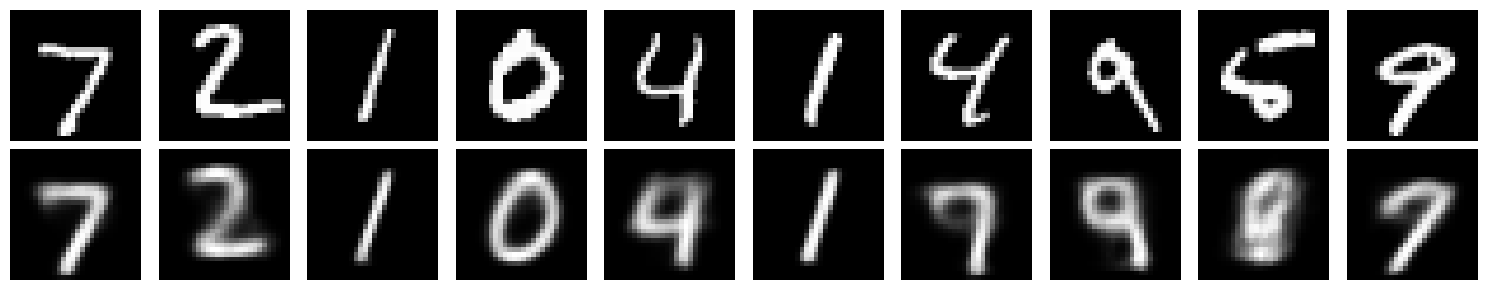

In [33]:
vae.eval()

x, _ = next(iter(test_loader))
x = x[:10].to(device)

with torch.no_grad():
    x_hat, _, _ = vae(x)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("VAE")

plt.tight_layout()
plt.show()

# Comparer les images originales et les reconstructions du VAE

Ce code affiche **dix images de test** et leurs **reconstructions par le VAE** :

- **ligne du haut** : images originales ;
- **ligne du bas** : reconstructions.

## 1. Préparer le modèle et les données

```python
vae.eval()

x, _ = next(iter(test_loader))
x = x[:10].to(device)
```

- `vae.eval()` active le mode évaluation, notamment pour les couches comme `Dropout` et `BatchNorm`.
- `next(iter(test_loader))` récupère un premier lot de test.
- `x, _` conserve les images et ignore les étiquettes.
- `x[:10]` sélectionne les dix premières images.
- `.to(device)` place les images sur le même périphérique que le modèle.

> Le lot doit contenir au moins dix images pour que la boucle d’affichage fonctionne.

## 2. Reconstruire les images

```python
with torch.no_grad():
    x_hat, _, _ = vae(x)
```

- `torch.no_grad()` désactive le suivi des gradients, inutile pour cette visualisation.
- `vae(x)` renvoie les reconstructions, les moyennes latentes `mu` et les logarithmes des variances `logvar`.
- `x_hat, _, _` conserve uniquement les reconstructions.

```text
Images → Encodeur → Échantillonnage latent → Décodeur → Reconstructions
```

> `eval()` ne supprime pas automatiquement l’échantillonnage latent. Si le VAE continue à échantillonner, ses reconstructions peuvent varier entre deux exécutions.

## 3. Créer la grille

```python
fig, axes = plt.subplots(2, 10, figsize=(15, 3))
```

Cette instruction crée une figure de **deux lignes et dix colonnes**.

- `fig` représente la figure complète.
- `axes[0, i]` désigne la case de l’image originale `i`.
- `axes[1, i]` désigne la case de sa reconstruction.
- `figsize=(15, 3)` fixe la taille en pouces.

## 4. Afficher les paires d’images

```python
for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")
```

Pour chaque colonne, on affiche l’original et sa reconstruction.

| Instruction | Rôle |
|---|---|
| `x[i]` / `x_hat[i]` | Sélectionner une image |
| `.cpu()` | Ramener les données sur le CPU pour Matplotlib |
| `.squeeze()` | Passer ici de `[1, 28, 28]` à `[28, 28]` |
| `imshow(...)` | Afficher l’image |
| `cmap="gray"` | Utiliser des niveaux de gris |
| `axis("off")` | Masquer les axes et les graduations |

Pour comparer fidèlement les intensités d’images dans `[0, 1]`, on peut fixer la même échelle pour tous les affichages :

```python
imshow(image, cmap="gray", vmin=0, vmax=1)
```

Sans ces limites, Matplotlib adapte généralement le contraste séparément pour chaque image.

## 5. Finaliser l’affichage

```python
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("VAE")

plt.tight_layout()
plt.show()
```

- `set_ylabel(...)` définit les noms des lignes.
- `tight_layout()` ajuste les espacements.
- `show()` affiche la figure.

**Attention :** `axis("off")` masque aussi les étiquettes créées avec `set_ylabel()`. Pour les rendre visibles, on peut remplacer ces deux appels par du texte indépendant des axes :

```python
for row, label in enumerate(["Original", "VAE"]):
    axes[row, 0].text(
        -0.15, 0.5, label,
        transform=axes[row, 0].transAxes,
        rotation=90,
        va="center",
        ha="right"
    )
```

## À retenir

**Ce code permet d’évaluer visuellement la reconstruction du VAE : conservation des formes, netteté des contours et perte éventuelle de détails.** Il ne modifie pas le modèle et ne remplace pas une évaluation quantitative sur l’ensemble du jeu de test.

# **12. Visualisation de l'espace latent du VAE**

Nous utilisons ici le vecteur moyen \(\mu\) comme représentation latente.

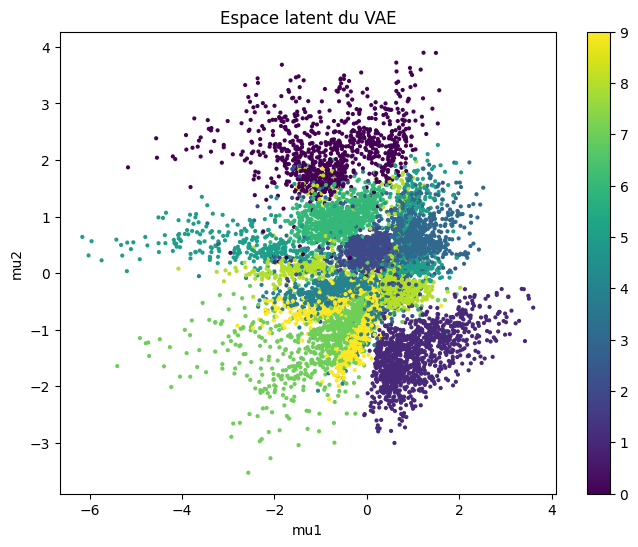

In [34]:
vae.eval()

mus = []
ys = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)

        mu, logvar = vae.encode(x)

        mus.append(mu.cpu())
        ys.append(y)

MU = torch.cat(mus).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    MU[:, 0],
    MU[:, 1],
    c=Y,
    s=4
)

plt.xlabel("mu1")
plt.ylabel("mu2")
plt.title("Espace latent du VAE")
plt.colorbar(scatter)
plt.show()

# Visualiser l’espace latent du VAE

Ce code représente chaque image de test par un **point dans le plan**, à partir des moyennes latentes produites par l’encodeur du VAE.

- **Position du point** : les deux coordonnées de `mu`.
- **Couleur du point** : l’étiquette réelle de l’image.

> Avec une dimension latente de deux, ce graphique montre les centres des distributions latentes, et non des vecteurs échantillonnés.

## 1. Préparer le modèle et le stockage

```python
vae.eval()

mus = []
ys = []
```

- `vae.eval()` active le mode évaluation.
- `mus` stockera les moyennes latentes des images.
- `ys` stockera leurs étiquettes, utilisées pour colorer les points.

## 2. Encoder les images de test

```python
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)

        mu, logvar = vae.encode(x)

        mus.append(mu.cpu())
        ys.append(y)
```

Pour chaque lot :

1. `x.to(device)` place les images sur le périphérique du modèle.
2. `vae.encode(x)` calcule les paramètres des distributions latentes :
   - `mu` : les moyennes ;
   - `logvar` : les logarithmes des variances.
3. `mu.cpu()` ramène les moyennes sur le CPU pour leur future conversion en NumPy.
4. Les moyennes et les étiquettes sont ajoutées aux listes, dans le même ordre.

`torch.no_grad()` désactive le suivi des gradients, inutile ici.

Pour un lot de `B` images et une dimension latente de deux :

```text
x      : [B, 1, 28, 28]
mu     : [B, 2]
logvar : [B, 2]
y      : [B]
```

### Pourquoi afficher `mu` plutôt que `z` ?

Le VAE échantillonne généralement un vecteur latent selon :

$$
z = \mu + \sigma \odot \varepsilon,
\qquad
\varepsilon \sim \mathcal{N}(0, I)
$$

Afficher `mu` évite le bruit introduit par cet échantillonnage et montre le **centre de la distribution associée à chaque image**.

> `logvar` n’est pas utilisé dans ce graphique : la dispersion et l’incertitude des distributions latentes ne sont donc pas représentées.

## 3. Regrouper les résultats

```python
MU = torch.cat(mus).numpy()
Y = torch.cat(ys).numpy()
```

- `torch.cat(...)` concatène les lots sur la première dimension.
- `.numpy()` convertit les tenseurs CPU en tableaux NumPy.

Si `N` images ont été parcourues :

```text
MU : [N, 2] → coordonnées moyennes
Y  : [N]    → étiquettes correspondantes
```

Ainsi, `MU[i]` et `Y[i]` concernent la même image.

> Le code suppose que les étiquettes `y` sont déjà sur le CPU, comme avec un `DataLoader` classique.

## 4. Tracer le nuage de points

```python
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    MU[:, 0],
    MU[:, 1],
    c=Y,
    s=4
)
```

| Élément | Rôle |
|---|---|
| `figsize=(8, 6)` | Fixer la taille de la figure en pouces |
| `MU[:, 0]` | Coordonnées horizontales : première composante de `mu` |
| `MU[:, 1]` | Coordonnées verticales : deuxième composante de `mu` |
| `c=Y` | Colorer les points selon les étiquettes réelles |
| `s=4` | Utiliser de petits marqueurs |
| `scatter` | Conserver l’objet graphique pour créer la barre de couleurs |

Les étiquettes servent uniquement à la visualisation : elles ne sont pas transmises à l’encodeur.

## 5. Ajouter les indications et afficher

```python
plt.xlabel("mu1")
plt.ylabel("mu2")
plt.title("Espace latent du VAE")
plt.colorbar(scatter)
plt.show()
```

Ces instructions ajoutent :

- les noms des coordonnées latentes ;
- un titre ;
- une barre reliant les couleurs aux étiquettes ;
- l’affichage final.

Pour des classes comme les chiffres de MNIST, une palette discrète peut être plus lisible :

```python
scatter = plt.scatter(
    MU[:, 0], MU[:, 1],
    c=Y, s=4,
    cmap=plt.get_cmap("tab10"),
    vmin=-0.5, vmax=9.5
)

plt.colorbar(scatter, ticks=range(10), label="Chiffre réel")
```

## 6. Interpréter le graphique

- **Points d’une même couleur regroupés** : des images de cette classe ont des moyennes latentes proches.
- **Couleurs mélangées** : plusieurs classes occupent des régions proches. Ce n’est pas nécessairement un échec, car le VAE n’est pas entraîné à classifier.
- **Points très concentrés près de l’origine** : cela peut refléter l’effet de la régularisation KL, mais ne suffit pas à diagnostiquer un *posterior collapse*.

Le terme KL rapproche les distributions latentes du prior normal standard. Il ne garantit ni des classes séparées, ni une distribution normale des seuls points `mu`.

> Si l’espace latent possède plus de deux dimensions, ce code n’affiche que les deux premières. S’il n’en possède qu’une, l’accès à `MU[:, 1]` provoque une erreur.

## À retenir

**Ce graphique montre comment le VAE organise les centres des distributions latentes des images de test, en les colorant selon leur classe réelle.** Il aide à explorer les regroupements, mais ne montre ni les variances latentes ni, à lui seul, la qualité des reconstructions.

## 13. Générer de nouvelles images

C'est le point essentiel.

Nous n'avons maintenant plus besoin d'une image d'entrée.

Nous échantillonnons directement :
$$
\
z \sim \mathcal N(0,I)
\
$$

puis :
$$
\
x_{new}=Decoder(z)
\
$$

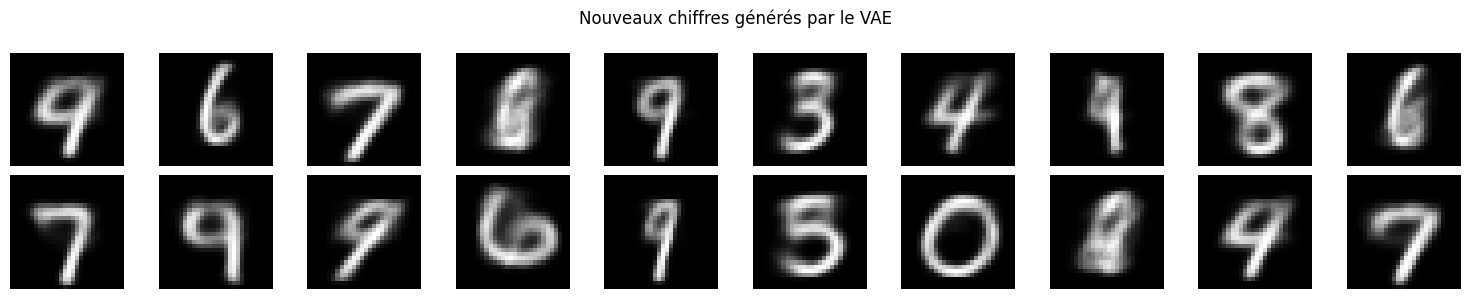

In [ ]:
# Générer de nouvelles images
vae.eval()

with torch.no_grad():
    z = torch.randn(20, 2).to(device)
    samples = vae.decode(z).cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i].squeeze(), cmap="gray")
    ax.axis("off")

plt.suptitle("Nouveaux chiffres générés par le VAE")
plt.tight_layout()
plt.show()

# Visualiser l’espace latent du VAE

Ce code représente chaque image de test par un **point dans le plan**, à partir des moyennes latentes produites par l’encodeur du VAE.

- **Position du point** : les deux coordonnées de `mu`.
- **Couleur du point** : l’étiquette réelle de l’image.

> Avec une dimension latente de deux, ce graphique montre les centres des distributions latentes, et non des vecteurs échantillonnés.

## 1. Préparer le modèle et le stockage

```python
vae.eval()

mus = []
ys = []
```

- `vae.eval()` active le mode évaluation.
- `mus` stockera les moyennes latentes des images.
- `ys` stockera leurs étiquettes, utilisées pour colorer les points.

## 2. Encoder les images de test

```python
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)

        mu, logvar = vae.encode(x)

        mus.append(mu.cpu())
        ys.append(y)
```

Pour chaque lot :

1. `x.to(device)` place les images sur le périphérique du modèle.
2. `vae.encode(x)` calcule les paramètres des distributions latentes :
   - `mu` : les moyennes ;
   - `logvar` : les logarithmes des variances.
3. `mu.cpu()` ramène les moyennes sur le CPU pour leur future conversion en NumPy.
4. Les moyennes et les étiquettes sont ajoutées aux listes, dans le même ordre.

`torch.no_grad()` désactive le suivi des gradients, inutile ici.

Pour un lot de `B` images et une dimension latente de deux :

```text
x      : [B, 1, 28, 28]
mu     : [B, 2]
logvar : [B, 2]
y      : [B]
```

### Pourquoi afficher `mu` plutôt que `z` ?

Le VAE échantillonne généralement un vecteur latent selon :

$$
z = \mu + \sigma \odot \varepsilon,
\qquad
\varepsilon \sim \mathcal{N}(0, I)
$$

Afficher `mu` évite le bruit introduit par cet échantillonnage et montre le **centre de la distribution associée à chaque image**.

> `logvar` n’est pas utilisé dans ce graphique : la dispersion et l’incertitude des distributions latentes ne sont donc pas représentées.

## 3. Regrouper les résultats

```python
MU = torch.cat(mus).numpy()
Y = torch.cat(ys).numpy()
```

- `torch.cat(...)` concatène les lots sur la première dimension.
- `.numpy()` convertit les tenseurs CPU en tableaux NumPy.

Si `N` images ont été parcourues :

```text
MU : [N, 2] → coordonnées moyennes
Y  : [N]    → étiquettes correspondantes
```

Ainsi, `MU[i]` et `Y[i]` concernent la même image.

> Le code suppose que les étiquettes `y` sont déjà sur le CPU, comme avec un `DataLoader` classique.

## 4. Tracer le nuage de points

```python
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    MU[:, 0],
    MU[:, 1],
    c=Y,
    s=4
)
```

| Élément | Rôle |
|---|---|
| `figsize=(8, 6)` | Fixer la taille de la figure en pouces |
| `MU[:, 0]` | Coordonnées horizontales : première composante de `mu` |
| `MU[:, 1]` | Coordonnées verticales : deuxième composante de `mu` |
| `c=Y` | Colorer les points selon les étiquettes réelles |
| `s=4` | Utiliser de petits marqueurs |
| `scatter` | Conserver l’objet graphique pour créer la barre de couleurs |

Les étiquettes servent uniquement à la visualisation : elles ne sont pas transmises à l’encodeur.

## 5. Ajouter les indications et afficher

```python
plt.xlabel("mu1")
plt.ylabel("mu2")
plt.title("Espace latent du VAE")
plt.colorbar(scatter)
plt.show()
```

Ces instructions ajoutent :

- les noms des coordonnées latentes ;
- un titre ;
- une barre reliant les couleurs aux étiquettes ;
- l’affichage final.

Pour des classes comme les chiffres de MNIST, une palette discrète peut être plus lisible :

```python
scatter = plt.scatter(
    MU[:, 0], MU[:, 1],
    c=Y, s=4,
    cmap=plt.get_cmap("tab10"),
    vmin=-0.5, vmax=9.5
)

plt.colorbar(scatter, ticks=range(10), label="Chiffre réel")
```

## 6. Interpréter le graphique

- **Points d’une même couleur regroupés** : des images de cette classe ont des moyennes latentes proches.
- **Couleurs mélangées** : plusieurs classes occupent des régions proches. Ce n’est pas nécessairement un échec, car le VAE n’est pas entraîné à classifier.
- **Points très concentrés près de l’origine** : cela peut refléter l’effet de la régularisation KL, mais ne suffit pas à diagnostiquer un *posterior collapse*.

Le terme KL rapproche les distributions latentes du prior normal standard. Il ne garantit ni des classes séparées, ni une distribution normale des seuls points `mu`.

> Si l’espace latent possède plus de deux dimensions, ce code n’affiche que les deux premières. S’il n’en possède qu’une, l’accès à `MU[:, 1]` provoque une erreur.

## À retenir

**Ce graphique montre comment le VAE organise les centres des distributions latentes des images de test, en les colorant selon leur classe réelle.** Il aide à explorer les regroupements, mais ne montre ni les variances latentes ni, à lui seul, la qualité des reconstructions.

## 14. Explorer manuellement l'espace latent

Avec un espace latent 2D, nous pouvons construire une grille de points et observer les images produites par le décodeur.

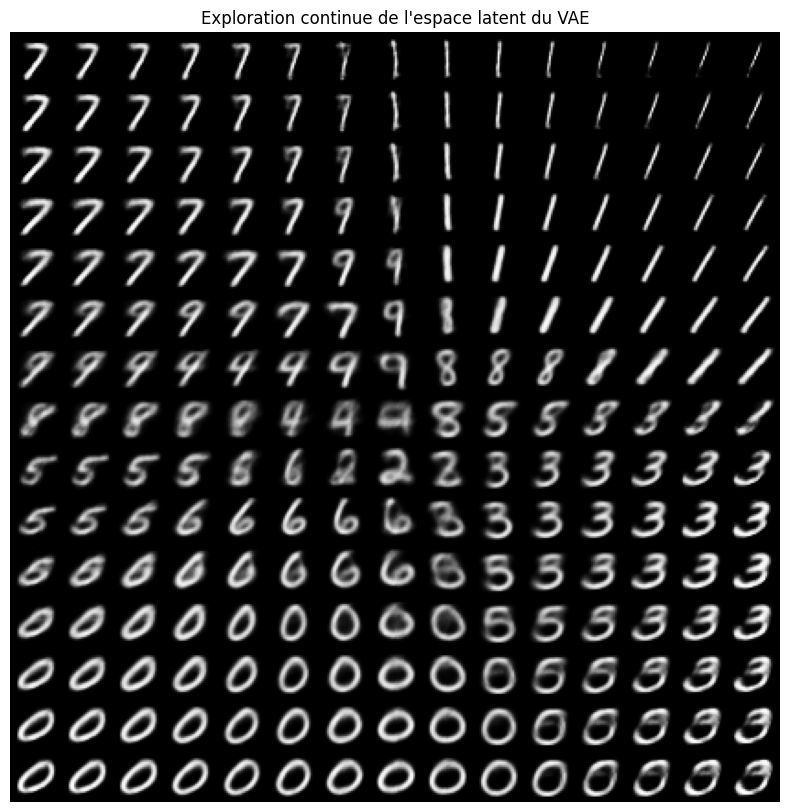

In [38]:
vae.eval()

grid_x = np.linspace(-3, 3, 15)
grid_y = np.linspace(-3, 3, 15)

figure = np.zeros((28 * 15, 28 * 15))

with torch.no_grad():
    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):

            z = torch.tensor(
                [[xi, yi]],
                dtype=torch.float32,
                device=device
            )

            x_hat = vae.decode(z)
            digit = x_hat.cpu().numpy()[0, 0]

            figure[
                i*28:(i+1)*28,
                j*28:(j+1)*28
            ] = digit

plt.figure(figsize=(10, 10))
plt.imshow(figure, cmap="gray")
plt.axis("off")
plt.title("Exploration continue de l'espace latent du VAE")
plt.show()

# Exploration de l’espace latent d’un VAE

Ce code permet de **visualiser ce qu’un VAE a appris à générer** en explorant son espace latent à deux dimensions.

L’idée générale est simple :

> On choisit plusieurs points dans l’espace latent. Pour chaque point, le décodeur génère une image. On rassemble ensuite toutes ces images dans une grande mosaïque.

Ici, on génère **15 × 15 = 225 images**, chacune de taille **28 × 28 pixels**.

---

## 1. Rappel : qu’est-ce que l’espace latent d’un VAE ?

Un **VAE**, ou *autoencodeur variationnel*, comporte deux parties :

- **L’encodeur** transforme une image en une représentation latente probabiliste.
- **Le décodeur** transforme un vecteur latent `z` en une image.

Schématiquement :

    Image → Encodeur → Espace latent → Décodeur → Image reconstruite

Dans ton code, on utilise **uniquement le décodeur** :

    Un point z = [x, y] → Décodeur → Image générée

On suppose donc ici que le VAE possède un **espace latent de dimension 2** : chaque vecteur latent est composé de deux nombres.

Tu peux imaginer cet espace comme une carte :

- la coordonnée `x` indique une position horizontale ;
- la coordonnée `y` indique une position verticale ;
- à chaque position, le décodeur produit une image.

**Le but du code est de dessiner cette carte.**

---

## 2. Passer le modèle en mode évaluation

    vae.eval()

Cette instruction place le modèle en **mode évaluation**, par opposition au mode entraînement.

Elle adapte le comportement de certaines couches, si le modèle en possède :

- `Dropout` ne désactive plus aléatoirement des neurones ;
- `BatchNorm` utilise normalement ses statistiques accumulées pendant l’entraînement.

**Attention :** `eval()` ne désactive pas le calcul des gradients. C’est le rôle de `torch.no_grad()`, utilisé plus bas.

---

## 3. Choisir les coordonnées à explorer

    grid_x = np.linspace(-3, 3, 15)
    grid_y = np.linspace(-3, 3, 15)

`np.linspace(a, b, n)` génère `n` valeurs régulièrement espacées entre `a` et `b`, bornes incluses.

Ici :

    grid_x ≈ [-3.00, -2.57, -2.14, ..., 0.00, ..., 2.57, 3.00]
    grid_y ≈ [-3.00, -2.57, -2.14, ..., 0.00, ..., 2.57, 3.00]

On dispose donc de :

- **15 coordonnées horizontales** ;
- **15 coordonnées verticales**.

En combinant chaque valeur de `x` avec chaque valeur de `y`, on obtient **225 points** :

                   x
           -3    ...     0    ...     3

    y=-3   •     •      •     •      •
           •     •      •     •      •
    y=0    •     •      •     •      •
           •     •      •     •      •
    y=3    •     •      •     •      •

### Pourquoi explorer de −3 à 3 ?

Dans un VAE classique, l’espace latent est régularisé pour se rapprocher d’une loi normale standard :

$$
z \sim \mathcal{N}(0, I)
$$

Pour chaque coordonnée, la plupart des valeurs de cette distribution se trouvent entre `-3` et `3`.

Cette plage est donc un choix courant pour explorer l’espace latent.

Toutefois, **les zones proches du centre sont plus probables que les coins** de cette grille. La qualité des images peut donc varier selon les régions.

---

## 4. Préparer une grande image vide

    figure = np.zeros((28 * 15, 28 * 15))

Chaque image générée mesure **28 × 28 pixels**.

Pour afficher 15 images par ligne et 15 images par colonne, il faut une grande image de :

$$
28 \times 15 = 420
$$

On crée donc un tableau de taille :

    figure.shape  # (420, 420)

Ce tableau est rempli de zéros.

On va remplir cette grande image **bloc par bloc**, comme un carrelage :

    ┌──────────┬──────────┬─────┐
    │ Image 1  │ Image 2  │ ... │
    │  28×28   │  28×28   │     │
    ├──────────┼──────────┼─────┤
    │ Image 16 │ Image 17 │ ... │
    │  28×28   │  28×28   │     │
    ├──────────┼──────────┼─────┤
    │   ...    │   ...    │ ... │
    └──────────┴──────────┴─────┘

---

## 5. Désactiver le calcul des gradients

    with torch.no_grad():

Pendant l’entraînement, PyTorch enregistre les opérations nécessaires au calcul des gradients.

Ici, on veut simplement **générer des images**, pas modifier les poids du modèle.

`torch.no_grad()` évite donc cet enregistrement :

- cela économise de la mémoire ;
- cela réduit les calculs inutiles.

Les deux instructions sont complémentaires :

    vae.eval()             # Comportement du modèle en évaluation
    with torch.no_grad():  # Pas de suivi des gradients
        ...

---

## 6. Parcourir les points de la grille

    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):

`enumerate()` fournit à la fois :

- **l’indice** d’un élément ;
- **sa valeur**.

Par exemple :

    for i, yi in enumerate(grid_y):

donne successivement :

    i = 0, yi = -3.00
    i = 1, yi ≈ -2.57
    ...
    i = 14, yi = 3.00

Les rôles des variables sont :

| Variable | Rôle |
|---|---|
| `i` | Numéro de ligne dans la mosaïque |
| `j` | Numéro de colonne dans la mosaïque |
| `yi` | Deuxième coordonnée du point latent |
| `xi` | Première coordonnée du point latent |

**Il faut bien distinguer les indices `i`, `j` des coordonnées `xi`, `yi`.**

- Les indices servent à **placer l’image dans la mosaïque**.
- Les coordonnées servent à **générer l’image avec le décodeur**.

La boucle parcourt une ligne complète avant de passer à la suivante.

---

## 7. Construire un vecteur latent

    z = torch.tensor(
        [[xi, yi]],
        dtype=torch.float32,
        device=device
    )

Pour chaque position, on crée un tenseur contenant le point latent.

Au tout premier passage, il contient :

    [[-3.0, -3.0]]

### Pourquoi deux paires de crochets ?

    [[xi, yi]]

Le décodeur attend généralement un **lot d’exemples**, ou *batch*, même lorsqu’on ne lui donne qu’un seul exemple.

La forme de `z` est donc :

    z.shape  # (1, 2)

Ce qui signifie :

    1 vecteur latent
    2 valeurs dans ce vecteur

Avec une seule paire de crochets, `[xi, yi]`, la forme serait `(2,)` : la dimension du batch manquerait.

### À quoi servent les autres arguments ?

    dtype=torch.float32

Les coordonnées sont stockées comme nombres flottants en précision 32 bits, le format habituel des modèles PyTorch.

    device=device

Le tenseur est créé sur le périphérique choisi, par exemple le CPU ou le GPU.

**Le tenseur et le décodeur doivent être sur le même périphérique.**

---

## 8. Générer l’image

    x_hat = vae.decode(z)

On transmet le point latent au décodeur.

Il produit une image :

    z = [xi, yi] → Décodeur → Image de 28 × 28 pixels

Le nom `x_hat`, souvent noté $\hat{x}$, désigne une image produite ou reconstruite par le modèle.

Dans ce code, **on ne reconstruit pas une image d’entrée particulière** : on génère une image à partir d’un point latent choisi manuellement.

La ligne suivante suppose que la sortie a cette forme :

    x_hat.shape  # (1, 1, 28, 28)

Soit :

    (batch, canaux, hauteur, largeur)
       1      1       28       28

Il y a un seul canal, car l’image est en niveaux de gris.

---

## 9. Récupérer une image NumPy de taille 28 × 28

    digit = x_hat.cpu().numpy()[0, 0]

Décomposons cette ligne.

### `x_hat.cpu()`

Transfère le tenseur sur le CPU s’il est sur le GPU.

### `.numpy()`

Convertit le tenseur en tableau NumPy, utilisable pour remplir `figure`.

Ici, les calculs ayant été effectués sous `torch.no_grad()`, il n’est normalement pas nécessaire d’ajouter `.detach()`.

### `[0, 0]`

Sélectionne :

- l’image d’indice `0` dans le batch ;
- son canal d’indice `0`.

Ainsi :

    Avant : (1, 1, 28, 28)
    Après :       (28, 28)

`digit` contient maintenant les intensités des pixels de l’image générée.

---

## 10. Placer l’image dans la mosaïque

    figure[
        i*28:(i+1)*28,
        j*28:(j+1)*28
    ] = digit

C’est la partie qui place chaque petite image au bon endroit.

Dans un tableau NumPy à deux dimensions :

    tableau[lignes, colonnes]

On sélectionne donc :

    i*28:(i+1)*28  # Les 28 lignes du bloc
    j*28:(j+1)*28  # Les 28 colonnes du bloc

La borne de fin est **exclue**, comme d’habitude en Python.

### Exemple 1 : première image

Pour `i = 0` et `j = 0` :

    figure[0:28, 0:28] = digit

L’image est placée **en haut à gauche**.

### Exemple 2 : deuxième image de la première ligne

Pour `i = 0` et `j = 1` :

    figure[0:28, 28:56] = digit

Elle est placée immédiatement à droite.

### Exemple 3 : première image de la deuxième ligne

Pour `i = 1` et `j = 0` :

    figure[28:56, 0:28] = digit

Elle est placée juste sous la première image.

Après les 225 passages, toute la mosaïque est remplie.

---

## 11. Afficher le résultat

    plt.figure(figsize=(10, 10))

Crée une figure de tracé de **10 × 10 pouces**. Ce n’est pas la résolution du tableau, qui reste de **420 × 420 pixels**.

    plt.imshow(figure, cmap="gray")

Affiche la mosaïque en niveaux de gris.

    plt.axis("off")

Masque les axes et leurs graduations.

    plt.title("Exploration continue de l'espace latent du VAE")

Ajoute un titre.

    plt.show()

Affiche le graphique.

**Petit détail d’orientation :** par défaut, `imshow` place la première ligne en haut. Dans cette mosaïque, `y = -3` est donc en haut et `y = 3` en bas, contrairement à un repère mathématique classique.

---

## 12. Comment interpréter la mosaïque ?

Si ton VAE a été entraîné sur des chiffres manuscrits, chaque case montre un chiffre généré.

- **De gauche à droite**, `xi` varie tandis que `yi` reste fixe sur une même ligne.
- **De haut en bas**, `yi` varie tandis que `xi` reste fixe dans une même colonne.
- **Au centre**, le vecteur latent est `[0, 0]`, car les 15 valeurs incluent zéro.

L’intérêt est d’observer si les images évoluent progressivement :

    Chiffre fin → chiffre plus épais → forme différente → autre chiffre

Les coordonnées latentes ne correspondent toutefois **pas nécessairement à des propriétés explicites** comme « épaisseur » ou « inclinaison ». Le modèle apprend lui-même cette organisation.

Enfin, même si le titre parle d’exploration « continue », le code affiche seulement **225 points d’un espace continu**.

On cherche à voir si des points proches donnent des images qui se ressemblent, avec des transitions progressives.

---

## En résumé

    Créer une grille de 225 points latents
                      ↓
    Décoder chaque point en une image de 28 × 28 pixels
                      ↓
    Placer les images dans une mosaïque de 420 × 420 pixels
                      ↓
    Observer comment les images évoluent dans l’espace latent

**Ce code transforme donc l’espace latent du VAE en une carte visuelle de ce que son décodeur sait générer.**

# **Partie IV — Generative Adversarial Networks**

## 15. Principe des GAN

# Comprendre le principe des GANs

Un **GAN** (*Generative Adversarial Network*), ou **réseau antagoniste génératif**, apprend à produire de nouvelles données ressemblant à celles d’un jeu d’entraînement.

Il repose sur deux réseaux entraînés avec des objectifs opposés :

- le **générateur**, qui crée de fausses données ;
- le **discriminateur**, qui apprend à distinguer les données réelles des données générées.

> **Analogie :** le générateur joue le rôle d’un faussaire, tandis que le discriminateur joue celui d’un expert chargé de détecter les contrefaçons. Chacun pousse l’autre à progresser.

---

## 1. Schéma d’architecture

```text
   Bruit aléatoire z
          │
          ▼
   ┌─────────────┐
   │ Générateur G│
   └──────┬──────┘
          │
          ▼
    Image générée ───────────┐
                             │
                             ▼
                      ┌─────────────────┐
                      │ Discriminateur D│
                      └────────┬────────┘
                             ▲ │
                             │ ▼
    Image réelle ────────────┘ Score « réel »
          ▲                    entre 0 et 1
          │
   Jeu d’entraînement
```

Le discriminateur reçoit une image réelle **ou** une image générée et produit un score :

- proche de **1** : il considère l’image comme réelle ;
- proche de **0** : il considère l’image comme générée.

Ce schéma décrit le GAN classique ; certaines variantes utilisent d’autres types de scores.

---

## 2. Le générateur : créer des images

Le générateur transforme un vecteur aléatoire `z` en une image :

$$
\hat{x} = G(z)
$$

```text
Vecteur aléatoire → Générateur → Image synthétique
```

Le vecteur `z` est souvent tiré dans une loi normale standard :

$$
z \sim \mathcal{N}(0, I)
$$

Au début, les images produites sont généralement peu structurées. Pendant l’entraînement, le générateur apprend à produire des images que le discriminateur considère comme réelles.

> Dans un GAN classique, le générateur ne cherche pas à reconstruire une image précise : il cherche à imiter la distribution des données d’entraînement.

---

## 3. Le discriminateur : distinguer réel et généré

Le discriminateur reçoit :

- des images réelles issues du jeu d’entraînement ;
- des images synthétiques produites par le générateur.

Il apprend à attribuer les bonnes réponses :

| Entrée | Réponse souhaitée pour le discriminateur |
|---|---|
| Image réelle `x` | `1` : réelle |
| Image générée `G(z)` | `0` : générée |

Son objectif est donc de **repérer les erreurs du générateur**.

---

## 4. Comment se déroule l’entraînement ?

On alterne généralement deux étapes.

### Étape A — Entraîner le discriminateur

On lui présente des images réelles et générées, puis on ajuste ses paramètres pour améliorer sa classification.

```text
Images réelles   → D → objectif : 1
Images générées  → D → objectif : 0
```

Pendant cette étape, **les paramètres du générateur ne sont pas mis à jour**.

### Étape B — Entraîner le générateur

On crée de nouvelles images, puis on les fait évaluer par le discriminateur.

Le générateur cherche à obtenir un score « réel » élevé :

```text
Bruit z → G → Image générée → D → objectif du générateur : 1
```

Pendant cette étape :

- les paramètres du discriminateur restent fixes ;
- les gradients traversent néanmoins le discriminateur pour ajuster le générateur.

```text
Retour d’apprentissage :

Erreur → Discriminateur → Générateur
                              ↑
                   Paramètres mis à jour
```

> Le discriminateur fournit ainsi un signal d’apprentissage au générateur, sans qu’il soit nécessaire de lui donner une image cible pour chaque vecteur aléatoire.

---

## 5. Pourquoi parle-t-on d’apprentissage « antagoniste » ?

Les deux réseaux poursuivent des objectifs opposés :

| Réseau | Objectif |
|---|---|
| Générateur | Faire passer ses images pour des images réelles |
| Discriminateur | Détecter les images générées |

Idéalement, le générateur finit par produire des données dont la distribution correspond à celle des données réelles.

À cet équilibre théorique, le discriminateur ne peut plus les distinguer et attribue un score de `0.5`.

> Un score proche de `0.5` ne prouve cependant pas, à lui seul, que le générateur est bon : le discriminateur peut aussi être insuffisamment entraîné.

---

## 6. Générer des images après l’entraînement

Une fois l’entraînement terminé, **seul le générateur est nécessaire** :

```text
Nouveau vecteur aléatoire → Générateur entraîné → Nouvelle image
```

Le discriminateur a servi à guider l’apprentissage, mais il n’est plus indispensable pour produire des images.

---

## 7. Différence essentielle avec un VAE

| VAE | GAN classique |
|---|---|
| Utilise un encodeur et un décodeur | Utilise un générateur et un discriminateur |
| Apprend à reconstruire des entrées et régularise l’espace latent | Apprend à produire des données capables de tromper le discriminateur |
| Utilise une perte de reconstruction et un terme KL | Utilise un objectif adversarial |

Les GANs peuvent produire des images très réalistes, mais leur entraînement peut être instable. Ils peuvent aussi manquer de diversité et produire toujours des exemples similaires : c’est le **mode collapse**.

## À retenir

**Un GAN apprend à générer des données grâce à une compétition : le générateur cherche à tromper le discriminateur, tandis que le discriminateur apprend à détecter ses productions.**

# Implémentation d’un GAN avec PyTorch sur MNIST

## Objectif

Nous allons entraîner un **Generative Adversarial Network (GAN)** pour générer des images de chiffres manuscrits.

Un GAN contient deux réseaux :

- **Le générateur** transforme un vecteur aléatoire en image.
- **Le discriminateur** apprend à distinguer les vraies images des images générées.

Les deux réseaux apprennent en compétition : le générateur cherche à tromper le discriminateur, tandis que le discriminateur cherche à détecter les images artificielles.

> Ce modèle utilise des couches entièrement connectées. Il ne s’agit pas d’un GAN convolutif.

---

## 1. Préparation des données

Nous utilisons le jeu de données **MNIST**, composé d’images de chiffres manuscrits en niveaux de gris.

Chaque image possède :

- un seul canal ;
- une hauteur de 28 pixels ;
- une largeur de 28 pixels.

Un lot d’images possède donc la forme :

`[taille_du_lot, 1, 28, 28]`

### Transformation des pixels

`ToTensor()` transforme les images en tenseurs dont les valeurs sont comprises entre 0 et 1.

`Normalize((0.5,), (0.5,))` applique ensuite :

\[
x_{\text{normalisé}} = \frac{x - 0.5}{0.5}
\]

Les pixels sont alors compris entre **−1 et 1**.

Cette transformation est importante : le générateur utilise une fonction `Tanh` en sortie, qui produit également des valeurs dans cet intervalle.

### Chargement par lots

Le `DataLoader` regroupe les images en lots et mélange les données avec `shuffle=True`.

Les étiquettes MNIST ne sont pas utilisées : ce GAN apprend à générer des chiffres sans recevoir leur classe.

---

In [10]:
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import save_image

# Facilite la reproductibilité, sans la garantir sur tous les matériels.
torch.manual_seed(42)

# Utiliser le GPU CUDA s'il est disponible.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

latent_dim = 100
image_dim = 28 * 28
batch_size = 128
epochs = 20
learning_rate = 0.0002

output_dir = Path("images_generees")
output_dir.mkdir(exist_ok=True)

print(f"Appareil utilisé : {device}")

Appareil utilisé : cpu


**Explications :**
- latent_dim = 100 : chaque image sera générée à partir d’un vecteur aléatoire de 100 nombres.
- image_dim = 784 : une image MNIST mesure (28 \times 28) pixels en niveaux de gris.
- batch_size = 128 : les réseaux traitent jusqu’à 128 images à chaque itération.
- epochs = 20 : l’entraînement parcourt 20 fois le jeu de données.
- learning_rate : contrôle l’amplitude des mises à jour des paramètres.

In [11]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

dataset = datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=transform,
)

loader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True,
)

## 2. Le générateur

Le générateur transforme un vecteur de bruit en image.

Son entrée contient **100 nombres aléatoires**, tirés dans une distribution normale standard.

Son architecture suit le chemin :

**100 → 256 → 512 → 784**

Les 784 valeurs finales correspondent aux pixels d’une image :

\[
784 = 28 \times 28
\]

### Fonctions d’activation

- `LeakyReLU` introduit une non-linéarité et conserve une petite pente pour les valeurs négatives.
- `Tanh` limite les valeurs finales à l’intervalle **[−1, 1]**.

L’opération `view` réorganise ensuite les pixels pour obtenir des images de forme :

`[taille_du_lot, 1, 28, 28]`

> Le générateur ne reçoit pas une image à reconstruire : il apprend à créer une image à partir du bruit.

---

In [12]:
class Generator(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.LeakyReLU(0.2),

            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),

            nn.Linear(512, image_dim),
            nn.Tanh(),
        )

    def forward(self, noise):
        return self.network(noise)


generator = Generator(latent_dim).to(device)

# Le générateur du GAN

Ce réseau transforme un **vecteur de bruit aléatoire** en une **image synthétique**.

```text
Bruit aléatoire → 256 valeurs → 512 valeurs → image_dim pixels
```

> Son objectif, pendant l’entraînement du GAN, sera de produire des images que le discriminateur considère comme réelles.

## 1. Définir le modèle

```python
class Generator(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
```

- `Generator` hérite de `nn.Module`, la classe de base des réseaux PyTorch.
- `latent_dim` est le nombre de valeurs du vecteur aléatoire d’entrée.
- `super().__init__()` initialise les mécanismes nécessaires à PyTorch.

Par exemple, avec `latent_dim=100`, chaque image sera générée à partir de **100 nombres aléatoires**.

## 2. Construire les couches

```python
self.network = nn.Sequential(
    nn.Linear(latent_dim, 256),
    nn.LeakyReLU(0.2),

    nn.Linear(256, 512),
    nn.LeakyReLU(0.2),

    nn.Linear(512, image_dim),
    nn.Tanh(),
)
```

`nn.Sequential` applique les couches dans l’ordre.

| Couche | Rôle |
|---|---|
| `Linear(latent_dim, 256)` | Transformer le bruit en 256 caractéristiques |
| `LeakyReLU(0.2)` | Introduire une non-linéarité |
| `Linear(256, 512)` | Produire 512 caractéristiques intermédiaires |
| `LeakyReLU(0.2)` | Permettre des transformations plus complexes |
| `Linear(512, image_dim)` | Produire les valeurs de l’image |
| `Tanh()` | Ramener les sorties entre `-1` et `1` |

Les couches `Linear` possèdent des poids et des biais qui seront appris pendant l’entraînement.

### Pourquoi `LeakyReLU(0.2)` ?

Cette activation conserve les valeurs positives et multiplie les valeurs négatives par `0.2` :

$$
f(x)=
\begin{cases}
x & \text{si } x \geq 0 \\
0.2x & \text{si } x < 0
\end{cases}
$$

Exemple :

```text
Entrée : [-5, -1, 0, 3]
Sortie : [-1, -0.2, 0, 3]
```

Contrairement à ReLU, elle conserve une pente non nulle pour les valeurs négatives, ce qui facilite la circulation des gradients.

### Pourquoi `Tanh()` ?

`Tanh` contraint les valeurs générées à l’intervalle `[-1, 1]`.

**Les images réelles utilisées pour entraîner le GAN doivent donc être mises à la même échelle**, généralement avec :

```python
x = 2 * x - 1  # Si x était initialement dans [0, 1]
```

## 3. Définir le passage avant

```python
def forward(self, noise):
    return self.network(noise)
```

Cette méthode fait traverser toutes les couches au bruit d’entrée.

Pour un lot de `B` vecteurs :

```text
[B, latent_dim]
       ↓
   [B, 256]
       ↓
   [B, 512]
       ↓
[B, image_dim]
```

> La sortie est ici une **image aplatie**, pas encore une matrice de pixels.

Par exemple, pour des images en niveaux de gris de `28 × 28` pixels :

```python
image_dim = 28 * 28  # 784
```

On pourra ensuite redonner une forme d’image à la sortie :

```python
images = generated.view(-1, 1, 28, 28)
```

## 4. Créer le générateur

```python
generator = Generator(latent_dim).to(device)
```

Cette instruction :

1. construit le réseau ;
2. place ses paramètres sur le CPU ou le GPU indiqué par `device`.

Les variables `latent_dim`, `image_dim` et `device` doivent avoir été définies auparavant.

Exemple d’utilisation :

```python
noise = torch.randn(16, latent_dim, device=device)
generated = generator(noise)
```

Le générateur produit alors **16 images aplaties**.

## À retenir

**Ce générateur apprend à transformer du bruit aléatoire en pixels grâce à des couches entièrement connectées.** Le code définit son architecture, mais ne l’entraîne pas : avant l’apprentissage, ses sorties ne représentent généralement pas des images pertinentes.

## 3. Le discriminateur

Le discriminateur reçoit une image et produit un score unique.

Son architecture suit le chemin :

**784 → 512 → 256 → 1**

La couche `Flatten` transforme chaque image en un vecteur de 784 pixels.

Le score final est un **logit**, c’est-à-dire un score brut :

- un score élevé indique une prédiction plutôt « réelle » ;
- un score faible indique une prédiction plutôt « artificielle ».

### Pourquoi ne pas ajouter de sigmoid ?

Nous utilisons `BCEWithLogitsLoss`.

Cette fonction combine la sigmoid et l’entropie croisée binaire de manière numériquement stable.

Il ne faut donc pas ajouter une seconde sigmoid avant cette perte.

---

In [14]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(image_dim, 512),
            nn.LeakyReLU(0.2),

            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),

            nn.Linear(256, 1),
        )

    def forward(self, images):
        return self.network(images)


discriminator = Discriminator().to(device)

# Le discriminateur du GAN

Ce réseau reçoit une image et produit un **score permettant de distinguer une image réelle d’une image générée**.

```text
Image aplatie → 512 valeurs → 256 valeurs → 1 score
```

> Le générateur crée des images ; le discriminateur apprend à détecter celles qui sont artificielles.

## 1. Définir le modèle

```python
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
```

- `Discriminator` hérite de `nn.Module`, la classe de base des réseaux PyTorch.
- `__init__` définit les composants du réseau.
- `super().__init__()` initialise les mécanismes nécessaires à PyTorch.

## 2. Construire les couches

```python
self.network = nn.Sequential(
    nn.Linear(image_dim, 512),
    nn.LeakyReLU(0.2),

    nn.Linear(512, 256),
    nn.LeakyReLU(0.2),

    nn.Linear(256, 1),
)
```

`nn.Sequential` applique les couches dans l’ordre.

| Couche | Rôle |
|---|---|
| `Linear(image_dim, 512)` | Transformer les pixels en 512 caractéristiques |
| `LeakyReLU(0.2)` | Introduire une non-linéarité |
| `Linear(512, 256)` | Combiner ces informations en 256 caractéristiques |
| `LeakyReLU(0.2)` | Permettre des transformations plus complexes |
| `Linear(256, 1)` | Produire un score unique par image |

Les caractéristiques sont **apprises pendant l’entraînement** : elles ne sont pas définies manuellement.

### Pourquoi `LeakyReLU(0.2)` ?

Cette activation :

- conserve les valeurs positives ;
- multiplie les valeurs négatives par `0.2`.

```text
Entrée : [-5, -1, 0, 3]
Sortie : [-1, -0.2, 0, 3]
```

Elle conserve une pente non nulle du côté négatif, ce qui facilite la circulation des gradients.

## 3. Pourquoi n’y a-t-il pas de sigmoïde à la fin ?

```python
nn.Linear(256, 1)
```

Le réseau produit un **score brut**, appelé **logit**, et non directement une probabilité.

Ce score peut être négatif ou positif, sans être limité à `[0, 1]`.

Avec la convention d’entraînement « réel = 1, généré = 0 » :

- un logit élevé favorise la réponse « réel » ;
- un logit faible favorise la réponse « généré ».

Cette architecture s’utilise généralement avec :

```python
criterion = nn.BCEWithLogitsLoss()
```

Cette fonction combine une sigmoïde et l’entropie croisée binaire de manière numériquement stable.

> Il ne faut pas ajouter de sigmoïde avant `BCEWithLogitsLoss`.

Pour convertir les scores en probabilités lors de leur interprétation :

```python
probabilities = torch.sigmoid(logits)
```

Par exemple :

```text
Logit -2 → probabilité ≈ 0.12
Logit  0 → probabilité = 0.50
Logit  2 → probabilité ≈ 0.88
```

Ces probabilités sont des estimations du modèle, pas des garanties.

## 4. Définir le passage avant

```python
def forward(self, images):
    return self.network(images)
```

Cette méthode fait traverser toutes les couches aux images d’entrée.

Pour un lot de `B` images :

```text
[B, image_dim]
       ↓
   [B, 512]
       ↓
   [B, 256]
       ↓
    [B, 1]
```

### Attention : les images doivent être aplaties

Le réseau ne contient pas de couche `Flatten`.

Pour des images de forme `[B, 1, 28, 28]`, il faut donc les transformer avant l’appel :

```python
images_flat = images.flatten(start_dim=1)
logits = discriminator(images_flat)
```

Avec :

```python
image_dim = 28 * 28  # 784
```

on obtient :

```text
[B, 1, 28, 28] → [B, 784] → Discriminateur → [B, 1]
```

Les sorties du générateur précédent sont déjà aplaties : elles peuvent donc être transmises directement au discriminateur.

## 5. Créer le discriminateur

```python
discriminator = Discriminator().to(device)
```

Cette ligne construit le réseau et place ses paramètres sur le périphérique choisi : CPU ou GPU.

`image_dim` et `device` doivent avoir été définis auparavant. Les images doivent aussi se trouver sur le même périphérique que le modèle.

## À retenir

**Le discriminateur transforme chaque image aplatie en un score brut indiquant si elle semble réelle ou générée.** Pendant l’entraînement du GAN, il apprend à distinguer les deux et fournit au générateur un signal pour améliorer ses images.

## 4. Les optimiseurs

Chaque réseau possède son propre optimiseur Adam :

- `optimizer_g` met à jour le générateur ;
- `optimizer_d` met à jour le discriminateur.

Cette séparation permet d’entraîner alternativement les deux réseaux.

Un vecteur `fixed_noise` est également créé pour la visualisation.

En conservant le même bruit d’une époque à l’autre, nous pouvons observer comment les images associées à ces mêmes entrées évoluent.

---

In [15]:
criterion = nn.BCEWithLogitsLoss()

optimizer_g = torch.optim.Adam(
    generator.parameters(),
    lr=learning_rate,
    betas=(0.5, 0.999),
)

optimizer_d = torch.optim.Adam(
    discriminator.parameters(),
    lr=learning_rate,
    betas=(0.5, 0.999),
)

## 5. Entraîner le discriminateur

Le discriminateur doit reconnaître deux catégories :

| Images présentées | Cible |
|---|---:|
| Images réelles de MNIST | 1 |
| Images produites par le générateur | 0 |

Nous calculons une perte pour chaque catégorie, puis leur moyenne :

\[
L_D = \frac{L_{\text{réelles}} + L_{\text{artificielles}}}{2}
\]

### Le rôle de `detach()`

Lors de cette étape, les images générées sont transmises au discriminateur avec `fake_images.detach()`.

Cette opération coupe le lien avec le graphe de calcul du générateur.

Ainsi, la rétropropagation entraîne le discriminateur sans calculer de gradients pour le générateur.

---

## 6. Entraîner le générateur

Le générateur produit de nouvelles images, qui sont évaluées par le discriminateur.

Cette fois, nous utilisons la cible **1**.

Cela exprime l’objectif suivant :

> Produire des images que le discriminateur considérera comme réelles.

### Pourquoi ne pas utiliser `detach()` ?

Les gradients doivent traverser le discriminateur et revenir jusqu’au générateur.

Utiliser `detach()` empêcherait cet apprentissage.

### Pourquoi geler le discriminateur ?

`discriminator.requires_grad_(False)` empêche le calcul des gradients de ses paramètres pendant cette étape.

Cependant, ses opérations restent dans le graphe de calcul : elles permettent de transmettre le gradient vers le générateur.

**Il ne faut pas entourer ce passage par `torch.no_grad()`, car cela couperait le chemin nécessaire à l’apprentissage du générateur.**

Les paramètres du discriminateur sont ensuite dégelés pour l’itération suivante.

---

In [16]:
# Même bruit à chaque époque pour comparer les résultats.
fixed_noise = torch.randn(64, latent_dim, device=device)

for epoch in range(epochs):
    generator.train()
    discriminator.train()

    total_loss_d = 0.0
    total_loss_g = 0.0

    for real_images, _ in loader:
        # [B, 1, 28, 28] -> [B, 784]
        real_images = real_images.to(device).flatten(start_dim=1)

        # Le dernier lot peut contenir moins de 128 images.
        current_batch_size = real_images.size(0)

        real_labels = torch.ones(
            current_batch_size, 1, device=device
        )
        fake_labels = torch.zeros(
            current_batch_size, 1, device=device
        )

        # =====================================
        # A. Entraîner le discriminateur
        # =====================================
        discriminator.requires_grad_(True)
        optimizer_d.zero_grad(set_to_none=True)

        # Évaluer les vraies images.
        real_scores = discriminator(real_images)
        loss_real = criterion(real_scores, real_labels)

        # Créer de fausses images à partir de bruit.
        noise = torch.randn(
            current_batch_size, latent_dim, device=device
        )
        fake_images = generator(noise)

        # Couper le gradient vers G pendant cette étape.
        fake_scores = discriminator(fake_images.detach())
        loss_fake = criterion(fake_scores, fake_labels)

        loss_d = (loss_real + loss_fake) / 2

        loss_d.backward()
        optimizer_d.step()

        # =====================================
        # B. Entraîner le générateur
        # =====================================
        discriminator.requires_grad_(False)
        optimizer_g.zero_grad(set_to_none=True)

        # Nouvelle évaluation avec D qui vient d'être mis à jour.
        fake_scores = discriminator(fake_images)

        # G veut que ses images soient classées "réelles".
        loss_g = criterion(fake_scores, real_labels)

        loss_g.backward()
        optimizer_g.step()

        total_loss_d += loss_d.item()
        total_loss_g += loss_g.item()

    print(
        f"Époque {epoch + 1:02d}/{epochs} | "
        f"Loss D : {total_loss_d / len(loader):.4f} | "
        f"Loss G : {total_loss_g / len(loader):.4f}"
    )

    # =====================================
    # C. Sauvegarder des exemples
    # =====================================
    generator.eval()

    with torch.no_grad():
        samples = generator(fixed_noise)
        samples = samples.view(-1, 1, 28, 28)

        # [-1, 1] -> [0, 1] pour enregistrer les images.
        samples = (samples + 1) / 2

        save_image(
            samples,
            output_dir / f"epoch_{epoch + 1:03d}.png",
            nrow=8,
        )

# Sauvegarder les paramètres appris.
torch.save(generator.state_dict(), "generator_mnist.pt")

Époque 01/20 | Loss D : 0.4369 | Loss G : 1.4385
Époque 02/20 | Loss D : 0.3508 | Loss G : 2.2724
Époque 03/20 | Loss D : 0.3232 | Loss G : 2.4041
Époque 04/20 | Loss D : 0.3348 | Loss G : 2.2898
Époque 05/20 | Loss D : 0.3205 | Loss G : 2.4570
Époque 06/20 | Loss D : 0.3006 | Loss G : 3.0689
Époque 07/20 | Loss D : 0.2801 | Loss G : 2.5482
Époque 08/20 | Loss D : 0.2664 | Loss G : 2.7624
Époque 09/20 | Loss D : 0.2960 | Loss G : 2.6955
Époque 10/20 | Loss D : 0.2886 | Loss G : 2.5872
Époque 11/20 | Loss D : 0.3188 | Loss G : 2.4879
Époque 12/20 | Loss D : 0.3392 | Loss G : 2.3921
Époque 13/20 | Loss D : 0.3383 | Loss G : 2.1912
Époque 14/20 | Loss D : 0.3420 | Loss G : 2.1960
Époque 15/20 | Loss D : 0.3457 | Loss G : 2.0989
Époque 16/20 | Loss D : 0.3792 | Loss G : 1.9155
Époque 17/20 | Loss D : 0.4148 | Loss G : 1.7215
Époque 18/20 | Loss D : 0.4344 | Loss G : 1.6382
Époque 19/20 | Loss D : 0.4532 | Loss G : 1.5679
Époque 20/20 | Loss D : 0.4649 | Loss G : 1.5327


## 7. Visualiser les résultats

Après chaque époque, nous utilisons le même bruit de référence pour générer des images.

`torch.no_grad()` convient ici, car nous souhaitons uniquement observer les résultats, sans entraîner le modèle.

Les images sont ramenées dans l’intervalle **[0, 1]** :
$$
\
x_{\text{affiché}} = \frac{x_{\text{généré}} + 1}{2}
\
$$

`make_grid` rassemble plusieurs images dans une grille.

`permute(1, 2, 0)` adapte l’ordre des dimensions pour l’affichage avec Matplotlib.

---


In [19]:
# Générer des images
generator.eval()

with torch.no_grad():
    new_noise = torch.randn(16, latent_dim, device=device)

    new_images = generator(new_noise)
    new_images = new_images.view(-1, 1, 28, 28)
    new_images = (new_images + 1) / 2

    save_image(
        new_images,
        output_dir / "nouveaux_chiffres.png",
        nrow=4,
    )

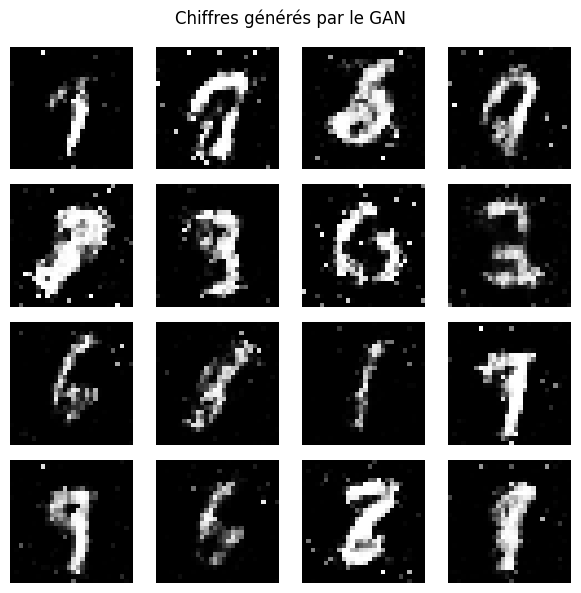

In [23]:
# Générer et visualiser des images
import matplotlib.pyplot as plt
import torch

# Mode évaluation
generator.eval()

# Générer 16 images sans calculer de gradients
with torch.no_grad():
    noise = torch.randn(16, latent_dim, device=device)
    images = generator(noise)

    # [16, 784] -> [16, 1, 28, 28]
    images = images.reshape(-1, 1, 28, 28)

    # Convertir les pixels de [-1, 1] vers [0, 1]
    images = ((images + 1) / 2).clamp(0, 1)

    # Matplotlib utilise les données sur CPU
    images = images.cpu()

# Afficher une grille de 4 × 4
fig, axes = plt.subplots(4, 4, figsize=(6, 6))

for ax, image in zip(axes.flat, images):
    ax.imshow(image.squeeze(0).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

fig.suptitle("Chiffres générés par le GAN")
plt.tight_layout()
plt.show()

## 8. Générer de nouvelles images

Après l’entraînement :

1. nous tirons de nouveaux vecteurs aléatoires ;
2. nous les transmettons au générateur ;
3. nous affichons les images obtenues.

**Le discriminateur n’est plus nécessaire pour générer des images.**

Ce GAN n’est pas conditionnel : nous ne pouvons pas lui demander explicitement de produire un chiffre particulier.

Pour choisir la classe à générer, il faudrait utiliser un **GAN conditionnel**.

---

## 9. Interpréter l’apprentissage

Les pertes d’un GAN ne diminuent pas nécessairement de manière régulière, car les deux réseaux poursuivent des objectifs opposés.

Il faut donc aussi observer :

- la qualité visuelle des images ;
- leur diversité ;
- l’évolution au fil des époques.

Un problème possible est le **mode collapse** : le générateur produit seulement quelques types d’images, même lorsque le bruit varie.

> En résumé : le discriminateur apprend à reconnaître les faux, et le générateur apprend à fabriquer des faux plus convaincants.

# Code Complet du GAN

Époque 01/20 | Loss D : 0.4369 | Loss G : 1.4385
Époque 02/20 | Loss D : 0.3508 | Loss G : 2.2724
Époque 03/20 | Loss D : 0.3232 | Loss G : 2.4041
Époque 04/20 | Loss D : 0.3348 | Loss G : 2.2898
Époque 05/20 | Loss D : 0.3205 | Loss G : 2.4570
Époque 06/20 | Loss D : 0.3006 | Loss G : 3.0689
Époque 07/20 | Loss D : 0.2801 | Loss G : 2.5482
Époque 08/20 | Loss D : 0.2664 | Loss G : 2.7624
Époque 09/20 | Loss D : 0.2960 | Loss G : 2.6955
Époque 10/20 | Loss D : 0.2886 | Loss G : 2.5872
Époque 11/20 | Loss D : 0.3188 | Loss G : 2.4879
Époque 12/20 | Loss D : 0.3392 | Loss G : 2.3921
Époque 13/20 | Loss D : 0.3383 | Loss G : 2.1912
Époque 14/20 | Loss D : 0.3420 | Loss G : 2.1960
Époque 15/20 | Loss D : 0.3457 | Loss G : 2.0989
Époque 16/20 | Loss D : 0.3792 | Loss G : 1.9155
Époque 17/20 | Loss D : 0.4148 | Loss G : 1.7215
Époque 18/20 | Loss D : 0.4344 | Loss G : 1.6382
Époque 19/20 | Loss D : 0.4532 | Loss G : 1.5679
Époque 20/20 | Loss D : 0.4649 | Loss G : 1.5327


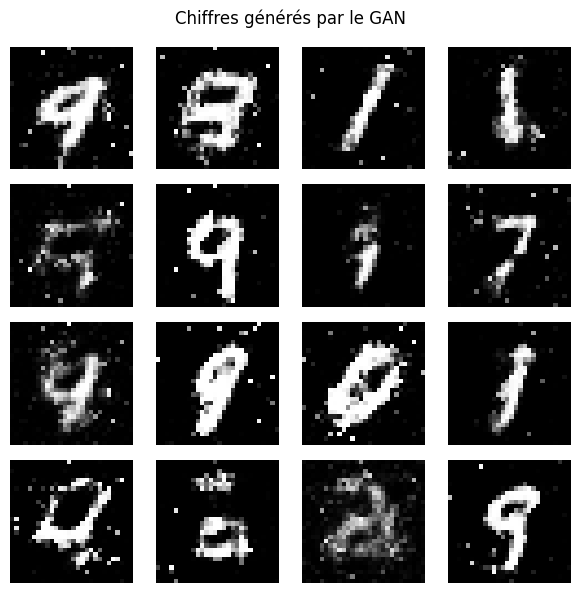

In [48]:
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import save_image

# -------------------------
# Configuration
# -------------------------
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

latent_dim = 100
batch_size = 128
epochs = 20
learning_rate = 2e-4

output_dir = Path("images_generees")
output_dir.mkdir(exist_ok=True)

# -------------------------
# Données : images de 28 × 28
# -------------------------
transform = transforms.Compose([
    transforms.ToTensor(),
    # Passage de [0, 1] à [-1, 1], comme la sortie du générateur
    transforms.Normalize((0.5,), (0.5,)),
])

dataset = datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=transform,
)

loader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True,
)

# -------------------------
# Générateur : bruit -> image
# -------------------------
generator = nn.Sequential(
    nn.Linear(latent_dim, 256),
    nn.LeakyReLU(0.2),

    nn.Linear(256, 512),
    nn.LeakyReLU(0.2),

    nn.Linear(512, 28 * 28),
    nn.Tanh(),  # Pixels dans [-1, 1]
).to(device)

# -------------------------
# Discriminateur : image -> score
# -------------------------
discriminator = nn.Sequential(
    nn.Linear(28 * 28, 512),
    nn.LeakyReLU(0.2),

    nn.Linear(512, 256),
    nn.LeakyReLU(0.2),

    nn.Linear(256, 1),
    # Pas de Sigmoid : inclus dans BCEWithLogitsLoss
).to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer_g = torch.optim.Adam(
    generator.parameters(),
    lr=learning_rate,
    betas=(0.5, 0.999),
)

optimizer_d = torch.optim.Adam(
    discriminator.parameters(),
    lr=learning_rate,
    betas=(0.5, 0.999),
)

# Même bruit à chaque époque pour visualiser la progression
fixed_noise = torch.randn(64, latent_dim, device=device)

# -------------------------
# Entraînement
# -------------------------
for epoch in range(epochs):
    total_loss_d = 0.0
    total_loss_g = 0.0

    for real_images, _ in loader:
        real_images = real_images.to(device).view(-1, 28 * 28)
        current_batch_size = real_images.size(0)

        real_labels = torch.ones(current_batch_size, 1, device=device)
        fake_labels = torch.zeros(current_batch_size, 1, device=device)

        # 1. Entraîner le discriminateur
        discriminator.requires_grad_(True)
        optimizer_d.zero_grad(set_to_none=True)

        real_scores = discriminator(real_images)
        loss_real = criterion(real_scores, real_labels)

        noise = torch.randn(current_batch_size, latent_dim, device=device)
        fake_images = generator(noise)

        # detach() empêche de modifier le générateur pendant cette étape
        fake_scores = discriminator(fake_images.detach())
        loss_fake = criterion(fake_scores, fake_labels)

        loss_d = (loss_real + loss_fake) / 2
        loss_d.backward()
        optimizer_d.step()

        # 2. Entraîner le générateur
        # On fige les paramètres de D, mais on garde le gradient vers G.
        discriminator.requires_grad_(False)
        optimizer_g.zero_grad(set_to_none=True)

        fake_scores = discriminator(fake_images)

        # G cherche à faire classer ses images comme "vraies".
        loss_g = criterion(fake_scores, real_labels)

        loss_g.backward()
        optimizer_g.step()

        total_loss_d += loss_d.item()
        total_loss_g += loss_g.item()

    print(
        f"Époque {epoch + 1:02d}/{epochs} | "
        f"Loss D : {total_loss_d / len(loader):.4f} | "
        f"Loss G : {total_loss_g / len(loader):.4f}"
    )

    # Sauvegarder une grille de 64 images
    generator.eval()
    with torch.no_grad():
        samples = generator(fixed_noise).view(-1, 1, 28, 28)

        # Repasser de [-1, 1] à [0, 1]
        samples = (samples + 1) / 2

        save_image(
            samples,
            output_dir / f"epoch_{epoch + 1:03d}.png",
            nrow=8,
        )
    generator.train()
# Mode évaluation
generator.eval()

# Générer 16 images sans calculer de gradients
with torch.no_grad():
    noise = torch.randn(16, latent_dim, device=device)
    images = generator(noise)

    # [16, 784] -> [16, 1, 28, 28]
    images = images.reshape(-1, 1, 28, 28)

    # Convertir les pixels de [-1, 1] vers [0, 1]
    images = ((images + 1) / 2).clamp(0, 1)

    # Matplotlib utilise les données sur CPU
    images = images.cpu()

# Afficher une grille de 4 × 4
fig, axes = plt.subplots(4, 4, figsize=(6, 6))

for ax, image in zip(axes.flat, images):
    ax.imshow(image.squeeze(0).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

fig.suptitle("Chiffres générés par le GAN")
plt.tight_layout()
plt.show()
# Sauvegarder les poids du générateur
torch.save(generator.state_dict(), "generator_mnist.pt")


# **V- Modèles de diffusion**

# Comprendre les modèles de diffusion

Un **modèle de diffusion** est un modèle génératif qui apprend à créer des données, par exemple des images, en **retirant progressivement du bruit**.

> **Idée centrale :** on apprend au modèle à débruiter des images, puis on utilise cette compétence pour transformer du bruit aléatoire en une nouvelle image.

## 1. Deux processus complémentaires

### La diffusion directe : ajouter du bruit

On part d’une image réelle et on lui ajoute progressivement du bruit gaussien.

```text
Image originale → Image légèrement bruitée → Image très bruitée → Bruit presque pur
      x₀                    x₁                     ...                 xT
```

À mesure que le bruit augmente, les détails puis la structure de l’image disparaissent.

Ce processus est défini par des formules : **il ne nécessite pas de réseau de neurones**.

### La diffusion inverse : apprendre à débruiter

Un réseau apprend à guider le chemin inverse :

```text
Bruit aléatoire → Structure grossière → Détails progressifs → Image générée
      xT                 ...                   x₁                 x₀
```

C’est ce processus inverse qui permet de générer de nouvelles images.

---

## 2. Comment le modèle apprend-il ?

Pendant l’entraînement, on répète les étapes suivantes :

1. Prendre une image réelle.
2. Choisir aléatoirement un niveau de bruit, appelé **temps `t`**.
3. Ajouter un bruit connu à l’image.
4. Donner au réseau l’image bruitée et le temps `t`.
5. Lui demander de prédire le bruit ajouté.
6. Corriger ses paramètres en comparant sa prédiction au bruit réel.

```text
Image réelle x₀ + Bruit connu ε
              │
              ▼
       Image bruitée xₜ ──────┐
                             ▼
Temps t ────────────────► Réseau
                             │
                             ▼
                       Bruit prédit ε̂
                             │
                             ▼
                    Comparaison avec ε
                             │
                             ▼
                  Mise à jour du réseau
```

> La cible est connue automatiquement, puisque c’est nous qui avons ajouté le bruit. Aucune étiquette de classe n’est nécessaire pour cet apprentissage.

---

## 3. Pourquoi donner le temps au réseau ?

Le temps indique **à quel point l’image est bruitée**.

- À faible bruit, il faut surtout corriger de petites perturbations.
- À fort bruit, il faut exploiter davantage les régularités apprises sur les images.

Le réseau doit donc adapter son traitement au niveau de bruit.

On écrit souvent sa prédiction :

$$
\hat{\varepsilon} = \varepsilon_\theta(x_t, t)
$$

où $\theta$ représente ses paramètres appris.

Un **U-Net** est souvent utilisé pour traiter l’image à plusieurs résolutions, même si d’autres architectures sont possibles.

---

## 4. Les deux formules essentielles

### Construire une image bruitée

On peut obtenir directement une image au temps `t` :

$$
x_t =
\sqrt{\bar{\alpha}_t}\,x_0
+
\sqrt{1-\bar{\alpha}_t}\,\varepsilon
$$

avec :

- $x_0$ : l’image originale ;
- $\varepsilon \sim \mathcal{N}(0,I)$ : un bruit gaussien ;
- $\bar{\alpha}_t$ : un coefficient contrôlant la quantité de signal conservée.

Quand $\bar{\alpha}_t$ est proche de `1`, l’image reste peu bruitée. Quand il approche de `0`, le bruit domine.

### Apprendre à prédire le bruit

Une perte courante est l’erreur quadratique moyenne :

$$
\mathcal{L}
=
\mathbb{E}_{x_0,t,\varepsilon}
\left[
\left\|
\varepsilon-\varepsilon_\theta(x_t,t)
\right\|^2
\right]
$$

**Le modèle est pénalisé lorsque le bruit qu’il prédit diffère du bruit ajouté.**

Cette prédiction du bruit est une formulation courante ; d’autres modèles prédisent l’image propre ou une autre quantité équivalente.

---

## 5. Comment génère-t-on une nouvelle image ?

Après l’entraînement :

1. On tire une image de bruit aléatoire.
2. Le réseau prédit le bruit au temps courant.
3. Une formule utilise cette prédiction pour calculer un état moins bruité.
4. On répète jusqu’à obtenir l’image finale.

```text
Tirage aléatoire
       ↓
   Bruit initial
       ↓
Débruitages successifs
       ↓
 Nouvelle image
```

Dans un DDPM classique, les étapes intermédiaires ajoutent aussi un bruit contrôlé : la génération reste probabiliste.

> Le modèle ne retrouve pas une image cachée dans le bruit initial. Il construit une image en s’appuyant sur les régularités apprises dans les données d’entraînement.

---

## 6. Peut-on choisir ce que le modèle génère ?

Oui, en utilisant un modèle **conditionnel**.

On fournit alors une information supplémentaire au réseau :

- une classe, comme « chiffre 7 » ;
- un texte, comme « un chat dans un jardin » ;
- une autre image.

```text
Image bruitée + Temps + Condition → Réseau → Prédiction guidant le débruitage
```

Cette condition doit être prise en compte par l’architecture et l’entraînement : un modèle non conditionnel ne permet pas automatiquement de choisir le contenu généré.

---

## 7. Forces et limites

| Forces | Limites |
|---|---|
| Peuvent produire des images détaillées et variées | Génération souvent coûteuse, car elle comporte plusieurs étapes |
| Entraînement sans discriminateur adversarial | Besoin de données et de ressources de calcul |
| Peuvent être guidés par du texte ou des classes | Qualité sensible à l’entraînement et au processus d’échantillonnage |

## À retenir

**Un modèle de diffusion apprend à débruiter des images à différents niveaux de bruit. Pour générer une nouvelle image, il part de bruit aléatoire et applique progressivement ce débruitage appris.**

## 1. Préparer les données et le périphérique

Ce bloc importe les bibliothèques nécessaires, télécharge MNIST et prépare les images pour l’entraînement.

### Les bibliothèques

- **PyTorch** : construire le réseau, manipuler les tenseurs et calculer les gradients.
- **Torchvision** : charger MNIST et transformer ses images.
- **Matplotlib** : afficher les images et les courbes.
- **`math`** : utiliser des fonctions et constantes mathématiques.

### Choisir CPU ou GPU

`device` sélectionne un GPU compatible CUDA s’il est disponible, sinon le CPU.

Les données et le modèle doivent se trouver sur le même périphérique.

`torch.manual_seed(42)` fixe la graine des nombres aléatoires pour faciliter la reproductibilité, sans garantir des résultats identiques dans toutes les configurations.

### Transformer les images

Les transformations sont appliquées dans cet ordre :

1. `ToTensor()` transforme l’image en tenseur avec des pixels dans `[0, 1]`.
2. `Normalize((0.5,), (0.5,))` applique :

$$
x_{\text{normalisé}} = \frac{x - 0.5}{0.5} = 2x - 1
$$

Les pixels se retrouvent donc dans `[-1, 1]`.

### Créer les lots

`DataLoader` fournit des lots de 128 images et mélange leur ordre à chaque parcours.

Chaque lot possède généralement la forme :

$$
[B, 1, 28, 28]
$$

avec `B` le nombre d’images et `1` le nombre de canaux.

- `num_workers=0` charge les données dans le processus principal, pratique dans un notebook.
- `pin_memory=True` peut faciliter les transferts vers un GPU CUDA.

**Les étiquettes ne serviront pas à l’entraînement : le modèle apprendra à générer des chiffres sans recevoir leur classe.**

In [25]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Périphérique :", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

Périphérique : cpu


## 2. Définir comment ajouter du bruit

La diffusion transforme progressivement une image réelle en bruit.

Le code définit `T = 200` niveaux de bruit.

### Le calendrier de bruit

`cosine_beta_schedule` construit une progression fondée sur une fonction cosinus.

Les coefficients ont les rôles suivants :

| Coefficient | Signification |
|---|---|
| `betas[t]` | Variance du bruit ajouté à une étape |
| `alphas[t] = 1 - betas[t]` | Facteur de conservation du signal à cette étape |
| `alpha_bars[t]` | Produit cumulé des `alphas` jusqu’à cette étape |

À mesure que le temps avance, `alpha_bars` diminue : l’image conserve moins de signal et contient davantage de bruit.

### Bruiter directement une image

La fonction `add_noise` applique :

$$
x_t =
\sqrt{\bar{\alpha}_t}\,x_0
+
\sqrt{1-\bar{\alpha}_t}\,\varepsilon
$$

où :

- $x_0$ est l’image originale ;
- $\varepsilon$ est un bruit normal standard ;
- $x_t$ est l’image bruitée.

Il n’est donc pas nécessaire d’exécuter toutes les étapes précédentes pour obtenir une image au temps `t`.

La fonction renvoie **l’image bruitée et le bruit utilisé**, qui servira de cible pendant l’entraînement.

### Le rôle de `extract`

Chaque image du lot peut recevoir un temps différent.

`extract(values, t)` sélectionne un coefficient par image et lui donne la forme `[B, 1, 1, 1]`, pour l’appliquer à tous les pixels de cette image.

### Préparer le processus inverse

`alpha_bars_prev` contient les valeurs cumulées de l’étape précédente.

`posterior_variance` définit la variance utilisée pendant la génération :

$$
\tilde{\beta}_t
=
\beta_t
\frac{1-\bar{\alpha}_{t-1}}
     {1-\bar{\alpha}_t}
$$

**Attention :** les indices du code vont de `0` à `T-1`. L’indice `0` représente déjà une première petite étape de bruitage.

In [26]:
T = 200

def cosine_beta_schedule(timesteps, s=0.008):
    steps = torch.linspace(0, timesteps, timesteps + 1)

    alpha_bar = torch.cos(
        ((steps / timesteps + s) / (1 + s)) * math.pi / 2
    ).pow(2)

    alpha_bar = alpha_bar / alpha_bar[0]

    betas = 1 - alpha_bar[1:] / alpha_bar[:-1]

    return betas.clamp(min=1e-4, max=0.999)


betas = cosine_beta_schedule(T).to(device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

alpha_bars_prev = torch.cat([
    torch.ones(1, device=device),
    alpha_bars[:-1]
])

# Variance utilisée pendant la génération.
posterior_variance = (
    betas * (1 - alpha_bars_prev) / (1 - alpha_bars)
)


def extract(values, t):
    """Sélectionner un coefficient par image et permettre le broadcasting."""
    return values[t].view(-1, 1, 1, 1)


def add_noise(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)

    signal = extract(alpha_bars.sqrt(), t)
    noise_scale = extract((1 - alpha_bars).sqrt(), t)

    xt = signal * x0 + noise_scale * noise

    return xt, noise

## 3. Observer la dégradation progressive d’une image

Ce bloc affiche une image MNIST à plusieurs niveaux de bruit.

### Préparer une image

`train_dataset[0]` récupère la première image.

`unsqueeze(0)` ajoute une dimension de lot :

$$
[1, 28, 28] \rightarrow [1, 1, 28, 28]
$$

L’image est ensuite placée sur le périphérique du modèle.

### Comparer plusieurs temps

La liste `times` contient les niveaux de bruit à visualiser.

Pour chaque temps, `add_noise` calcule une version bruitée de l’image.

Le même tenseur de bruit est réutilisé pour faciliter la comparaison. Cela illustre la formule de bruitage à différents temps, et non une simulation étape par étape avec des bruits indépendants.

### Lire le résultat

- Au début, le chiffre est encore bien visible.
- Aux temps intermédiaires, les détails disparaissent.
- À la fin, l’image ressemble presque entièrement à du bruit.

`vmin=-1` et `vmax=1` fixent une échelle d’affichage commune.

> Les images bruitées peuvent contenir des valeurs hors de `[-1, 1]`. Ces valeurs sont saturées visuellement par Matplotlib, mais les tenseurs ne sont pas modifiés.

**Cette visualisation montre le problème que le réseau devra apprendre à inverser.**

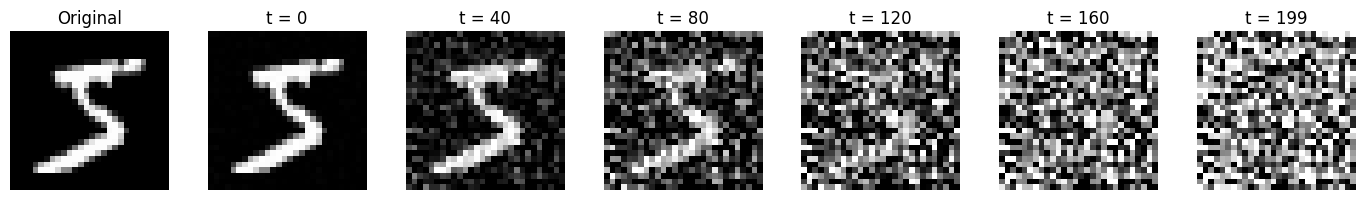

In [27]:
x0, _ = train_dataset[0]
x0 = x0.unsqueeze(0).to(device)

times = [0, 40, 80, 120, 160, 199]
noise = torch.randn_like(x0)

fig, axes = plt.subplots(1, len(times) + 1, figsize=(14, 2))

axes[0].imshow(
    x0[0, 0].cpu(),
    cmap="gray",
    vmin=-1,
    vmax=1
)
axes[0].set_title("Original")
axes[0].axis("off")

for ax, step in zip(axes[1:], times):
    t = torch.tensor([step], device=device)
    xt, _ = add_noise(x0, t, noise)

    ax.imshow(
        xt[0, 0].cpu(),
        cmap="gray",
        vmin=-1,
        vmax=1
    )
    ax.set_title(f"t = {step}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 4. Construire le réseau qui prédit le bruit

Le modèle reçoit deux informations :

1. une image bruitée ;
2. le temps `t`, qui indique son niveau de bruit.

Il prédit le bruit ajouté, avec une sortie de même forme que l’image.

### `TimeEmbedding` : représenter le temps

Le temps est transformé en un vecteur de sinus et de cosinus de différentes fréquences.

Cette représentation permet au réseau de distinguer les niveaux de bruit et d’adapter son traitement.

Deux couches `Linear` transforment ensuite cet encodage en une représentation temporelle apprise.

### `ConvBlock` : traiter l’image et intégrer le temps

Chaque bloc réalise trois opérations :

1. extraire des caractéristiques avec une convolution ;
2. ajouter une projection du vecteur temporel ;
3. poursuivre le traitement avec une deuxième convolution.

La projection temporelle est ajoutée à toutes les positions spatiales, avec une valeur différente par canal.

Les blocs utilisent aussi :

- `GroupNorm` pour normaliser les caractéristiques par groupes de canaux ;
- `SiLU` pour introduire une non-linéarité.

### `SmallUNet` : descendre puis remonter en résolution

La partie descendante réduit la taille des cartes :

$$
28 \times 28 \rightarrow 14 \times 14 \rightarrow 7 \times 7
$$

Elle permet d’extraire des informations à plusieurs échelles.

La partie montante revient à la résolution d’origine :

$$
7 \times 7 \rightarrow 14 \times 14 \rightarrow 28 \times 28
$$

`F.interpolate` agrandit les cartes de caractéristiques.

Les connexions entre descente et remontée, appelées **connexions de saut**, réintroduisent les informations spatiales des premières couches.

`torch.cat(..., dim=1)` concatène ces caractéristiques sur la dimension des canaux.

### Pourquoi une sortie sans sigmoïde ?

La dernière convolution produit un seul canal :

$$
[B, 1, 28, 28]
$$

Cette sortie représente du **bruit**, pas directement des pixels.

Le bruit gaussien pouvant prendre des valeurs positives ou négatives sans borne fixe, on n’utilise ni `Sigmoid` ni `Tanh`.

**Ce réseau apprend donc à répondre à la question : « Quel bruit est présent dans cette image au temps t ? »**

In [28]:
class TimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2

        frequencies = torch.exp(
            -math.log(10000)
            * torch.arange(
                half,
                device=t.device,
                dtype=torch.float32
            )
            / (half - 1)
        )

        angles = t.float()[:, None] * frequencies[None, :]

        return torch.cat([
            angles.sin(),
            angles.cos()
        ], dim=1)


class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()

        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.GroupNorm(8, out_channels),
            nn.SiLU()
        )

        self.time_projection = nn.Linear(time_dim, out_channels)

        self.conv2 = nn.Sequential(
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.GroupNorm(8, out_channels),
            nn.SiLU()
        )

    def forward(self, x, time_embedding):
        h = self.conv1(x)

        # Une information temporelle par canal.
        time_features = self.time_projection(time_embedding)
        h = h + time_features[:, :, None, None]

        return self.conv2(h)


class SmallUNet(nn.Module):
    def __init__(self, time_dim=128):
        super().__init__()

        self.time_embedding = nn.Sequential(
            TimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        self.encoder1 = ConvBlock(1, 32, time_dim)
        self.encoder2 = ConvBlock(32, 64, time_dim)
        self.middle = ConvBlock(64, 128, time_dim)

        self.pool = nn.AvgPool2d(2)

        self.decoder2 = ConvBlock(128 + 64, 64, time_dim)
        self.decoder1 = ConvBlock(64 + 32, 32, time_dim)

        self.output = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, x, t):
        time_embedding = self.time_embedding(t)

        h1 = self.encoder1(x, time_embedding)               # 28 × 28
        h2 = self.encoder2(self.pool(h1), time_embedding)   # 14 × 14
        h = self.middle(self.pool(h2), time_embedding)     # 7 × 7

        h = F.interpolate(
            h, size=h2.shape[-2:], mode="nearest"
        )
        h = self.decoder2(
            torch.cat([h, h2], dim=1),
            time_embedding
        )

        h = F.interpolate(
            h, size=h1.shape[-2:], mode="nearest"
        )
        h = self.decoder1(
            torch.cat([h, h1], dim=1),
            time_embedding
        )

        return self.output(h)


diffusion_model = SmallUNet().to(device)

## 5. Apprendre à prédire le bruit

L’entraînement repose sur une idée simple : ajouter un bruit connu, puis apprendre au réseau à le retrouver.

### Pour chaque lot

1. Déplacer les images sur le bon périphérique.
2. Tirer un temps aléatoire pour chaque image.
3. Créer les images bruitées avec `add_noise`.
4. Prédire le bruit avec le U-Net.
5. Comparer la prédiction au bruit réellement ajouté.
6. Mettre à jour les paramètres.

### La fonction de perte

Le code utilise l’erreur quadratique moyenne :

$$
\mathcal{L}
=
\operatorname{MSE}
\left(
\varepsilon_\theta(x_t,t),
\varepsilon
\right)
$$

- $\varepsilon$ : bruit réellement ajouté ;
- $\varepsilon_\theta(x_t,t)$ : bruit prédit par le réseau.

La cible n’est donc **ni l’étiquette du chiffre ni directement l’image originale**, mais le bruit.

### Pourquoi tirer les temps au hasard ?

Cela permet au modèle d’apprendre à traiter tous les niveaux de bruit sans parcourir les 200 étapes pour chaque image à chaque itération.

### Mettre à jour le modèle

| Instruction | Rôle |
|---|---|
| `optimizer.zero_grad()` | Effacer les anciens gradients |
| `loss.backward()` | Calculer les gradients |
| `clip_grad_norm_(..., 1.0)` | Limiter la norme des gradients pour aider à stabiliser l’entraînement |
| `optimizer.step()` | Ajuster les paramètres avec Adam |

### Suivre l’apprentissage

La perte de chaque lot est pondérée par son nombre d’images, puis divisée par le nombre total d’images traitées.

Comme toutes les images ont la même taille, la valeur affichée correspond à la MSE moyenne sur les éléments parcourus.

`history` conserve une valeur par époque pour tracer une courbe.

**Une perte qui diminue suggère une meilleure prédiction du bruit, mais ne garantit pas à elle seule la qualité des images générées.**

In [29]:
optimizer = torch.optim.Adam(
    diffusion_model.parameters(),
    lr=2e-4
)


def train_diffusion(model, loader, optimizer, epochs=20):
    history = []

    for epoch in range(epochs):
        model.train()

        total_loss = 0.0
        n_images = 0

        for x, _ in loader:
            x = x.to(device)
            batch_size = x.size(0)

            # Un niveau de bruit différent pour chaque image.
            t = torch.randint(
                0, T,
                (batch_size,),
                device=device
            )

            xt, true_noise = add_noise(x, t)
            predicted_noise = model(xt, t)

            loss = F.mse_loss(predicted_noise, true_noise)

            optimizer.zero_grad()
            loss.backward()

            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            total_loss += loss.item() * batch_size
            n_images += batch_size

        mean_loss = total_loss / n_images
        history.append(mean_loss)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"MSE bruit = {mean_loss:.4f}"
        )

    return history


history = train_diffusion(
    diffusion_model,
    train_loader,
    optimizer,
    epochs=20
)

Epoch 1/20 | MSE bruit = 0.1148
Epoch 2/20 | MSE bruit = 0.0578
Epoch 3/20 | MSE bruit = 0.0530
Epoch 4/20 | MSE bruit = 0.0499
Epoch 5/20 | MSE bruit = 0.0483
Epoch 6/20 | MSE bruit = 0.0471
Epoch 7/20 | MSE bruit = 0.0464
Epoch 8/20 | MSE bruit = 0.0455
Epoch 9/20 | MSE bruit = 0.0445
Epoch 10/20 | MSE bruit = 0.0442
Epoch 11/20 | MSE bruit = 0.0435
Epoch 12/20 | MSE bruit = 0.0431
Epoch 13/20 | MSE bruit = 0.0427
Epoch 14/20 | MSE bruit = 0.0425
Epoch 15/20 | MSE bruit = 0.0422
Epoch 16/20 | MSE bruit = 0.0421
Epoch 17/20 | MSE bruit = 0.0415
Epoch 18/20 | MSE bruit = 0.0415
Epoch 19/20 | MSE bruit = 0.0416
Epoch 20/20 | MSE bruit = 0.0415


# Générer des images par diffusion inverse

Cette fonction produit de nouvelles images MNIST en partant de **bruit aléatoire**, puis en le transformant progressivement en images grâce au modèle entraîné.

```text
Bruit initial → Débruitages successifs → Images générées
```

Sa particularité est de **limiter l’estimation de l’image propre à `[-1, 1]` à chaque étape**, afin de réduire les valeurs extrêmes pendant la génération.

## 1. Préparer le modèle

```python
@torch.no_grad()
def generate_images(model, n_samples=20):
    model.eval()
    model_device = next(model.parameters()).device
```

- `@torch.no_grad()` désactive le suivi des gradients pour toute la fonction : aucun apprentissage n’est effectué.
- `n_samples=20` indique le nombre d’images à générer.
- `model.eval()` active le mode évaluation.
- `next(model.parameters()).device` récupère le périphérique du modèle, afin de placer les calculs sur le même CPU ou GPU.

> `eval()` et `no_grad()` ont des rôles différents : le premier configure les couches, le second désactive le suivi des gradients.

## 2. Retrouver le calendrier de bruit

```python
b = betas.to(model_device)
a = 1.0 - b
abar = torch.cumprod(a, dim=0)
```

Ces coefficients décrivent le bruit ajouté pendant la diffusion :

| Variable | Notation | Rôle |
|---|---|---|
| `b` | $\beta_t$ | Variance du bruit ajouté à une étape |
| `a` | $\alpha_t = 1-\beta_t$ | Facteur de conservation du signal à cette étape |
| `abar` | $\bar{\alpha}_t$ | Produit cumulé des facteurs $\alpha$ |

La fonction `torch.cumprod` calcule les produits successifs.

**Le tableau `betas` doit être celui utilisé pendant l’entraînement.** Il est défini à l’extérieur de la fonction.

```python
abar_prev = torch.cat([
    torch.ones(1, device=model_device),
    abar[:-1]
])
```

`abar_prev` contient les valeurs cumulées de l’étape précédente.

La première valeur vaut `1`, car avant tout ajout de bruit, le signal original est entièrement conservé.

## 3. Préparer les coefficients du processus inverse

```python
posterior_var = (
    b * (1.0 - abar_prev) / (1.0 - abar)
)
```

Cette formule calcule la variance du bruit utilisé lors du retour à l’étape précédente :

$$
\tilde{\beta}_t
=
\beta_t
\frac{1-\bar{\alpha}_{t-1}}
     {1-\bar{\alpha}_t}
$$

Les deux coefficients suivants servent à calculer la moyenne de cette étape :

```python
coef_x0 = (
    b * torch.sqrt(abar_prev) / (1.0 - abar)
)

coef_xt = (
    torch.sqrt(a) * (1.0 - abar_prev) / (1.0 - abar)
)
```

Ils permettent de combiner :

- l’estimation de l’image propre ;
- l’image bruitée actuelle.

Ces expressions viennent du processus gaussien de diffusion, et ne sont pas des poids appris par le réseau.

## 4. Commencer avec du bruit pur

```python
x = torch.randn(
    n_samples, 1, 28, 28,
    device=model_device
)
```

`torch.randn` crée des valeurs tirées indépendamment dans une loi normale de moyenne `0` et de variance `1`.

Le tenseur a pour forme :

```text
[n_samples, 1, 28, 28]
      ↑     ↑   ↑   ↑
   Images Canal Hauteur Largeur
```

Au départ, aucune image réelle n’est fournie au modèle.

> Ce point de départ suppose que le calendrier de diffusion conduit à un état final presque entièrement bruité.

## 5. Parcourir les étapes en sens inverse

```python
for step in reversed(range(len(b))):
```

Avec 200 étapes, la boucle parcourt :

```text
199 → 198 → ... → 1 → 0
```

À chaque passage, `x` est remplacé par une version correspondant à un niveau de bruit inférieur.

```python
t = torch.full(
    (n_samples,),
    step,
    device=model_device,
    dtype=torch.long
)
```

Ce tenseur indique le temps courant au réseau.

Toutes les images du lot sont ici traitées au même temps, mais leurs contenus sont différents.

## 6. Prédire le bruit et estimer l’image propre

```python
predicted_noise = model(x, t)
```

Le modèle prédit le bruit présent dans `x`, en tenant compte du temps `t`.

À partir de la formule de diffusion :

$$
x_t =
\sqrt{\bar{\alpha}_t}\,x_0
+
\sqrt{1-\bar{\alpha}_t}\,\varepsilon
$$

on peut estimer l’image propre :

$$
\hat{x}_0 =
\frac{
x_t-\sqrt{1-\bar{\alpha}_t}\,\hat{\varepsilon}
}{
\sqrt{\bar{\alpha}_t}
}
$$

C’est le calcul suivant :

```python
x0_pred = (
    x - torch.sqrt(1.0 - abar[step]) * predicted_noise
) / torch.sqrt(abar[step])
```

**Le réseau prédit le bruit ; la formule permet ensuite d’en déduire l’image propre estimée.**

## 7. Limiter les valeurs de l’image propre estimée

```python
x0_pred = x0_pred.clamp(-1.0, 1.0)
```

Les images d’entraînement étant normalisées dans `[-1, 1]`, on impose cette même plage à leur estimation.

Cette limitation aide à contrôler les valeurs extrêmes, notamment lorsque l’image courante est très bruitée et que la prédiction du réseau est imparfaite.

> On limite **l’estimation de l’image propre**, pas directement l’image bruitée `x`. Les images bruitées peuvent légitimement dépasser `[-1, 1]`.

## 8. Calculer l’image de l’étape précédente

```python
mean = (
    coef_x0[step] * x0_pred
    + coef_xt[step] * x
)
```

La moyenne de l’étape précédente combine :

- l’image propre estimée `x0_pred` ;
- l’image bruitée actuelle `x`.

Puis on ajoute un bruit contrôlé :

```python
if step > 0:
    x = (
        mean
        + torch.sqrt(posterior_var[step])
        * torch.randn_like(x)
    )
else:
    x = mean
```

- `torch.randn_like(x)` crée un nouveau bruit de même forme que `x`.
- La racine de la variance donne son écart-type.
- À la dernière étape, aucun bruit supplémentaire n’est ajouté.

Le retour vers une image propre est donc **probabiliste**, et non une simple soustraction répétée du bruit prédit.

## 9. Vérifier la stabilité numérique

```python
if not torch.isfinite(x).all():
    raise RuntimeError(
        f"Valeurs non finies pendant la génération, étape {step}"
    )
```

Cette vérification détecte la présence de :

- `NaN` : valeur numérique indéfinie ;
- `+Inf` ou `-Inf` : valeurs infinies.

Si elles apparaissent, la génération s’arrête avec un message indiquant l’étape concernée.

> Cette vérification détecte un problème numérique, mais ne garantit pas que les images soient visuellement de bonne qualité.

## 10. Préparer les images pour l’affichage

```python
return ((x + 1.0) / 2.0).clamp(0, 1).cpu()
```

Cette ligne :

1. transforme les valeurs de `[-1, 1]` vers `[0, 1]` ;
2. limite les éventuels dépassements ;
3. ramène les images sur le CPU pour Matplotlib.

Le résultat conserve la forme :

```text
[n_samples, 1, 28, 28]
```

## À retenir

**Cette fonction transforme du bruit en images en répétant trois opérations : prédire le bruit, estimer une image propre bornée, puis calculer l’étape précédente.**

La limitation de l’image propre estimée améliore la stabilité, mais la qualité finale dépend toujours de l’entraînement du modèle.

In [36]:
@torch.no_grad()
def generate_images(model, n_samples=20):
    model.eval()
    model_device = next(model.parameters()).device

    # Réutiliser exactement le calendrier de l'entraînement.
    b = betas.to(model_device)
    a = 1.0 - b
    abar = torch.cumprod(a, dim=0)

    abar_prev = torch.cat([
        torch.ones(1, device=model_device),
        abar[:-1]
    ])

    # Variance du processus inverse.
    posterior_var = (
        b * (1.0 - abar_prev) / (1.0 - abar)
    )

    # Coefficients de la moyenne conditionnelle q(x_{t-1} | x_t, x_0).
    coef_x0 = (
        b * torch.sqrt(abar_prev) / (1.0 - abar)
    )

    coef_xt = (
        torch.sqrt(a) * (1.0 - abar_prev) / (1.0 - abar)
    )

    x = torch.randn(
        n_samples, 1, 28, 28,
        device=model_device
    )

    for step in reversed(range(len(b))):
        t = torch.full(
            (n_samples,),
            step,
            device=model_device,
            dtype=torch.long
        )

        predicted_noise = model(x, t)

        # Estimation de l'image propre.
        x0_pred = (
            x - torch.sqrt(1.0 - abar[step]) * predicted_noise
        ) / torch.sqrt(abar[step])

        # Les images propres d'entraînement sont dans [-1, 1].
        x0_pred = x0_pred.clamp(-1.0, 1.0)

        # Moyenne de l'étape précédente.
        mean = (
            coef_x0[step] * x0_pred
            + coef_xt[step] * x
        )

        if step > 0:
            x = (
                mean
                + torch.sqrt(posterior_var[step])
                * torch.randn_like(x)
            )
        else:
            x = mean

        if not torch.isfinite(x).all():
            raise RuntimeError(
                f"Valeurs non finies pendant la génération, étape {step}"
            )

    return ((x + 1.0) / 2.0).clamp(0, 1).cpu()

## 7. Visualiser les nouvelles images

`generate_images(..., n_samples=20)` produit vingt images à partir de nouveaux tirages aléatoires.

Elles sont affichées dans une grille de deux lignes et dix colonnes.

### Parcourir la grille

- `axes.flat` parcourt les vingt sous-graphiques.
- `enumerate` fournit l’indice de l’image et la case correspondante.
- `samples[i, 0]` sélectionne le canal unique de l’image `i`, sous forme d’une matrice `[28, 28]`.

### Afficher les pixels

- `cmap="gray"` utilise les niveaux de gris.
- `vmin=0` et `vmax=1` imposent une échelle commune à toutes les images.
- `axis("off")` masque les graduations.
- `suptitle` ajoute un titre global.
- `tight_layout` ajuste les espacements.

### Que faut-il observer ?

- Les formes ressemblent-elles à des chiffres ?
- Les traits sont-ils cohérents ?
- Les images sont-elles diversifiées ?
- Certaines générations sont-elles floues ou ambiguës ?

**Le modèle n’est pas conditionné par une classe : on ne choisit pas quel chiffre sera généré.**

Les images changent généralement à chaque exécution, car le processus utilise des tirages aléatoires.

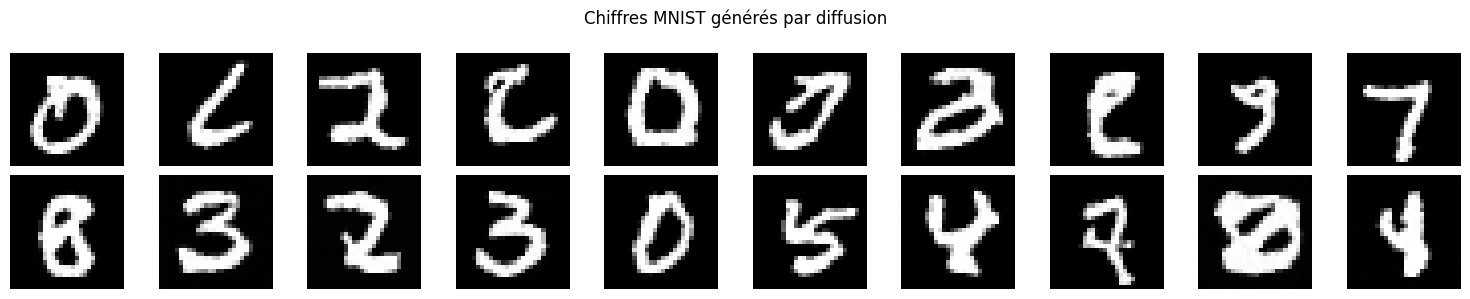

In [37]:
samples = generate_images(diffusion_model, n_samples=20)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        samples[i, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax.axis("off")

plt.suptitle("Chiffres MNIST générés par diffusion")
plt.tight_layout()
plt.show()

## 8. Observer l’évolution de la perte

Ce bloc trace les valeurs enregistrées dans `history`.

- **Axe horizontal** : numéro de l’époque.
- **Axe vertical** : MSE moyenne entre le bruit prédit et le bruit réellement ajouté.

### Comment lire la courbe ?

- **Tendance à la baisse** : le réseau améliore sa prédiction du bruit sur les données d’entraînement.
- **Plateau** : les progrès deviennent faibles avec les réglages actuels.
- **Fluctuations** : elles peuvent provenir des lots, des temps et des bruits tirés au hasard.
- **Hausse persistante ou valeurs non finies** : elles peuvent signaler une instabilité à examiner.

La perte rassemble des situations de difficulté différente, puisque les niveaux de bruit sont échantillonnés aléatoirement.

> Il s’agit d’une perte d’entraînement, pas d’une mesure calculée sur un jeu de validation.

**Pour juger le modèle, il faut compléter la courbe par l’examen de la qualité et de la diversité des images générées.**

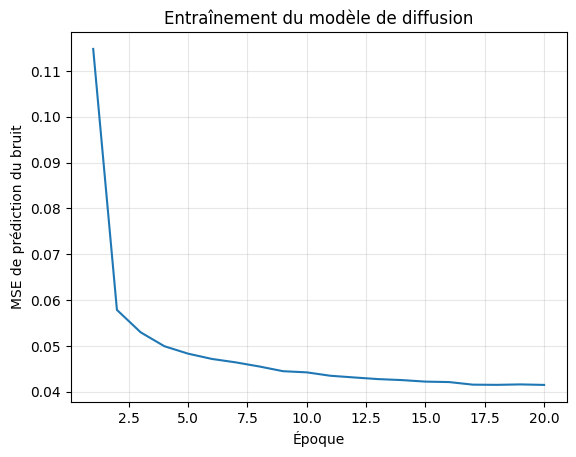

In [38]:
plt.plot(range(1, len(history) + 1), history)
plt.xlabel("Époque")
plt.ylabel("MSE de prédiction du bruit")
plt.title("Entraînement du modèle de diffusion")
plt.grid(alpha=0.3)
plt.show()